# Colombia Saludable · Respuestas del taller

Análisis reproducible de las **14 preguntas** sobre la bodega `colombia_saludable_dw_core_v2`, sin utilizar la
interfaz del proyecto. Las consultas utilizan `etl.DB_Extractor`; Matplotlib y pandas se emplean en esta
capa de respuestas, según el [plan](../planes_y_evidencia/plan_answers.md).

**Lectura de resultados:** aportes recibidos, tarifas estimadas y costos reales son conceptos diferentes.
Los costos reales completos, mora, ocupación real y costo de recetas no pueden obtenerse de los datos existentes.
Cada sección indica su alcance, denominador, filtros y limitaciones. Los diagnósticos son texto parcialmente
clasificado, sin validación clínica; no se presentan tasas de prevalencia ni conclusiones causales.

Ejecutar de arriba abajo con `.venv`. La bodega se consulta en READ ONLY; el cuaderno no ejecuta el ETL,
no se conecta al origen y no muestra personas. Los archivos se exportan por ejecución a
`planes_y_evidencia/respuestas/ejecuciones/<run>/`; un manifiesto final identifica la última ejecución exitosa.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `DB_Extractor.connect`, `DB_Extractor.execute_query`, `DB_Extractor.get_table_names`, `etl.CSV_Loader`, `etl.DB_Extractor`.
- **Fuera del Core y motivo:** Path, dotenv, datetime/ZoneInfo, JSON y hashlib configuran/verifican la ejecución. SQLAlchemy y el driver imponen lectura y timeouts; IPython/Matplotlib preparan presentación. Las consultas de claves/referencias comprueban el contrato lógico existente.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `huellas_bodega` | lee mediante el Core y calcula SHA-256 de los resultados para verificar que no cambió la bodega. |
| `ident` | escapa identificadores SQL del catálogo; no calcula medidas. |
| `limites` | configura timeouts mediante eventos de SQLAlchemy. |
| `literal` | escapa los literales usados por el SQL del cuaderno. |
| `raw` | valida el prefijo de lectura y delega la ejecución a DB_Extractor.execute_query. |
| `solo_lectura` | configura READ ONLY mediante el driver; no ejecuta consultas analíticas. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.


**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `CONTRATO[…].items`, `INDEPENDIENTE.get`, `MANIFEST_CARGA.get`, `RuntimeError`, `ValueError`, `cfg.get`, `int`, `next`, `print`, `re.match`, `s.replace`, `set`, `sorted`, `str`, `str(…).replace`, `str.join`, `str.join(…).encode` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| Archivos, configuración y reproducibilidad | `Path.cwd`, `contextlib.redirect_stdout`, `dotenv_values`, `hashlib.sha256`, `hashlib.sha256(…).hexdigest`, `io.StringIO`, `json.dumps`, `json.loads`, `ruta.is_dir`, `ruta.is_file`, `ruta.read_text`, `sys.path.insert` | Rutas, entorno, manifiestos, fechas de ejecución, versiones o hashes específicos de este proceso; el Core no publica estos manifiestos del taller. |
| Sesiones SQLAlchemy y driver | `conn.exec_driver_sql`, `dbapi.set_session`, `event.listens_for`, `ex.engine.dispose` | Modo de lectura, aislamiento y tiempos límite añadidos a DB_Extractor; no son cargas de datos por fuera del Core. |
| DataFrames y matrices | `df.to_dict` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `matplotlib.use` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

**Estado de esta versión:** ejecutada el 30 de octubre de 2026 sobre `colombia_saludable_dw_core_v2`. Las salidas guardadas corresponden a esta ejecución; las evidencias anteriores se conservaron en `../historial_ejecuciones/20261030T150841/`.


In [1]:
# Preparación y comprobación de la bodega usada para las respuestas.

from pathlib import Path
import os
import sys
import json
import io
import contextlib
import hashlib
import uuid
import textwrap
import re
from datetime import datetime, date
from zoneinfo import ZoneInfo
from decimal import Decimal
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib

matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter
from IPython.display import display, Markdown, Image
from dotenv import dotenv_values
from sqlalchemy import event

# Localizar el repositorio sin depender de la carpeta desde la que se abre el cuaderno.
ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / 'etl').is_dir() and (p / 'colombia_saludable/.env').is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError('Ejecute el cuaderno desde este repositorio.')
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
from etl import (
    DB_Extractor,
    CSV_Loader,
    BasicsTransformOperations as B,
    DataSelect as S,
    TransformOperations as T,
    ConvertOperations as C,
    DataExpresion as X,
)
from etl.schema import missing as nulo

# Preparar las rutas de evidencia y el exportador CSV del Core.
CSV_CORE = CSV_Loader()
BASE = ROOT / 'colombia_saludable'
EVIDENCIA = BASE / 'planes_y_evidencia'
CARGA = EVIDENCIA / 'carga_core'

# Exigir una carga exitosa, conciliada y verificada antes de calcular respuestas.
MANIFEST_CARGA = json.loads((CARGA / 'manifest_carga.json').read_text(encoding='utf8'))
CONTRATO = json.loads((CARGA / 'modelo_bodega.json').read_text(encoding='utf8'))
if MANIFEST_CARGA.get('estado') != 'exitoso' or not MANIFEST_CARGA.get(
    'conciliacion_aprobada'
):
    raise RuntimeError(
        'La carga no está completa y conciliada. No se calcularán respuestas.'
    )
INDEPENDIENTE = json.loads(
    (CARGA / 'verificacion_independiente.json').read_text(encoding='utf8')
)
if (
    INDEPENDIENTE.get('estado') != 'aprobado'
    or INDEPENDIENTE.get('run_carga') != MANIFEST_CARGA['run_id']
):
    raise RuntimeError('Falta verificación independiente de esta carga.')

# Leer la conexión autorizada a la bodega; este cuaderno no consulta el origen.
cfg = dotenv_values(BASE / '.env')
for k in [
    'DB_TYPE',
    'DB_HOST',
    'DB_PORT',
    'DB_USER',
    'DB_PASSWORD',
    'DB_NAME_WAREHOUSE',
]:
    if not cfg.get(k):
        raise ValueError('Falta variable de conexión: ' + k)
if (
    cfg['DB_TYPE'] != 'postgresql'
    or cfg['DB_NAME_WAREHOUSE'] != MANIFEST_CARGA['destino']
):
    raise ValueError('La configuración no corresponde a la bodega autorizada.')

# Conectar con el extractor Core y proteger las sesiones contra escrituras.
ex = DB_Extractor(
    db_type=cfg['DB_TYPE'],
    host=cfg['DB_HOST'],
    port=int(cfg['DB_PORT']),
    user=cfg['DB_USER'],
    password=cfg['DB_PASSWORD'],
    database=cfg['DB_NAME_WAREHOUSE'],
    connect_timeout=5,
)
with contextlib.redirect_stdout(io.StringIO()):
    ex.connect()


@event.listens_for(ex.engine, 'connect')
def solo_lectura(dbapi, registro):
    # Impedir escrituras en las conexiones usadas para responder el taller.
    dbapi.set_session(
        readonly=True, isolation_level='REPEATABLE READ', autocommit=False
    )


@event.listens_for(ex.engine, 'begin')
def limites(conn):
    # Acotar la duración de consultas y bloqueos dentro de cada transacción.
    conn.exec_driver_sql("SET LOCAL statement_timeout = '30s'")
    conn.exec_driver_sql("SET LOCAL lock_timeout = '5s'")


ex.engine.dispose()


def raw(sql):
    # Aceptar únicamente consultas de lectura y ejecutarlas mediante el Core.
    if not re.match(r'^\s*(SELECT|WITH|SHOW)\b', sql, re.I):
        raise ValueError('Solo se permiten consultas de lectura.')
    with contextlib.redirect_stdout(io.StringIO()):
        return ex.execute_query(sql)


def ident(s):
    # Escapar comillas del identificador antes de incorporarlo al SQL.
    return '"' + s.replace('"', '""') + '"'


def literal(s):
    # Escapar comillas simples de un valor antes de incorporarlo al SQL.
    return "'" + str(s).replace("'", "''") + "'"


assert raw('SHOW transaction_read_only').iloc[0, 0] == 'on'
assert raw('SELECT current_database()').iloc[0, 0] == MANIFEST_CARGA['destino']
with contextlib.redirect_stdout(io.StringIO()):
    actuales = set(ex.get_table_names())
assert actuales == set(
    MANIFEST_CARGA['conteos']
), 'Catálogo de bodega distinto de la carga aprobada'
for t, pk in CONTRATO['claves_logicas'].items():
    ks = ', '.join(ident(c) for c in pk)
    sql = (
        f'SELECT COUNT(*) FROM (SELECT {ks} FROM public.{ident(t)} GROUP BY {ks} HAVING'
        ' COUNT(*)>1) x'
    )
    assert int(raw(sql).iloc[0, 0]) == 0, 'Claves repetidas: ' + t
    assert (
        int(raw('SELECT COUNT(*) FROM public.' + ident(t)).iloc[0, 0])
        == MANIFEST_CARGA['conteos'][t]
    ), ('Conteo distinto: ' + t)
for r in CONTRATO['referencias']:
    sql = (
        f"SELECT COUNT(*) FROM public.{ident(r['tabla'])} h WHERE"
        f" h.{ident(r['columna'])} IS NOT NULL AND NOT EXISTS "
    )
    sql += (
        f"(SELECT 1 FROM public.{ident(r['destino'])} d WHERE"
        f" d.{ident(r['clave_destino'])}=h.{ident(r['columna'])})"
    )
    assert int(raw(sql).iloc[0, 0]) == 0, 'Relación sin correspondencia'


def huellas_bodega():
    # Calcular una huella por tabla para comparar la bodega al inicio y al cierre.
    resultado = {}
    for t in sorted(actuales):
        df = raw('SELECT * FROM public.' + ident(t))
        filas = sorted(
            json.dumps(r, sort_keys=True, default=str, ensure_ascii=False)
            for r in df.to_dict('records')
        )
        resultado[t] = hashlib.sha256(('\n'.join(filas)).encode()).hexdigest()
    return resultado


# Comparar la bodega con la carga aprobada y guardar su huella inicial.
HUELLAS_INICIO = huellas_bodega()
APROBADA = json.loads((CARGA / 'prueba_reejecucion.json').read_text(encoding='utf8'))
assert (
    APROBADA.get('run_carga') == MANIFEST_CARGA['run_id']
), 'La comprobación de reejecución no corresponde a esta carga.'
assert (
    HUELLAS_INICIO == APROBADA['huellas_bodega_sha256']
), 'La bodega cambió: conciliar antes de responder.'
print(
    'Carga verificada:',
    MANIFEST_CARGA['run_id'],
    '| 17 tablas | 42 referencias | READ ONLY',
)


Carga verificada: 20261030T150852_0357772f | 17 tablas | 42 referencias | READ ONLY


## Parámetros y convenciones

Por defecto se analiza el calendario completo **2006–2008**. Puede ajustar las fechas, los tipos de atención,
IPS, departamento, sexo registrado y grupo de edad. La fecha se interpreta según la pregunta: solicitud para
demanda, atención para prestación/espera, pago para aportes, fórmula para recetas y retiro para salidas.

IPS/departamento corresponden a la **IPS asociada actualmente al médico** en actividad clínica/recetas,
y a la **IPS de afiliación** en pagos/perfiles/retiros. No son residencia ni regional administrativa.
El filtro etario usa edad al evento de cada hecho; los perfiles usan una fecha de corte histórica explícita.
Los tipos de atención solo filtran eventos asistenciales, no aportes o recetas. La comparación de utilización
con afiliados registrados se omite con filtros de edad/geografía, cuyos denominadores no son equivalentes.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `ConvertOperations.fill_nulls`, `DB_Extractor.execute_query`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** Python/JSON valida parámetros y registra la ejecución. SQL CASE/AGE y CTE expresan filtros/poblaciones; Decimal formatea importes. pandas head e IPython conservan una vista HTML de tablas: los head del Core devuelven texto, no un DataFrame. pandas/NumPy y Matplotlib preparan/dibujan gráficos; el Core no renderiza imágenes.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `completar_matriz` | delega los ceros de matrices de visualización a ConvertOperations.fill_nulls; no imputa medidas desconocidas. |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `figura` | compone, guarda y muestra imágenes con Matplotlib/IPython; el Core no renderiza gráficos Python. |
| `filtros` | genera condiciones SQL de fechas y segmentos; DB_Extractor las ejecuta. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `grupo_sql` | genera el CASE de los grupos etarios con las reglas explícitas del taller. |
| `literal` | escapa los literales usados por el SQL del cuaderno. |
| `num` | usa missing del Core y aproxima números a float solo para visualización. |
| `raw` | valida el prefijo de lectura y delega la ejecución a DB_Extractor.execute_query. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**Expresiones de fila:** 1 lambda(s) escritas aquí. Su fórmula o condición pertenece al cuaderno; cuando se pasan a un transformador, el Core realiza la operación tabular. No se presentan como funciones propias del Core.

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `CONTROLES.append`, `ORDEN_EDAD.index`, `PARAMETROS.items`, `ValueError`, `condiciones.append`, `float`, `format`, `format(…).replace`, `format(…).replace(…).replace`, `format(…).replace(…).replace(…).replace`, `globals`, `globals(…).update`, `isinstance`, `len`, `max`, `min`, `set`, `str`, `str.join`, `textwrap.fill` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| Archivos, configuración y reproducibilidad | `Path`, `Path(…).read_text`, `SALIDA.mkdir`, `ZoneInfo`, `datetime.now`, `datetime.now(…).isoformat`, `datetime.now(…).strftime`, `json.loads`, `os.environ.get`, `uuid.uuid4` | Rutas, entorno, manifiestos, fechas de ejecución, versiones o hashes específicos de este proceso; el Core no publica estos manifiestos del taller. |
| DataFrames y matrices | `df.head`, `df.head(…).copy`, `pd.DataFrame` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `Image`, `Markdown`, `MaxNLocator`, `ax.barh`, `ax.grid`, `ax.invert_yaxis`, `ax.set_xlabel`, `ax.xaxis.set_major_locator`, `display`, `fig.savefig`, `fig.suptitle`, `fig.text`, `fig.tight_layout`, `plt.close`, `plt.rcParams.update`, `plt.subplots` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |
| Expresiones escalares del dominio | `Decimal`, `date.fromisoformat` | Normalización Unicode, fechas, duraciones, claves y redondeo Decimal de las reglas explícitas. Se aplican con callables Core cuando corresponden a columnas; no son funciones propias del Core. |

In [2]:
# Parámetros, población analítica y utilidades de presentación.

# Parámetros editables. El lanzador puede proporcionar un JSON sin credenciales.
FECHA_INICIO = '2006-01-01'
FECHA_FIN = '2008-12-31'
TIPOS_ATENCION = []  # [] = todos; cita_general, urgencia, hospitalizacion, remision
IPS = []  # Códigos de dim_ips, [] = todas
DEPARTAMENTOS = []  # Etiquetas normalizadas, [] = todos
SEXOS = []  # f / m; [] = todos
GRUPOS_EDAD = []  # 0-4, 5-14, 15-24, 25-44, 45-64, 65+, desconocido
TOP_N = 10

# Permitir ajustes externos únicamente para los parámetros admitidos.
archivo_parametros = os.environ.get('COLOMBIA_SALUDABLE_RESPUESTAS_PARAMETROS')
if archivo_parametros:
    valores = json.loads(Path(archivo_parametros).read_text(encoding='utf8'))
    permitidos = {
        'FECHA_INICIO',
        'FECHA_FIN',
        'TIPOS_ATENCION',
        'IPS',
        'DEPARTAMENTOS',
        'SEXOS',
        'GRUPOS_EDAD',
        'TOP_N',
    }
    if set(valores) - permitidos:
        raise ValueError('Hay parámetros no permitidos.')
    globals().update(valores)

# Validar el intervalo y el tamaño de los rankings antes de consultar hechos.
FI = date.fromisoformat(FECHA_INICIO)
FF = date.fromisoformat(FECHA_FIN)
assert FI <= FF, 'Intervalo invertido'
assert isinstance(TOP_N, int) and not isinstance(TOP_N, bool) and 1 <= TOP_N <= 20

# Rechazar filtros que no pertenecen a los catálogos de esta bodega.
catalogo_ips = raw('SELECT ips_id,departamento FROM public.dim_ips')
for v, validos in [
    (TIPOS_ATENCION, {'cita_general', 'urgencia', 'hospitalizacion', 'remision'}),
    (IPS, set(catalogo_ips.ips_id)),
    (DEPARTAMENTOS, set(catalogo_ips.departamento)),
    (SEXOS, {'f', 'm'}),
    (GRUPOS_EDAD, {'0-4', '5-14', '15-24', '25-44', '45-64', '65+', 'desconocido'}),
]:
    assert isinstance(v, list) and set(v) <= validos, 'Filtro fuera del catálogo'

# Fijar un corte histórico que no supere la última fecha observada.
ULTIMA_FECHA = raw(
    """SELECT MAX(f) AS fecha FROM (
 SELECT MAX(fecha_atencion) AS f FROM public.fact_atencion UNION ALL SELECT MAX(fecha_pago) FROM public.fact_pago
 UNION ALL SELECT MAX(fecha_formula) FROM public.fact_formula UNION ALL SELECT MAX(fecha_retiro) FROM public.fact_retiro) x"""
).iloc[0, 0]
CORTE = min(FF, date.fromisoformat(str(ULTIMA_FECHA)[:10]))
PARAMETROS = {
    k: globals()[k]
    for k in [
        'FECHA_INICIO',
        'FECHA_FIN',
        'TIPOS_ATENCION',
        'IPS',
        'DEPARTAMENTOS',
        'SEXOS',
        'GRUPOS_EDAD',
        'TOP_N',
    ]
}

# Crear una carpeta por ejecución y registros separados de tablas, figuras y controles.
RUN = (
    datetime.now(ZoneInfo('America/Bogota')).strftime('%Y%m%dT%H%M%S')
    + '_'
    + uuid.uuid4().hex[:8]
)
SALIDA = EVIDENCIA / 'respuestas' / 'ejecuciones' / RUN
SALIDA.mkdir(parents=True, exist_ok=False)
RESULTADOS = {}
TABLAS = {}
FIGURAS = {}
CONSULTAS = {}
CONTROLES = []
INICIO = datetime.now(ZoneInfo('America/Bogota')).isoformat()


def grupo_sql(e):
    # Construir el CASE de edad con los mismos intervalos utilizados en el ETL.
    return (
        f"CASE WHEN ({e}) IS NULL OR ({e})<0 THEN 'desconocido' WHEN ({e})<=4 THEN"
        f" '0-4' WHEN ({e})<=14 THEN '5-14' WHEN ({e})<=24 THEN '15-24' WHEN ({e})<=44"
        f" THEN '25-44' WHEN ({e})<=64 THEN '45-64' ELSE '65+' END"
    )


def filtros(f, grupo, tipos=None):
    # Combinar solo los filtros activos; una lista vacía significa todos los valores.
    condiciones = []
    if f:
        condiciones.append(
            f"{f} BETWEEN DATE {literal(FECHA_INICIO)} AND DATE {literal(FECHA_FIN)}"
        )
    for exp, valores in [
        ('p.sexo', SEXOS),
        (grupo, GRUPOS_EDAD),
        ('i.ips_id', IPS),
        ('i.departamento', DEPARTAMENTOS),
        (tipos, TIPOS_ATENCION if tipos else []),
    ]:
        if valores:
            condiciones.append(
                exp + ' IN (' + ','.join(literal(v) for v in valores) + ')'
            )
    return ' AND '.join(condiciones) or 'TRUE'


# Definir las selecciones comunes: atención, solicitudes, recetas, pagos y retiros.
EDAD_CORTE = f"EXTRACT(YEAR FROM AGE(DATE {literal(CORTE)},p.fecha_nacimiento))::int"

# A/S usan fechas distintas; PC representa el perfil de cotizantes al corte histórico.
BASE_SQL = f"""WITH
 A AS (SELECT a.*,p.sexo,p.estrato_familiar,p.tipo_cotizante_titular,i.nombre AS ips_nombre,i.departamento,i.municipio
   FROM public.fact_atencion a JOIN public.dim_paciente p ON p.paciente_id=a.paciente_id
   JOIN public.dim_ips i ON i.ips_id=a.ips_medico_asociado_id
   WHERE {filtros('a.fecha_atencion','a.grupo_etario_atencion','a.tipo_atencion')}),
 S AS (SELECT a.*,p.sexo,p.estrato_familiar,p.tipo_cotizante_titular,i.nombre AS ips_nombre,i.departamento,i.municipio
   FROM public.fact_atencion a JOIN public.dim_paciente p ON p.paciente_id=a.paciente_id
   JOIN public.dim_ips i ON i.ips_id=a.ips_medico_asociado_id
   WHERE {filtros('a.fecha_solicitud','a.grupo_etario_solicitud','a.tipo_atencion')}),
 F AS (SELECT f.*,p.sexo,i.departamento,i.municipio FROM public.fact_formula f
   JOIN public.dim_paciente p ON p.paciente_id=f.paciente_id JOIN public.dim_ips i ON i.ips_id=f.ips_medico_asociado_id
   WHERE {filtros('f.fecha_formula','f.grupo_etario')}),
 P AS (SELECT v.*,p.sexo,i.departamento,i.municipio FROM public.fact_pago v
   JOIN public.dim_paciente p ON p.paciente_id=v.paciente_id JOIN public.dim_ips i ON i.ips_id=v.ips_afiliacion_id
   WHERE {filtros('v.fecha_pago',grupo_sql('EXTRACT(YEAR FROM AGE(v.fecha_pago,p.fecha_nacimiento))'))}),
 R AS (SELECT r.*,p.sexo,p.estrato_propio,p.tipo_cotizante_propio,i.departamento,i.municipio FROM public.fact_retiro r
   JOIN public.dim_paciente p ON p.paciente_id=r.paciente_id JOIN public.dim_ips i ON i.ips_id=r.ips_afiliacion_id
   WHERE {filtros('r.fecha_retiro',grupo_sql('r.edad_al_retiro'))}),
 D AS (SELECT * FROM public.dim_fecha WHERE fecha::date BETWEEN DATE {literal(FECHA_INICIO)} AND DATE {literal(FECHA_FIN)}),
 PC AS (SELECT p.*, {EDAD_CORTE} AS edad_corte,{grupo_sql(EDAD_CORTE)} AS grupo_corte,
   CASE WHEN p.proviene_otra_eps_propio IS TRUE THEN 'Proviene de otra EPS'
        WHEN p.proviene_otra_eps_propio IS FALSE THEN 'No proviene de otra EPS' ELSE 'Sin dato' END AS procedencia
   FROM public.dim_paciente p JOIN public.dim_ips i ON i.ips_id=p.ips_afiliacion_id
   WHERE p.tipo_registro='cotizante' AND p.fecha_afiliacion_propia::date<=DATE {literal(CORTE)}
     AND {filtros(None,grupo_sql(EDAD_CORTE))})
"""


def consultar(nombre, sql):
    # Guardar el SQL reproducible junto con las CTE comunes y ejecutar la lectura.
    CONSULTAS[nombre] = BASE_SQL + sql
    return raw(BASE_SQL + sql)


def tabla(nombre, df, limite=15):
    # Rechazar identificadores personales, exportar el agregado y mostrar una vista
    # breve.
    assert not set(df.columns) & {
        'paciente_id',
        'usuario_origen',
        'familia_id',
        'medico_id',
        'id_transaccion',
        'codigo_formula',
        'atencion_id',
    }, 'No exportar identificadores personales'
    CSV_CORE.save_csv(
        df,
        str(SALIDA / (nombre + '.csv')),
        index=False,
        encoding='utf-8-sig',
        lineterminator='\n',
    )
    TABLAS[nombre] = df
    display(df.head(limite))
    if len(df) > limite:
        display(
            Markdown(
                f'Tabla completa: **{len(df):,} filas agregadas** en `{nombre}.csv`.'
            )
        )
    return df


def num(x):
    # Aproximar a float solo para dibujar; conservar desconocidos como NaN.
    return float(x) if x is not None and not nulo(x) else np.nan


def fmt(x, dec=0):
    # Dar formato de presentación sin modificar los valores de las tablas exportadas.
    if nulo(x):
        return 'sin dato'
    return (
        format(Decimal(str(x)), f',.{dec}f')
        .replace(',', '~')
        .replace('.', ',')
        .replace('~', '.')
    )


def concluir(pid, texto, estado='parcial'):
    # Registrar la interpretación y su alcance junto al identificador de la pregunta.
    RESULTADOS[pid] = {'estado': estado, 'interpretacion': texto}
    display(Markdown('**Respuesta e interpretación.** ' + texto))


def comprobar(nombre, condicion):
    # Detener la ejecución ante diferencias y registrar solo controles aprobados.
    assert condicion, nombre
    CONTROLES.append({'control': nombre, 'ok': True})


# Mantener el mismo estilo y orden de categorías en todos los gráficos.
COLOR = ['#126D82', '#D88532', '#3D4C68', '#7C6CA6', '#4F8E74']
plt.rcParams.update(
    {
        'font.family': 'DejaVu Sans',
        'font.size': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.titleweight': 'bold',
        'axes.labelcolor': '#243342',
        'text.color': '#243342',
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'grid.alpha': 0.18,
        'axes.axisbelow': True,
        'savefig.dpi': 160,
    }
)
ORDEN_EDAD = ['0-4', '5-14', '15-24', '25-44', '45-64', '65+', 'desconocido']
PERIODO = f'{FECHA_INICIO} a {FECHA_FIN}'


def figura(nombre, fig, titulo, nota):
    # Añadir contexto al gráfico, exportarlo como PNG y liberar la figura de Matplotlib.
    fig.suptitle(textwrap.fill(titulo, 100), fontsize=13, fontweight='bold', y=1.00)
    fig.tight_layout(rect=(0, 0.08, 1, 0.94), pad=1.7)
    pie = f'Período: {PERIODO}. ' + nota
    fig.text(
        0.02, 0.01, textwrap.fill(pie, 145), fontsize=8, color='#526171', va='bottom'
    )
    path = SALIDA / (nombre + '.png')
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    FIGURAS[nombre] = {'archivo': path.name, 'titulo': titulo, 'nota': nota}
    display(Image(filename=str(path)))


def completar_matriz(frame):
    # Solo matrices de visualización: sus combinaciones ausentes representan cero.
    # Rellenar únicamente combinaciones ausentes de matrices de visualización.
    for columna in frame.columns:
        frame = C.fill_nulls(frame, columna, 0, show=0)
    return frame


def barras(nombre, df, etiqueta, valor, titulo, unidad, nota, limite=None, escala=1):
    # Preparar el subconjunto visible y conservar el orden natural de los grupos de
    # edad.
    if df.empty:
        display(
            Markdown(
                'Sin observaciones para esta selección. No se genera una gráfica de'
                ' ceros.'
            )
        )
        return
    d = df.head(limite or TOP_N).copy()
    if not d.empty and set(d[etiqueta]) <= set(ORDEN_EDAD):
        d = B.add_new_column(
            d, '_orden_edad', lambda r: ORDEN_EDAD.index(r[etiqueta]), show=0
        )
        d = T.sort_by(d, '_orden_edad', show=0)
        d = S.select_columns(d, '_orden_edad', complement=True, show=0)
    fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(d) + 1.6)))
    labels = [textwrap.fill(str(x), 42) for x in d[etiqueta]]
    ax.barh(labels, [num(x) / escala for x in d[valor]], color=COLOR[0])
    ax.invert_yaxis()
    ax.set_xlabel(unidad)
    ax.grid(axis='x')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    figura(nombre, fig, titulo, nota)


display(
    Markdown(
        f'**Período:** {PERIODO}. **Corte de perfiles:** {CORTE}. **Run de carga:**'
        f' `{MANIFEST_CARGA["run_id"]}`.'
    )
)
display(
    pd.DataFrame([{'parametro': k, 'valor': str(v)} for k, v in PARAMETROS.items()])
)


**Período:** 2006-01-01 a 2008-12-31. **Corte de perfiles:** 2008-12-09. **Run de carga:** `20261030T150852_0357772f`.

,parametro,valor
0,FECHA_INICIO,2006-01-01
1,FECHA_FIN,2008-12-31
2,TIPOS_ATENCION,[]
3,IPS,[]
4,DEPARTAMENTOS,[]
5,SEXOS,[]
6,GRUPOS_EDAD,[]
7,TOP_N,10


## Calidad y cobertura de la selección

Las exclusiones de espera no eliminan eventos de otras métricas. “Con tarifa” significa que se conoce una
tarifa de servicio en catálogo; no que haya una factura o costo real. Los filtros y fechas pueden cambiar
el número de exclusiones respecto a los 497 registros negativos de la carga completa.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `CSV_Loader.save_csv`, `DB_Extractor.execute_query`.
- **Fuera del Core y motivo:** COUNT/FILTER/SUM y ROUND en SQL definen cobertura y totales. Python comprueba su conciliación e IPython presenta el alcance; las consultas y los CSV usan el Core.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `int` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| Dibujo e IPython | `Markdown`, `display` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

In [3]:
# Calidad y cobertura del subconjunto seleccionado.


# Contar esperas válidas/excluidas y eventos con tarifa sin eliminar hechos.
calidad = tabla(
    'calidad_seleccion',
    consultar(
        'calidad_seleccion',
        """SELECT COUNT(*) AS eventos,
 COUNT(DISTINCT paciente_id) AS pacientes_atendidos,COUNT(*) FILTER(WHERE espera_negativa) AS esperas_negativas,
 COUNT(*) FILTER(WHERE espera_incompleta) AS esperas_incompletas,
 COUNT(*) FILTER(WHERE espera_valida_min IS NOT NULL) AS esperas_validas,
 COUNT(*) FILTER(WHERE tarifa_informada) AS eventos_con_tarifa,
 ROUND(100.0*COUNT(*) FILTER(WHERE tarifa_informada)/NULLIF(COUNT(*),0),2) AS cobertura_tarifa_pct FROM A""",
    ),
)

# Calcular los denominadores que se reutilizan en las preguntas.
totales = consultar(
    'totales_seleccion',
    """SELECT (SELECT COUNT(*) FROM S) AS solicitudes,
 (SELECT COUNT(*) FROM F) AS formulas,(SELECT COUNT(*) FROM P) AS pagos,
 (SELECT SUM(valor_aporte)::text FROM P) AS aportes,(SELECT COUNT(*) FROM R) AS retiros""",
).iloc[0]
comprobar(
    'esperas_validas_y_excluidas_concilian',
    int(calidad.iloc[0].eventos)
    == int(calidad.iloc[0].esperas_validas)
    + int(calidad.iloc[0].esperas_negativas)
    + int(calidad.iloc[0].esperas_incompletas),
)
display(
    Markdown(
        'Los gráficos describen la selección mostrada arriba. No hay un snapshot global'
        ' entre consultas; se comparan huellas de la bodega al inicio y al cierre.'
    )
)


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\calidad_seleccion.csv (1 registros, 7 columnas)


,eventos,pacientes_atendidos,esperas_negativas,esperas_incompletas,esperas_validas,eventos_con_tarifa,cobertura_tarifa_pct
0,21207,504,497,0,20710,16742,78.95


Los gráficos describen la selección mostrada arriba. No hay un snapshot global entre consultas; se comparan huellas de la bodega al inicio y al cierre.

## P01. Tiempo promedio de espera de citas y cirugías

Se calcula solicitud/remisión a atención, no una fecha certificada de asignación. Se muestran conteo válido,
excluidos, media, mediana y percentil 90. Cirugía utiliza el mapeo explícito de `dim_servicio`.
Las unidades de tabla son minutos; los gráficos convierten a horas.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL AVG, PERCENTILE_CONT y CASE calcula estadísticos/tramos; pandas groupby/set_index/reindex alinea las barras sin transformar los importes. NumPy y Matplotlib dibujan; Python compone la interpretación.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `figura` | compone, guarda y muestra imágenes con Matplotlib/IPython; el Core no renderiza gráficos Python. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `num` | usa missing del Core y aproxima números a float solo para visualización. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `enumerate`, `range`, `str.join` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| DataFrames y matrices | `g.set_index`, `g.set_index(…)[…].reindex`, `np.arange`, `p01.to_dict`, `p01hist.groupby` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `ax.bar`, `ax.grid`, `ax.legend`, `ax.set_xticks`, `ax.set_ylabel`, `plt.subplots` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p01_esperas.csv (2 registros, 7 columnas)


,servicio,eventos,validos,excluidos,media_min,mediana_min,p90_min
0,Cirugía (remisión),960,948,12,12445.83,4320.0,34560.0
1,Cita general,3013,3013,0,3863.78,3909.0,6583.4


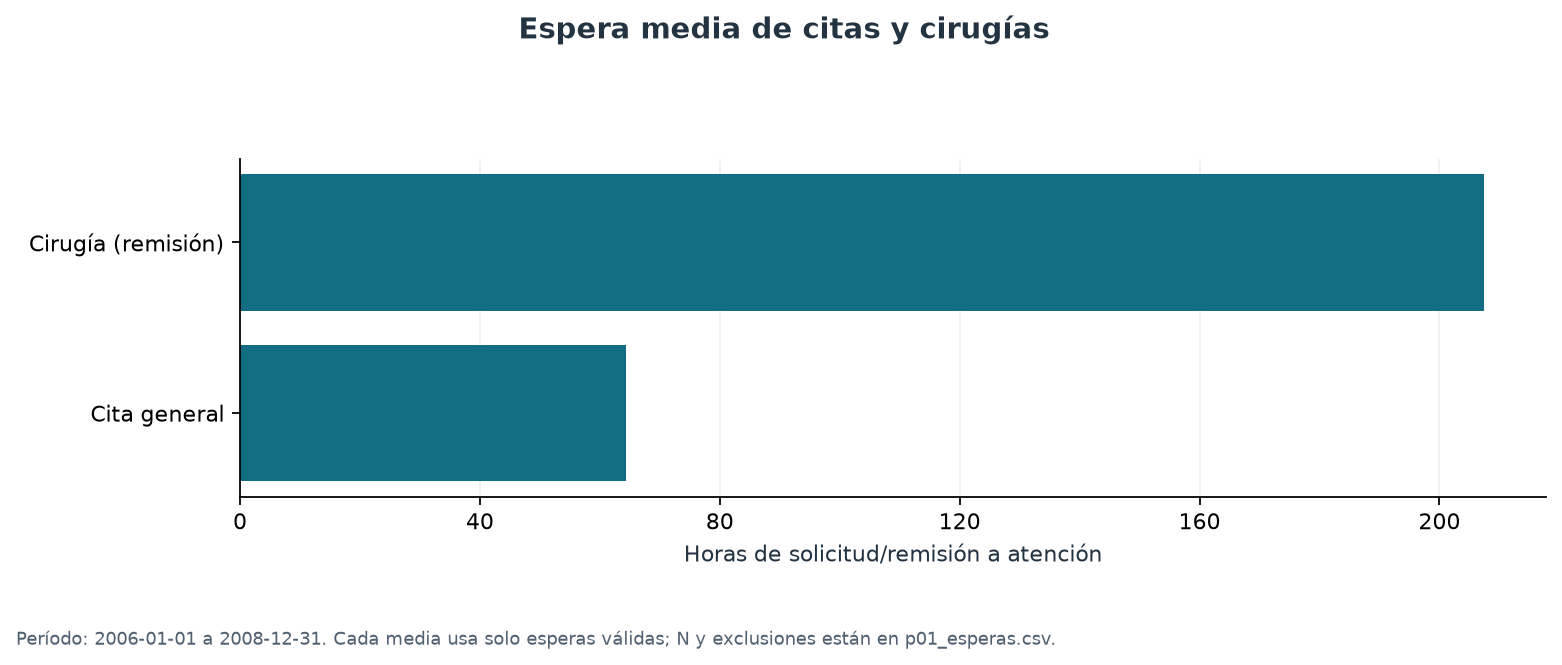

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p01_distribucion_espera.csv (10 registros, 3 columnas)


,servicio,tramo,eventos
0,Cirugía (remisión),1,375
1,Cirugía (remisión),2,10
2,Cirugía (remisión),3,1
3,Cirugía (remisión),4,58
4,Cirugía (remisión),5,124
5,Cirugía (remisión),6,136
6,Cirugía (remisión),7,244
7,Cita general,3,533
8,Cita general,4,1414
9,Cita general,5,1066


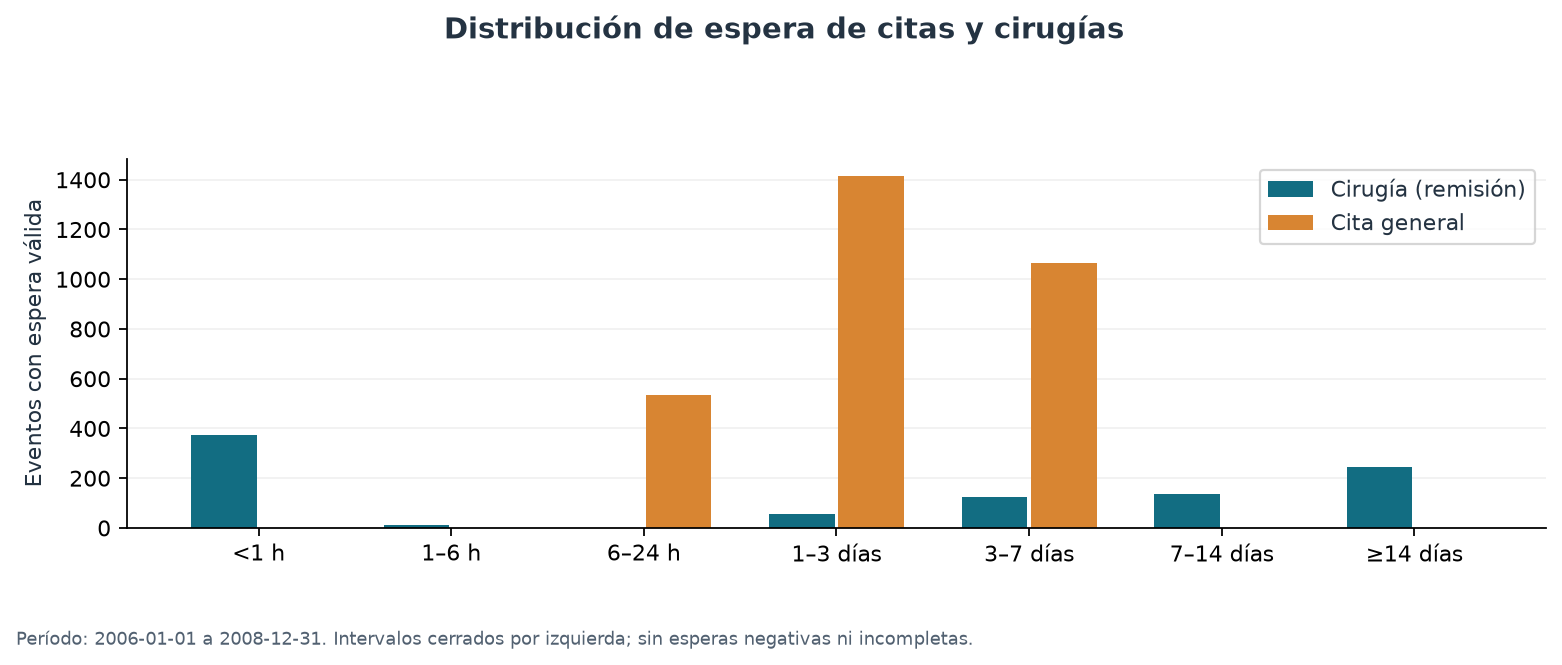

**Respuesta e interpretación.** Cirugía (remisión): espera media 207,43 horas y mediana 72,00 horas; 948 válidos y 12 excluidos; Cita general: espera media 64,40 horas y mediana 65,15 horas; 3.013 válidos y 0 excluidos. No es tiempo certificado desde asignación; las esperas negativas se mantienen como defectos de calidad.

In [4]:
# P01: espera de citas y cirugías.


# Calcular media, mediana y percentil 90 usando solo esperas válidas.
p01 = tabla(
    'p01_esperas',
    consultar(
        'p01_esperas',
        """SELECT
 CASE WHEN tipo_atencion='cita_general' THEN 'Cita general' ELSE 'Cirugía (remisión)' END AS servicio,
 COUNT(*) AS eventos,COUNT(espera_valida_min) AS validos,
 COUNT(*)-COUNT(espera_valida_min) AS excluidos,
 ROUND(AVG(espera_valida_min),2) AS media_min,
 ROUND((PERCENTILE_CONT(0.5) WITHIN GROUP(ORDER BY espera_valida_min))::numeric,2) AS mediana_min,
 ROUND((PERCENTILE_CONT(0.9) WITHIN GROUP(ORDER BY espera_valida_min))::numeric,2) AS p90_min
 FROM A WHERE tipo_atencion='cita_general' OR tipo_servicio='cirugia' GROUP BY 1 ORDER BY 1""",
    ),
)
barras(
    'p01_media_espera',
    p01,
    'servicio',
    'media_min',
    'Espera media de citas y cirugías',
    'Horas de solicitud/remisión a atención',
    'Cada media usa solo esperas válidas; N y exclusiones están en p01_esperas.csv.',
    escala=60,
)

# Separar las esperas válidas en tramos para mostrar su distribución.
p01hist = tabla(
    'p01_distribucion_espera',
    consultar(
        'p01_distribucion_espera',
        """SELECT
 CASE WHEN tipo_atencion='cita_general' THEN 'Cita general' ELSE 'Cirugía (remisión)' END AS servicio,
 CASE WHEN espera_valida_min<60 THEN 1 WHEN espera_valida_min<360 THEN 2 WHEN espera_valida_min<1440 THEN 3
 WHEN espera_valida_min<4320 THEN 4 WHEN espera_valida_min<10080 THEN 5 WHEN espera_valida_min<20160 THEN 6 ELSE 7 END AS tramo,
 COUNT(*) AS eventos FROM A WHERE espera_valida_min IS NOT NULL
 AND (tipo_atencion='cita_general' OR tipo_servicio='cirugia') GROUP BY 1,2 ORDER BY 1,2""",
    ),
)
if not p01hist.empty:
    fig, ax = plt.subplots(figsize=(10, 4))
    tramos = [
        '<1 h',
        '1–6 h',
        '6–24 h',
        '1–3 días',
        '3–7 días',
        '7–14 días',
        '≥14 días',
    ]
    for j, (s, g) in enumerate(p01hist.groupby('servicio')):
        vals = g.set_index('tramo')['eventos'].reindex(range(1, 8), fill_value=0)
        ax.bar(np.arange(7) + j * 0.36, vals, width=0.34, label=s, color=COLOR[j])
    ax.set_xticks(np.arange(7) + 0.18, tramos)
    ax.set_ylabel('Eventos con espera válida')
    ax.legend()
    ax.grid(axis='y')
    figura(
        'p01_distribucion',
        fig,
        'Distribución de espera de citas y cirugías',
        'Intervalos cerrados por izquierda; sin esperas negativas ni incompletas.',
    )

# Interpretar las cifras incluyendo el número de observaciones excluidas.
frases = [
    f"{r['servicio']}: espera media {fmt(num(r['media_min'])/60,2)} horas y mediana"
    f" {fmt(num(r['mediana_min'])/60,2)} horas; {fmt(r['validos'])} válidos y"
    f" {fmt(r['excluidos'])} excluidos"
    for r in p01.to_dict('records')
]
concluir(
    'P01',
    (
        '; '.join(frases)
        + '. No es tiempo certificado desde asignación; las esperas negativas se'
        ' mantienen como defectos de calidad.'
        if frases
        else 'No hay citas o cirugías en esta selección.'
    ),
)


## P02. Prestadores, aportes y estimación parcial por familia

Se cuentan eventos y pacientes distintos por prestador asociado al médico. Los aportes se agrupan antes
de consultar otras tablas, evitando multiplicación por beneficiarios. Las tablas por afiliado/familia muestran
posiciones anónimas de ranking, sin cédulas ni identificadores personales. Ciudad/departamento de los aportes
corresponden a la IPS de afiliación. No hay regional administrativa ni costo familiar real.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL GROUP BY, SUM, COUNT DISTINCT y ROW_NUMBER define rankings/agregados. Decimal y sum comprueban importes exactos; las métricas monetarias no se pasan por get_column_metrics del Core porque convierte a números pandas y no garantiza la misma precisión Decimal.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `len`, `sum` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| Expresiones escalares del dominio | `Decimal` | Normalización Unicode, fechas, duraciones, claves y redondeo Decimal de las reglas explícitas. Se aplican con callables Core cuando corresponden a columnas; no son funciones propias del Core. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p02_prestadores.csv (60 registros, 5 columnas)


,prestador,departamento,municipio,eventos,pacientes
0,Hospital Isaías Duarte Cancio,valle del cauca,cali,1259,272
1,Hospital San Juan de Dios,valle del cauca,cali,1139,247
2,Clinica Valle del Lili,valle del cauca,cali,1075,231
3,Hospital Universitario del Valle Evaristo García,valle del cauca,cali,1075,280
4,Clinica de Occidente,valle del cauca,cali,1050,237
5,Hospital Infantil Clínica Noel,valle del cauca,cali,998,276
6,Hospital La Buena Esperanza de Yumbo,valle del cauca,yumbo,744,206
7,Hospital San Cristóbal,cundinamarca,bogota,691,224
8,Hospital Isaías Duarte Cancio,cundinamarca,bogota,642,239
9,Hospital San Francisco de Asis,choco,quibdó,626,214


Tabla completa: **60 filas agregadas** en `p02_prestadores.csv`.

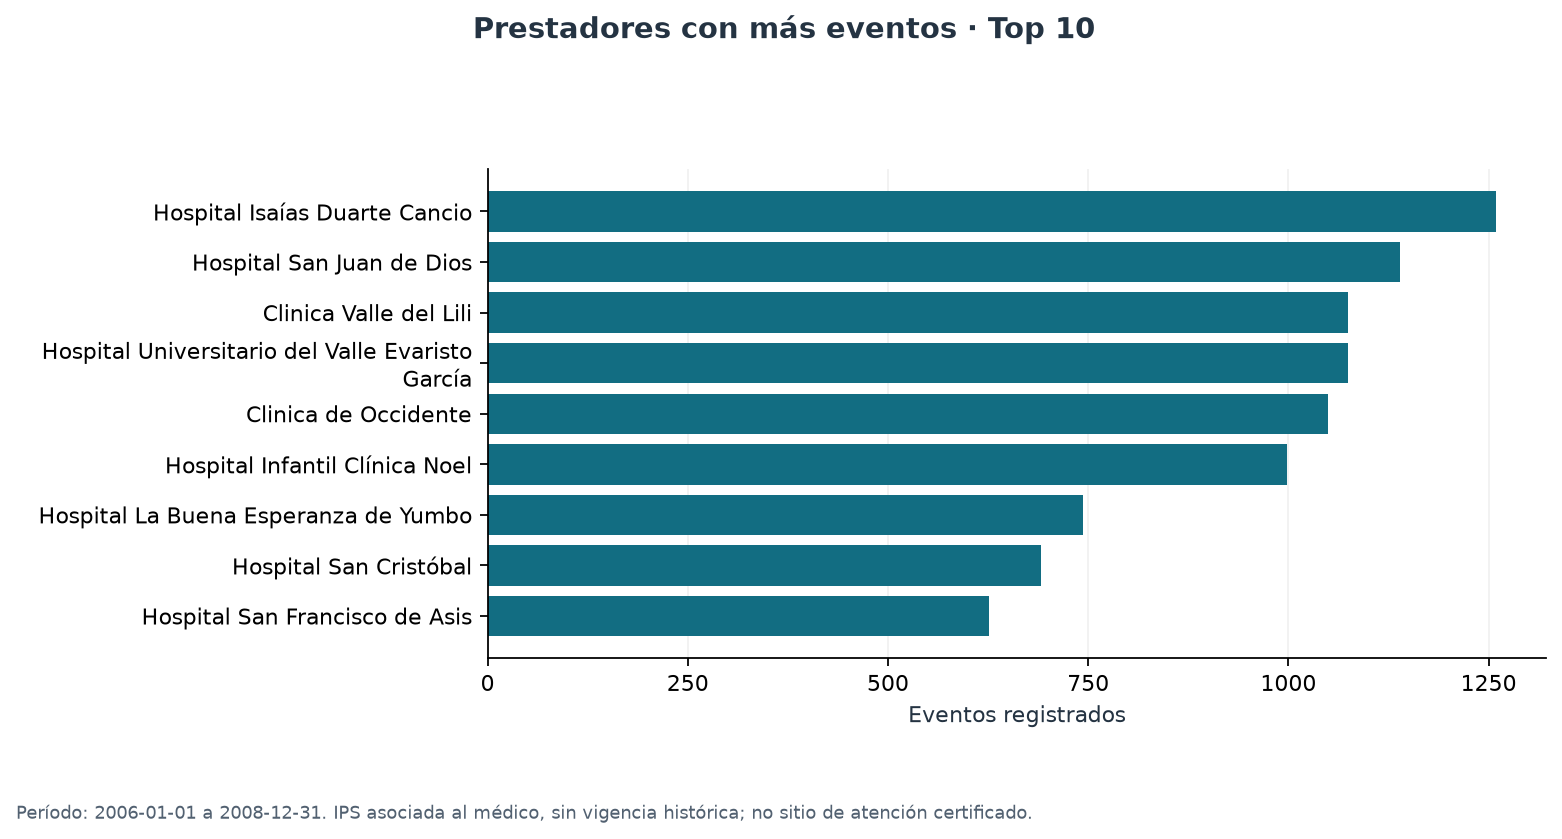

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p02_aportes_afiliado_anonimo.csv (1100 registros, 3 columnas)


,posicion,transacciones,aporte_total
0,1,32,46831970.00
1,2,32,44959835.00
2,3,33,44389095.00
3,4,30,43970500.00
4,5,32,43075550.00
5,6,32,43074405.00
6,7,29,42533540.00
7,8,33,42461995.00
8,9,33,42452140.00
9,10,30,42204900.00


Tabla completa: **1,100 filas agregadas** en `p02_aportes_afiliado_anonimo.csv`.

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p02_aportes_familia_anonima.csv (1100 registros, 4 columnas)


,posicion,transacciones,aporte_total,numero_miembros
0,1,32,46831970.00,5
1,2,32,44959835.00,2
2,3,33,44389095.00,2
3,4,30,43970500.00,2
4,5,32,43075550.00,4
5,6,32,43074405.00,2
6,7,29,42533540.00,1
7,8,33,42461995.00,2
8,9,33,42452140.00,7
9,10,30,42204900.00,2


...

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p02_aportes_departamento.csv (7 registros, 3 columnas)


,departamento,transacciones,aporte_total
0,cundinamarca,5977,2070868713.00
1,antioquia,3633,1492261380.00
2,valle del cauca,4179,1432131658.00
3,meta,2884,1149282503.00
4,caqueta,2040,813777447.00
5,cordoba,1716,801060654.00
6,choco,2509,789038794.00


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p02_tarifa_familiar_anonima.csv (291 registros, 4 columnas)


,posicion,remisiones,miembros_con_remision,tarifa_total
0,1,381,5,132683329.00
1,2,275,4,119042923.00
2,3,309,5,109984951.00
3,4,301,4,103358161.00
4,5,289,6,91403946.00
5,6,240,5,85109850.00
6,7,294,5,81501217.00
7,8,211,4,77606775.00
8,9,307,6,71072436.00
9,10,167,6,70398547.00


Tabla completa: **291 filas agregadas** en `p02_tarifa_familiar_anonima.csv`.

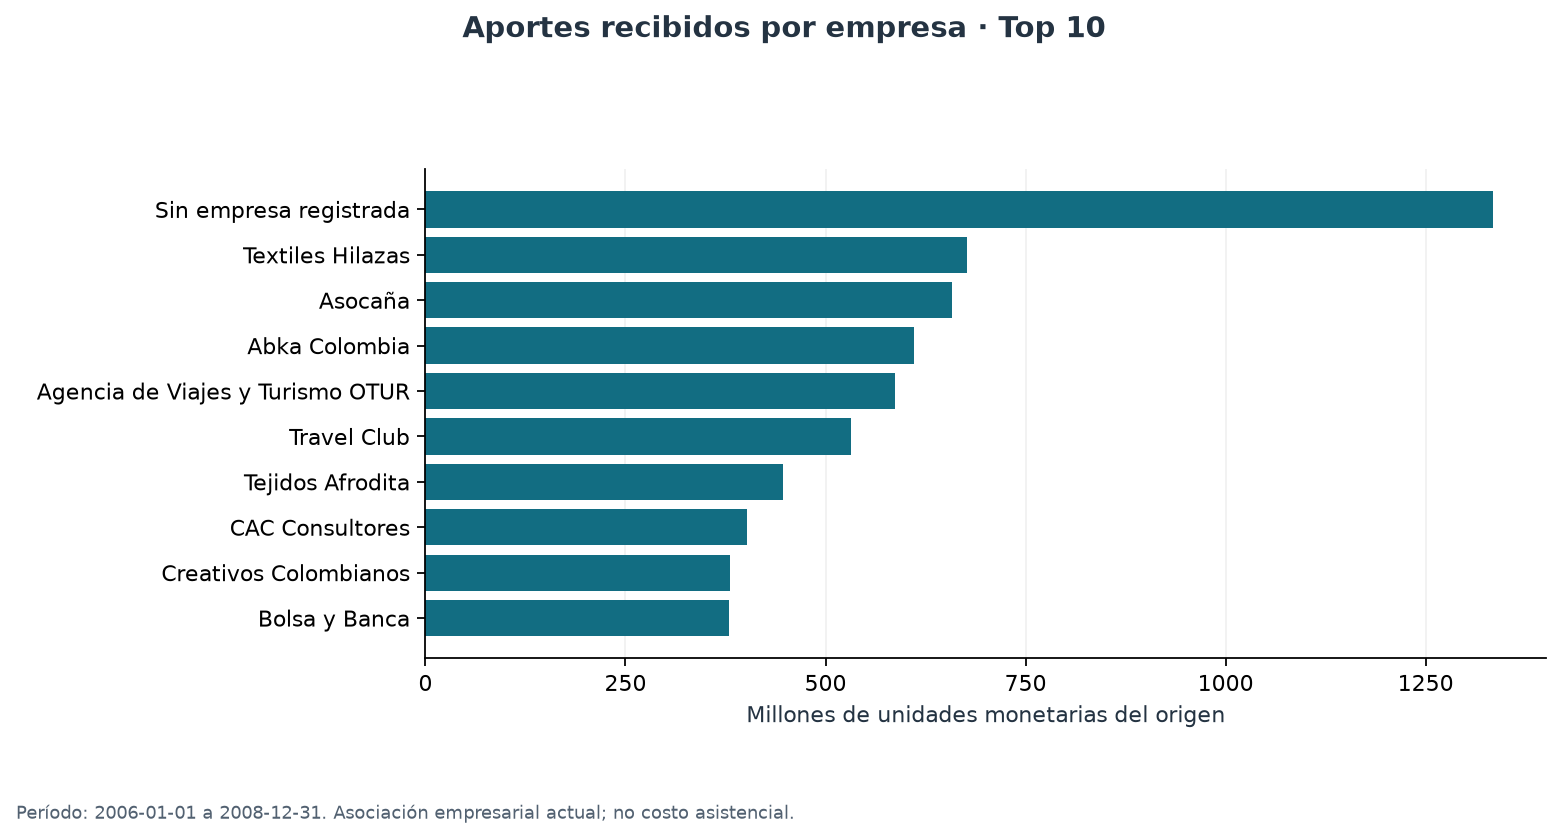

**Respuesta e interpretación.** El prestador con más eventos es Hospital Isaías Duarte Cancio, con 1.259 eventos y 272 pacientes distintos. Se recibieron 8.548.421.149,00 unidades monetarias en aportes de 1.100 cotizantes y 1.100 familias. Un aporte del titular se cuenta una sola vez por familia. Las tablas de tarifas familiares son estimaciones de remisiones; no responden costo real ni regional administrativa.

In [5]:
# P02: prestadores, aportes y estimaciones familiares.


# Ordenar prestadores por eventos y contar pacientes distintos.
p02ips = tabla(
    'p02_prestadores',
    consultar(
        'p02_prestadores',
        """SELECT ips_nombre AS prestador,departamento,municipio,
 COUNT(*) AS eventos,COUNT(DISTINCT paciente_id) AS pacientes FROM A GROUP BY 1,2,3 ORDER BY eventos DESC,prestador""",
    ),
)
barras(
    'p02_prestadores',
    p02ips,
    'prestador',
    'eventos',
    f'Prestadores con más eventos · Top {TOP_N}',
    'Eventos registrados',
    'IPS asociada al médico, sin vigencia histórica; no sitio de atención certificado.',
)

# Agrupar primero por afiliado para no multiplicar aportes al cruzar familias.
p02af = tabla(
    'p02_aportes_afiliado_anonimo',
    consultar(
        'p02_aportes_afiliado',
        """SELECT ROW_NUMBER() OVER(ORDER BY SUM(valor_aporte) DESC) AS posicion,
 COUNT(*) AS transacciones,SUM(valor_aporte)::text AS aporte_total FROM P GROUP BY paciente_id ORDER BY SUM(valor_aporte) DESC""",
    ),
    10,
)

# Contar el aporte del titular una sola vez por familia.
p02fam = tabla(
    'p02_aportes_familia_anonima',
    consultar(
        'p02_aportes_familia',
        """SELECT ROW_NUMBER() OVER(ORDER BY z.aporte DESC) AS posicion,
 z.transacciones,z.aporte::text AS aporte_total,d.numero_miembros
 FROM (SELECT familia_id,COUNT(*) AS transacciones,SUM(valor_aporte) AS aporte FROM P GROUP BY familia_id) z
 JOIN public.dim_familia d ON d.familia_id=z.familia_id ORDER BY z.aporte DESC""",
    ),
    10,
)

# Agregar por empresa usando la asociación registrada en el modelo.
p02emp = tabla(
    'p02_aportes_empresa',
    consultar(
        'p02_aportes_empresa',
        """SELECT COALESCE(e.nombre,'Sin empresa registrada') AS empresa,
 COUNT(*) AS transacciones,COUNT(DISTINCT p.paciente_id) AS cotizantes,SUM(p.valor_aporte)::text AS aporte_total
 FROM P p LEFT JOIN public.dim_empresa e ON e.empresa_id=p.empresa_id GROUP BY 1 ORDER BY SUM(p.valor_aporte) DESC""",
    ),
)

# Repetir el mismo cálculo para cada segmentación declarada.
for campo in ['municipio', 'departamento']:
    tabla(
        'p02_aportes_' + campo,
        consultar(
            'p02_aportes_' + campo,
            f"SELECT {campo},COUNT(*) AS transacciones,SUM(valor_aporte)::text AS"
            " aporte_total FROM P GROUP BY 1 ORDER BY SUM(valor_aporte) DESC",
        ),
    )

# Separar tarifas estimadas de remisiones de los aportes recibidos.
p02cost = tabla(
    'p02_tarifa_familiar_anonima',
    consultar(
        'p02_tarifa_familiar',
        """SELECT ROW_NUMBER() OVER(ORDER BY SUM(tarifa_servicio_catalogo) DESC) AS posicion,
 COUNT(*) AS remisiones,COUNT(DISTINCT paciente_id) AS miembros_con_remision,SUM(tarifa_servicio_catalogo)::text AS tarifa_total
 FROM A WHERE tarifa_informada GROUP BY familia_id ORDER BY SUM(tarifa_servicio_catalogo) DESC""",
    ),
    10,
)
barras(
    'p02_aportes_empresa',
    p02emp,
    'empresa',
    'aporte_total',
    f'Aportes recibidos por empresa · Top {TOP_N}',
    'Millones de unidades monetarias del origen',
    'Asociación empresarial actual; no costo asistencial.',
    escala=1e6,
)

# Conciliar los mismos aportes entre las agrupaciones antes de interpretarlos.
aporte = sum((Decimal(v) for v in p02af.aporte_total), Decimal(0))
comprobar(
    'p02_aportes_familia_no_multiplicados',
    aporte == sum((Decimal(v) for v in p02fam.aporte_total), Decimal(0)),
)
comprobar(
    'p02_aportes_empresa_concilian',
    aporte == sum((Decimal(v) for v in p02emp.aporte_total), Decimal(0)),
)
lider = (
    f"El prestador con más eventos es {p02ips.iloc[0].prestador}, con"
    f" {fmt(p02ips.iloc[0].eventos)} eventos y {fmt(p02ips.iloc[0].pacientes)}"
    " pacientes distintos. "
    if not p02ips.empty
    else 'No hay eventos. '
)
concluir(
    'P02',
    lider
    + f"Se recibieron {fmt(aporte,2)} unidades monetarias en aportes de"
    f" {fmt(len(p02af))} cotizantes y {fmt(len(p02fam))} familias. Un aporte del"
    " titular se cuenta una sola vez por familia. Las tablas de tarifas familiares"
    " son estimaciones de remisiones; no responden costo real ni regional"
    " administrativa.",
)


## P03. Tarifas por segmento y medicamentos más recetados

Se estima únicamente el subconjunto de remisiones con tarifa. Estrato es familiar; tipo de cotizante del titular
es una aproximación laboral, no una ocupación detallada. El grupo de edad se calcula a la atención.
Las frecuencias de medicamentos cuentan recetas distintas por código, no unidades dispensadas.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL agrupa tarifas por segmento y cuenta recetas distintas. Python configura los segmentos e interpreta el agregado; los CSV y gráficos pasan por auxiliares que delegan lo tabular al Core.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `etiqueta.lower`, `int` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p03_tarifa_estrato_familiar.csv (5 registros, 5 columnas)


,segmento,remisiones,pacientes,tarifa_total,tarifa_media_evento
0,3,4309,122,1090518714.00,253079.30
1,4,3680,106,1013004868.00,275273.06
2,5,3009,85,858967474.00,285466.09
3,1,2788,91,747861814.00,268243.12
4,2,2956,100,670251244.00,226742.64


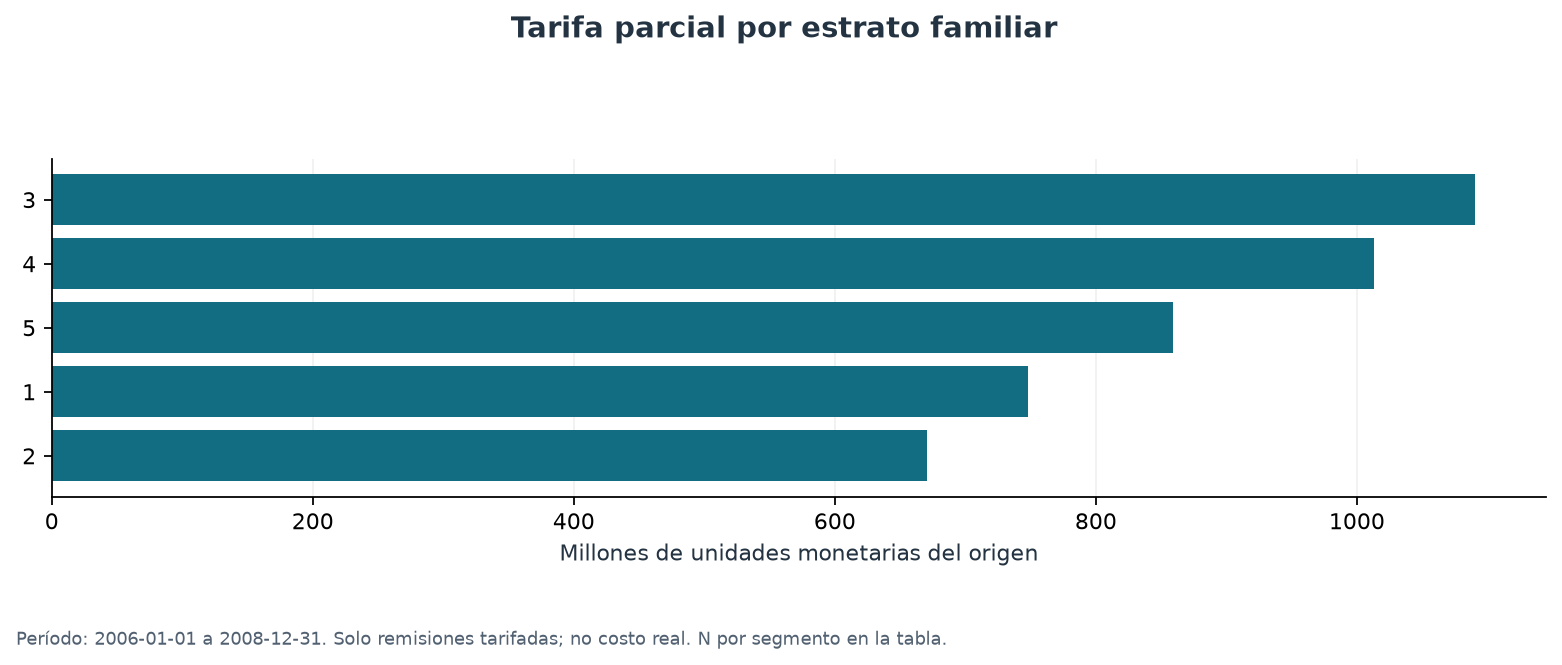

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p03_tarifa_tipo_cotizante_titular.csv (3 registros, 5 columnas)


,segmento,remisiones,pacientes,tarifa_total,tarifa_media_evento
0,empleado,10137,292,2638264193.00,260260.85
1,jubilado,3880,129,1032688346.00,266156.79
2,independiente,2725,83,709651575.00,260422.60


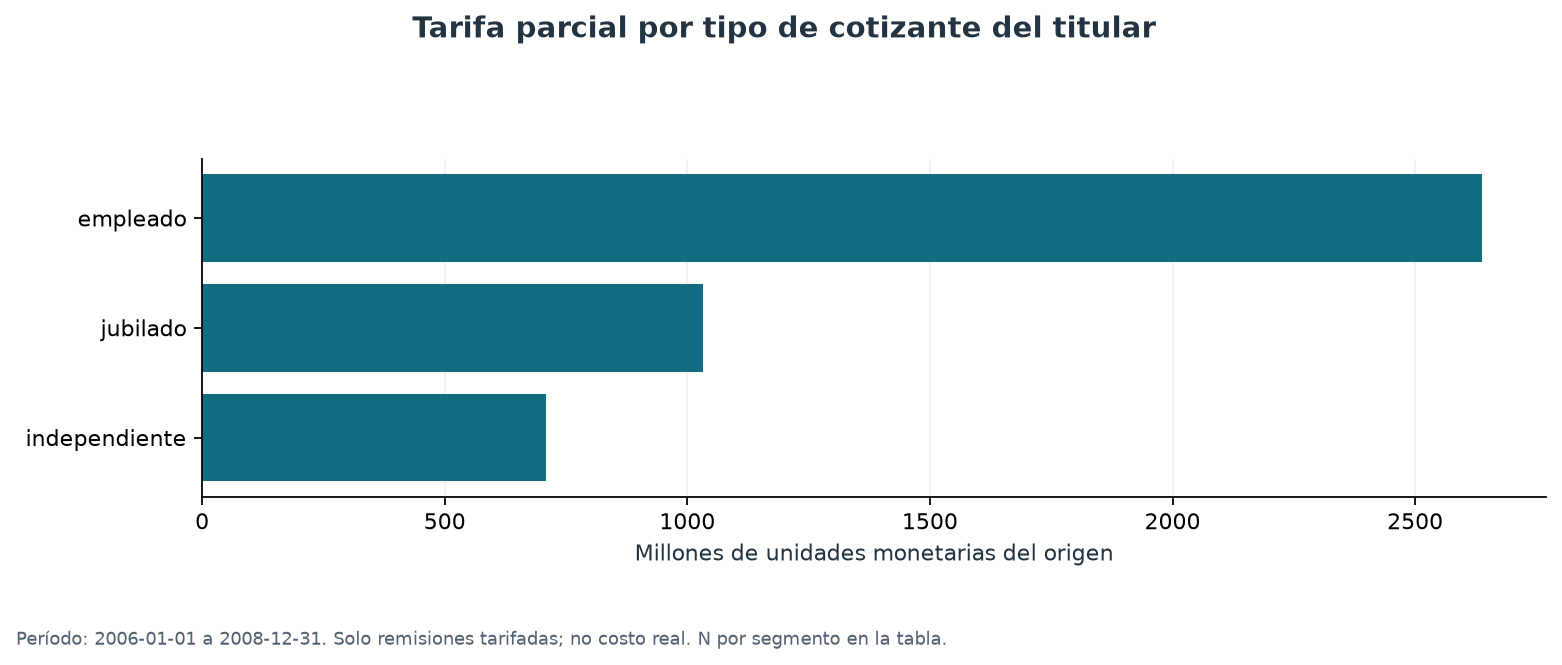

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p03_tarifa_grupo_etario_atencion.csv (5 registros, 5 columnas)


,segmento,remisiones,pacientes,tarifa_total,tarifa_media_evento
0,65+,5094,147,1372569366.00,269448.25
1,45-64,3678,124,939035014.00,255311.31
2,25-44,3378,113,864857228.00,256026.41
3,15-24,2657,84,676627065.00,254658.29
4,5-14,1935,65,527515441.00,272617.80


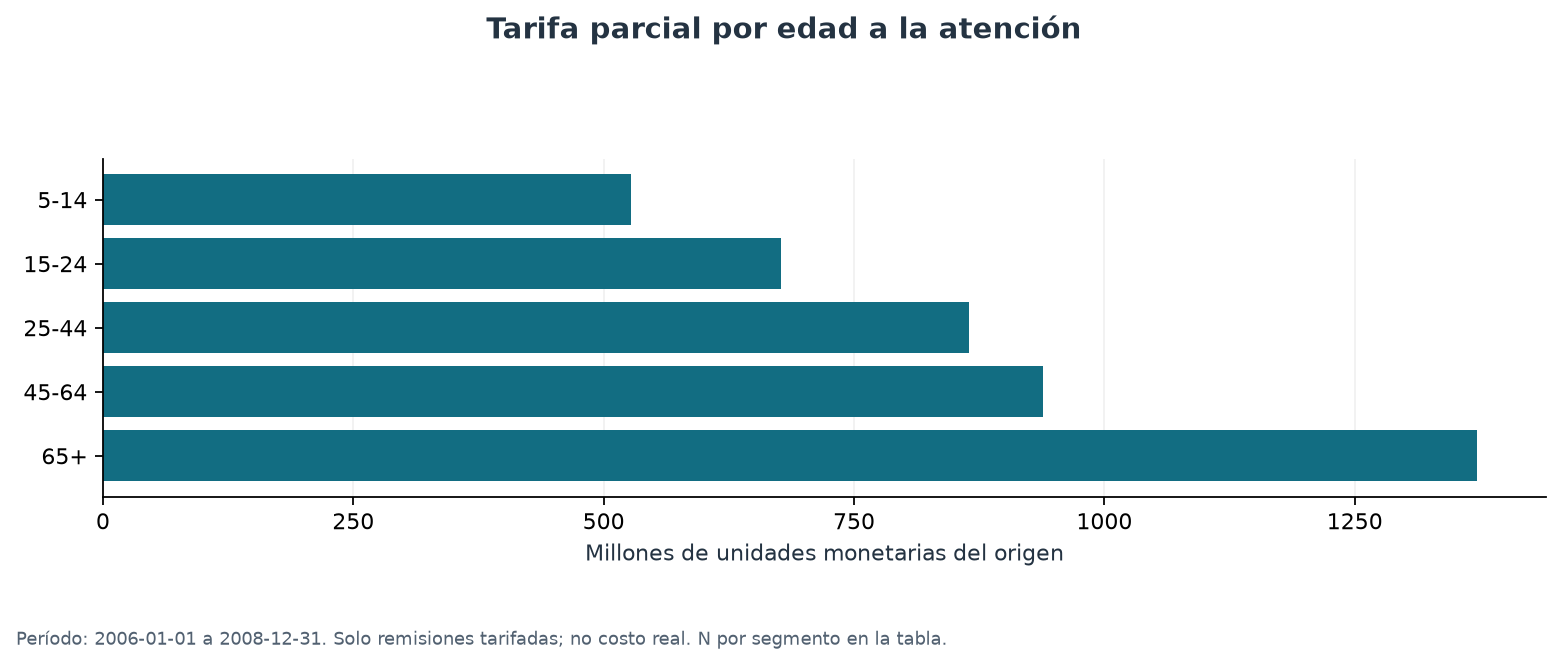

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p03_frecuencia_medicamentos.csv (166 registros, 3 columnas)


,codigo,recetas,recetas_pct
0,2349,895,11.96
1,2356,861,11.50
2,1047,850,11.36
3,2503,593,7.92
4,1257,441,5.89
5,1887,425,5.68
6,1880,409,5.46
7,1229,315,4.21
8,2545,292,3.90
9,1222,288,3.85


Tabla completa: **166 filas agregadas** en `p03_frecuencia_medicamentos.csv`.

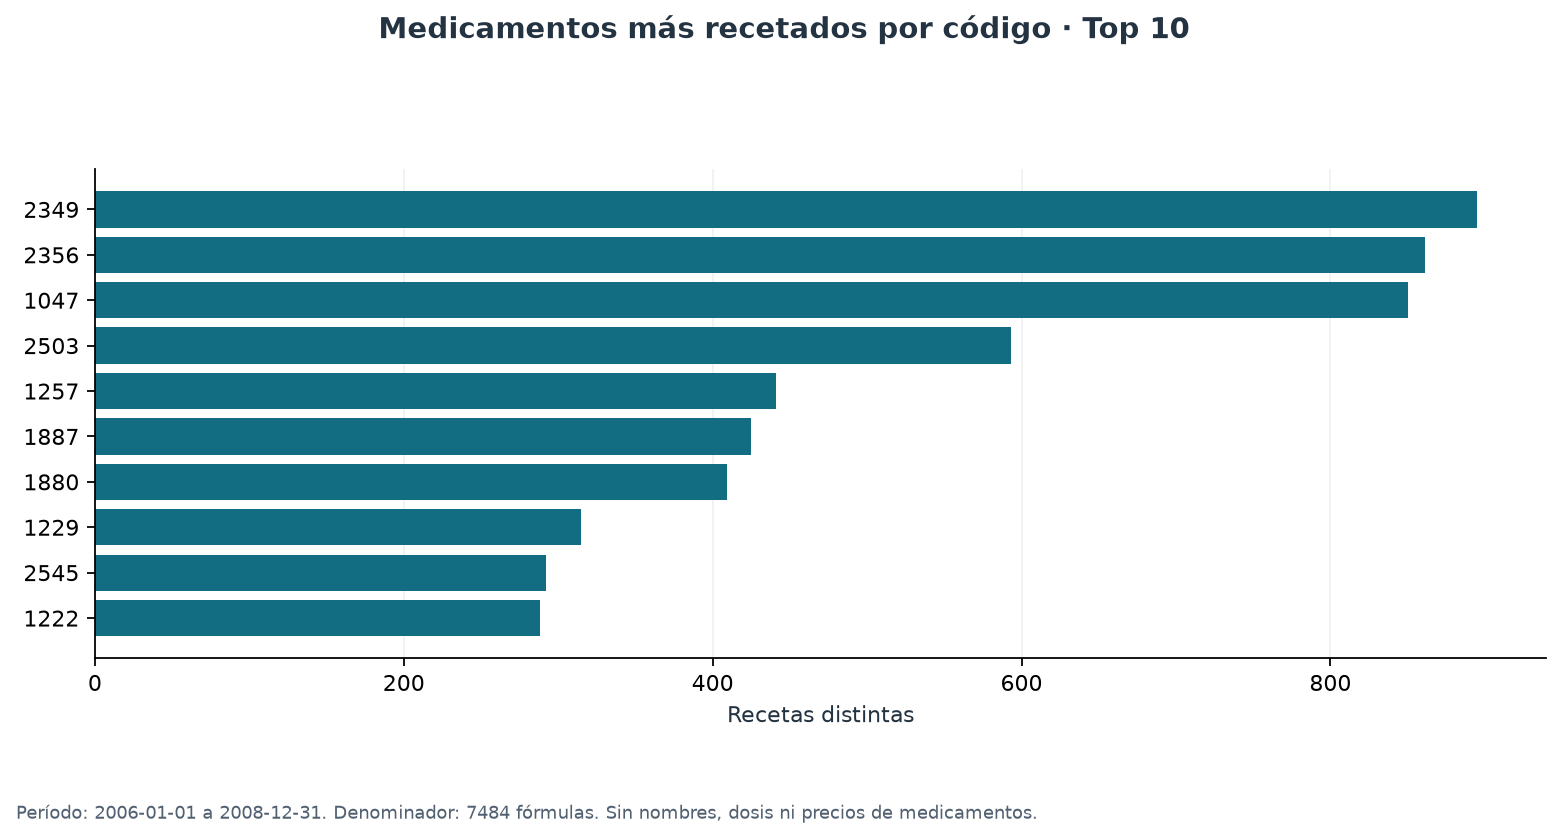

**Respuesta e interpretación.** El código más frecuente es 2349, presente en 895 recetas (11,96 %). Las estimaciones por estrato, tipo de titular y edad incluyen únicamente remisiones tarifadas; no permiten medir el costo real por ocupación.

In [6]:
# P03: tarifas por segmento y frecuencia de medicamentos.


# Calcular tarifas por estrato, tipo de titular y edad sin mezclarlas con costos reales.
p03 = {}
for campo, etiqueta in [
    ('estrato_familiar', 'Estrato familiar'),
    ('tipo_cotizante_titular', 'Tipo de cotizante del titular'),
    ('grupo_etario_atencion', 'Edad a la atención'),
]:
    p03[campo] = tabla(
        'p03_tarifa_' + campo,
        consultar(
            'p03_tarifa_' + campo,
            f"""SELECT COALESCE({campo},'desconocido') AS segmento,
 COUNT(*) AS remisiones,COUNT(DISTINCT paciente_id) AS pacientes,SUM(tarifa_servicio_catalogo)::text AS tarifa_total,
 ROUND(AVG(tarifa_servicio_catalogo),2)::text AS tarifa_media_evento FROM A WHERE tarifa_informada GROUP BY 1 ORDER BY SUM(tarifa_servicio_catalogo) DESC""",
        ),
    )
    barras(
        'p03_' + campo,
        p03[campo],
        'segmento',
        'tarifa_total',
        'Tarifa parcial por ' + etiqueta.lower(),
        'Millones de unidades monetarias del origen',
        'Solo remisiones tarifadas; no costo real. N por segmento en la tabla.',
        escala=1e6,
    )

# Contar recetas distintas por código, sin inferir cantidades dispensadas.
frecuencias = tabla(
    'p03_frecuencia_medicamentos',
    consultar(
        'p03_frecuencia_medicamentos',
        """SELECT b.medicamento_id AS codigo,
 COUNT(DISTINCT f.codigo_formula) AS recetas,ROUND(100.0*COUNT(DISTINCT f.codigo_formula)/NULLIF((SELECT COUNT(*) FROM F),0),2) AS recetas_pct
 FROM F f JOIN public.puente_formula_medicamento b ON b.codigo_formula=f.codigo_formula GROUP BY b.medicamento_id ORDER BY recetas DESC,codigo""",
    ),
)
barras(
    'p03_medicamentos',
    frecuencias,
    'codigo',
    'recetas',
    f'Medicamentos más recetados por código · Top {TOP_N}',
    'Recetas distintas',
    f'Denominador: {int(totales.formulas)} fórmulas. Sin nombres, dosis ni precios de'
    ' medicamentos.',
)

# Presentar el código más frecuente y el alcance parcial de las estimaciones.
mas = (
    f"El código más frecuente es {frecuencias.iloc[0].codigo}, presente en"
    f" {fmt(frecuencias.iloc[0].recetas)} recetas"
    f" ({fmt(frecuencias.iloc[0].recetas_pct,2)} %). "
    if not frecuencias.empty
    else 'No hay recetas seleccionadas. '
)
concluir(
    'P03',
    mas
    + 'Las estimaciones por estrato, tipo de titular y edad incluyen únicamente'
    ' remisiones tarifadas; no permiten medir el costo real por ocupación.',
)


## P04. Medicamentos que se formulan juntos

Se cuenta cada par no ordenado una vez por receta (`A < B`), excluyendo pares consigo mismo.
Soporte = recetas con el par / todas las recetas seleccionadas. La diagonal de la matriz indica recetas con
el código individual, y las demás celdas indican coocurrencias; no son cantidades o recomendaciones clínicas.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** El SQL de autounión cuenta cada par de medicamentos una vez por receta. pandas DataFrame/loc/rename_axis/reset_index crea la matriz etiquetada; no hay pivot equivalente en los transformadores usados. NumPy/Matplotlib dibujan la matriz y Python verifica pares/soporte.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `figura` | compone, guarda y muestra imágenes con Matplotlib/IPython; el Core no renderiza gráficos Python. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `all`, `int`, `len`, `list`, `min`, `range`, `str` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| DataFrames y matrices | `frecuencias.head`, `frecuencias.itertuples`, `matriz.rename_axis`, `matriz.rename_axis(…).reset_index`, `matriz.to_numpy`, `matriz.to_numpy(…).max`, `pares.itertuples`, `pd.DataFrame` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `ax.imshow`, `ax.set_xticks`, `ax.set_yticks`, `ax.text`, `fig.colorbar`, `plt.subplots` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p04_coformulacion.csv (735 registros, 4 columnas)


,codigo_a,codigo_b,recetas_juntas,soporte_pct
0,1047,2356,280,3.74
1,1047,2349,268,3.58
2,1257,1887,124,1.66
3,2195,2356,122,1.63
4,1257,1880,116,1.55
5,2202,2349,116,1.55
6,2195,2349,107,1.43
7,1257,2545,104,1.39
8,1880,2545,102,1.36
9,1887,2545,102,1.36


Tabla completa: **735 filas agregadas** en `p04_coformulacion.csv`.

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p04_matriz_top_codigos.csv (10 registros, 11 columnas)


,codigo,2349,2356,1047,2503,1257,1887,1880,1229,2545,1222
0,2349,895,0,268,90,0,0,0,0,0,0
1,2356,0,861,280,89,0,0,0,0,0,0
2,1047,268,280,850,0,49,0,0,0,0,0
3,2503,90,89,0,593,0,0,0,0,0,0
4,1257,0,0,49,0,441,124,116,0,104,0
5,1887,0,0,0,0,124,425,0,17,102,3
6,1880,0,0,0,0,116,0,409,18,102,4
7,1229,0,0,0,0,0,17,18,315,0,0
8,2545,0,0,0,0,104,102,102,0,292,0
9,1222,0,0,0,0,0,3,4,0,0,288


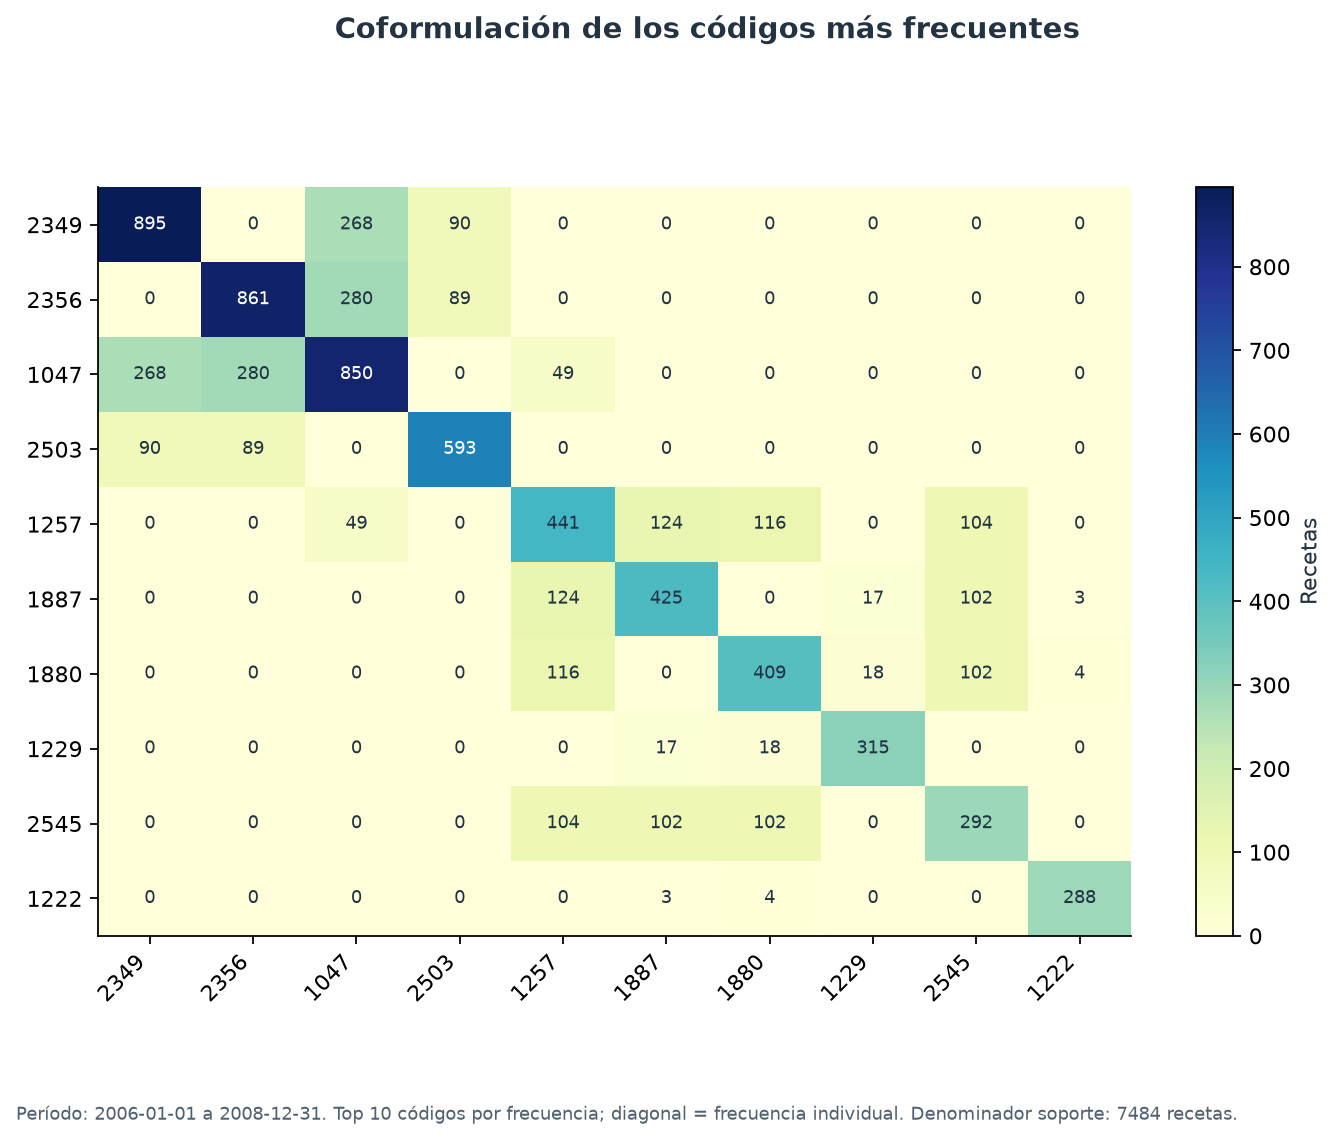

**Respuesta e interpretación.** El par más frecuente es 1047 + 2356, con 280 recetas compartidas y soporte 3,74 %. Las frecuencias individuales están en P03. No se infieren dosis, entrega ni conveniencia clínica.

In [7]:
# P04: medicamentos que aparecen juntos en una receta.


# Contar cada par no ordenado una vez por receta y calcular su soporte.
pares = tabla(
    'p04_coformulacion',
    consultar(
        'p04_coformulacion',
        """SELECT b1.medicamento_id AS codigo_a,b2.medicamento_id AS codigo_b,
 COUNT(*) AS recetas_juntas,ROUND(100.0*COUNT(*)/NULLIF((SELECT COUNT(*) FROM F),0),2) AS soporte_pct
 FROM F f JOIN public.puente_formula_medicamento b1 ON b1.codigo_formula=f.codigo_formula
 JOIN public.puente_formula_medicamento b2 ON b2.codigo_formula=f.codigo_formula AND b1.medicamento_id<b2.medicamento_id
 GROUP BY 1,2 ORDER BY recetas_juntas DESC,codigo_a,codigo_b""",
    ),
)
comprobar(
    'p04_pares_no_ordenados_y_soporte',
    all(
        r.codigo_a < r.codigo_b and r.recetas_juntas <= int(totales.formulas)
        for r in pares.itertuples()
    ),
)
if not frecuencias.empty:

    # Limitar la matriz a los códigos más frecuentes para mantenerla legible.
    codigos = list(frecuencias.head(min(TOP_N, 12)).codigo)

    # Reservar la diagonal para frecuencias individuales y reflejar los pares a ambos
    # lados.
    matriz = pd.DataFrame(0, index=codigos, columns=codigos)
    for r in frecuencias.itertuples():
        if r.codigo in codigos:
            matriz.loc[r.codigo, r.codigo] = r.recetas
    for r in pares.itertuples():
        if r.codigo_a in codigos and r.codigo_b in codigos:
            matriz.loc[r.codigo_a, r.codigo_b] = r.recetas_juntas
            matriz.loc[r.codigo_b, r.codigo_a] = r.recetas_juntas
    tabla('p04_matriz_top_codigos', matriz.rename_axis('codigo').reset_index())
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(matriz.to_numpy(), cmap='YlGnBu', aspect='auto')
    ax.set_xticks(range(len(codigos)), codigos, rotation=45, ha='right')
    ax.set_yticks(range(len(codigos)), codigos)
    for i in range(len(codigos)):
        for j in range(len(codigos)):
            ax.text(
                j,
                i,
                str(matriz.iloc[i, j]),
                ha='center',
                va='center',
                fontsize=8,
                color=(
                    'white'
                    if matriz.iloc[i, j] > matriz.to_numpy().max() * 0.6
                    else '#203444'
                ),
            )
    fig.colorbar(im, ax=ax, label='Recetas')
    figura(
        'p04_matriz',
        fig,
        'Coformulación de los códigos más frecuentes',
        f'Top {len(codigos)} códigos por frecuencia; diagonal = frecuencia individual.'
        f' Denominador soporte: {int(totales.formulas)} recetas.',
    )
concluir(
    'P04',
    (
        f"El par más frecuente es {pares.iloc[0].codigo_a} + {pares.iloc[0].codigo_b},"
        f" con {fmt(pares.iloc[0].recetas_juntas)} recetas compartidas y soporte"
        f" {fmt(pares.iloc[0].soporte_pct,2)} %. "
        if not pares.empty
        else 'No hay pares de medicamentos en las recetas seleccionadas. '
    )
    + 'Las frecuencias individuales están en P03. No se infieren dosis, entrega ni'
    ' conveniencia clínica.',
    estado='disponible_por_codigo',
)


## P05. Promedio de utilización por paciente, sexo y edad

La medida principal es eventos / pacientes atendidos en la selección. Los denominadores de sexo/edad
son pacientes distintos dentro de cada grupo; una persona puede cambiar de grupo etario durante el período.
Por ello, los pacientes distintos de las categorías no se suman para obtener el global.
También se muestra el promedio sobre afiliados registrados, incluidos ceros, cuando los filtros permiten
comparar ese denominador. No equivale a una tasa por afiliado activo o por tiempo de exposición.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL calcula eventos, pacientes distintos y denominadores con/sin utilización. Python elige cuándo el denominador es comparable y redacta la respuesta; no se cambia esa semántica por una media de medias.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `literal` | escapa los literales usados por el SQL del cuaderno. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `campo.replace`, `int`, `str.join` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p05_utilizacion_global.csv (1 registros, 3 columnas)


,eventos,pacientes_atendidos,eventos_por_atendido
0,21207,504,42.0774


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p05_utilizacion_sexo.csv (2 registros, 4 columnas)


,grupo,eventos,pacientes_atendidos,eventos_por_atendido
0,f,10955,261,41.9732
1,m,10252,243,42.1893


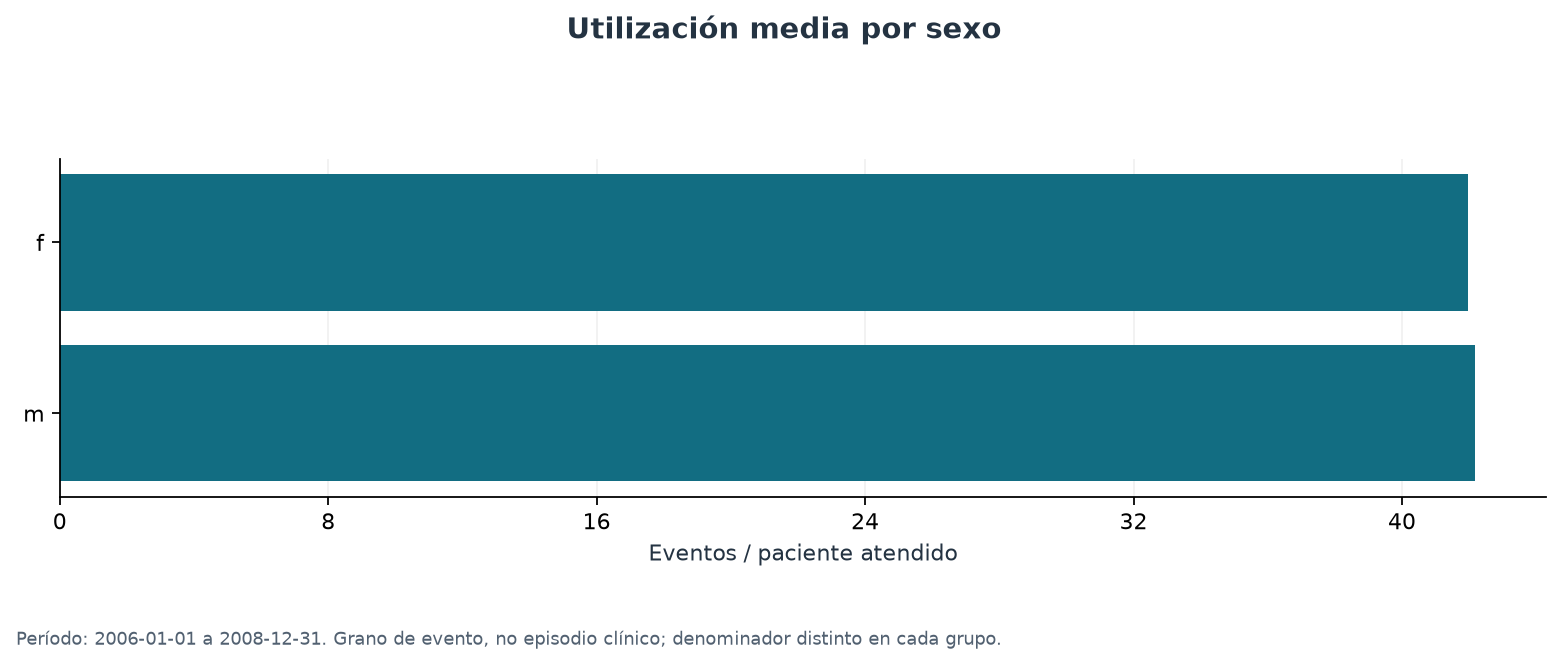

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p05_utilizacion_grupo_etario_atencion.csv (5 registros, 4 columnas)


,grupo,eventos,pacientes_atendidos,eventos_por_atendido
0,65+,6364,147,43.2925
1,45-64,4753,124,38.3306
2,25-44,4323,114,37.9211
3,15-24,3337,84,39.7262
4,5-14,2430,65,37.3846


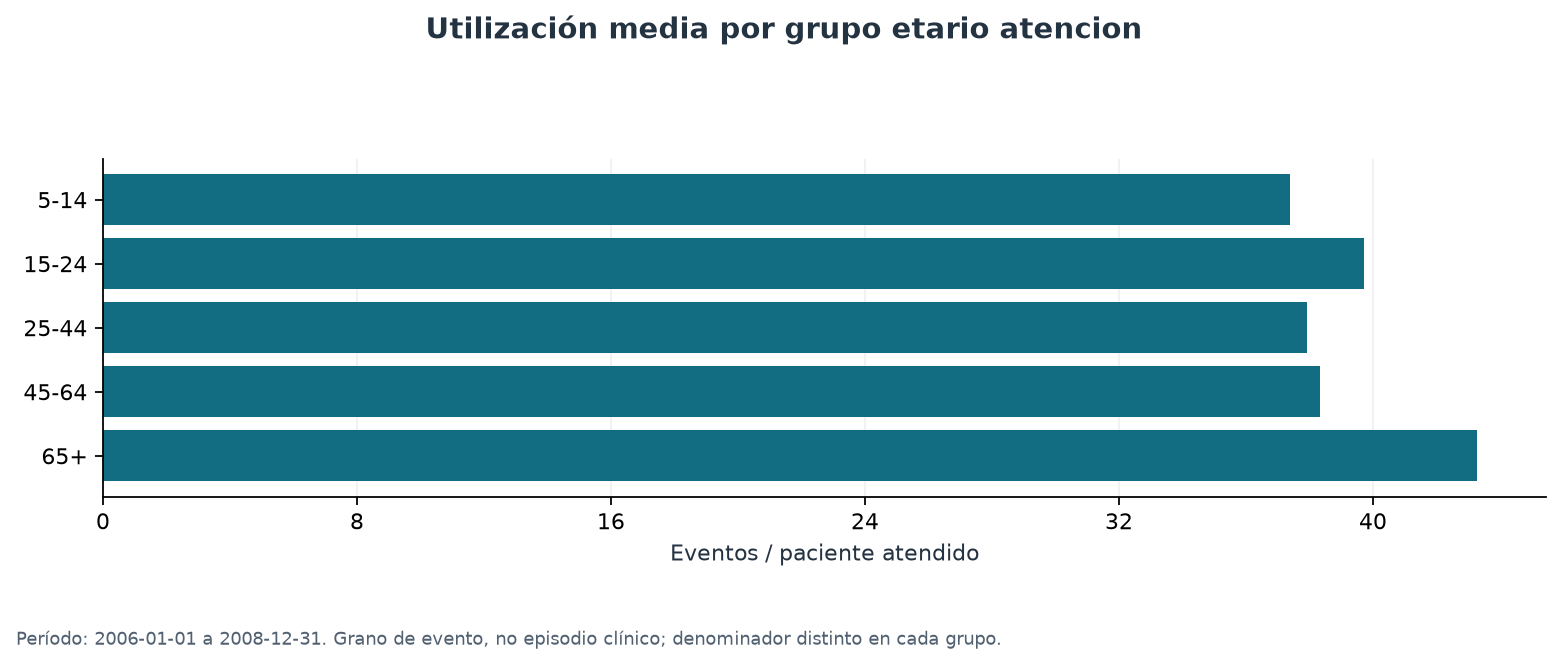

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p05_utilizacion_tipo_atencion.csv (4 registros, 4 columnas)


,grupo,eventos,pacientes_atendidos,eventos_por_atendido
0,remision,16742,504,33.2183
1,cita_general,3013,504,5.9782
2,hospitalizacion,893,389,2.2956
3,urgencia,559,286,1.9545


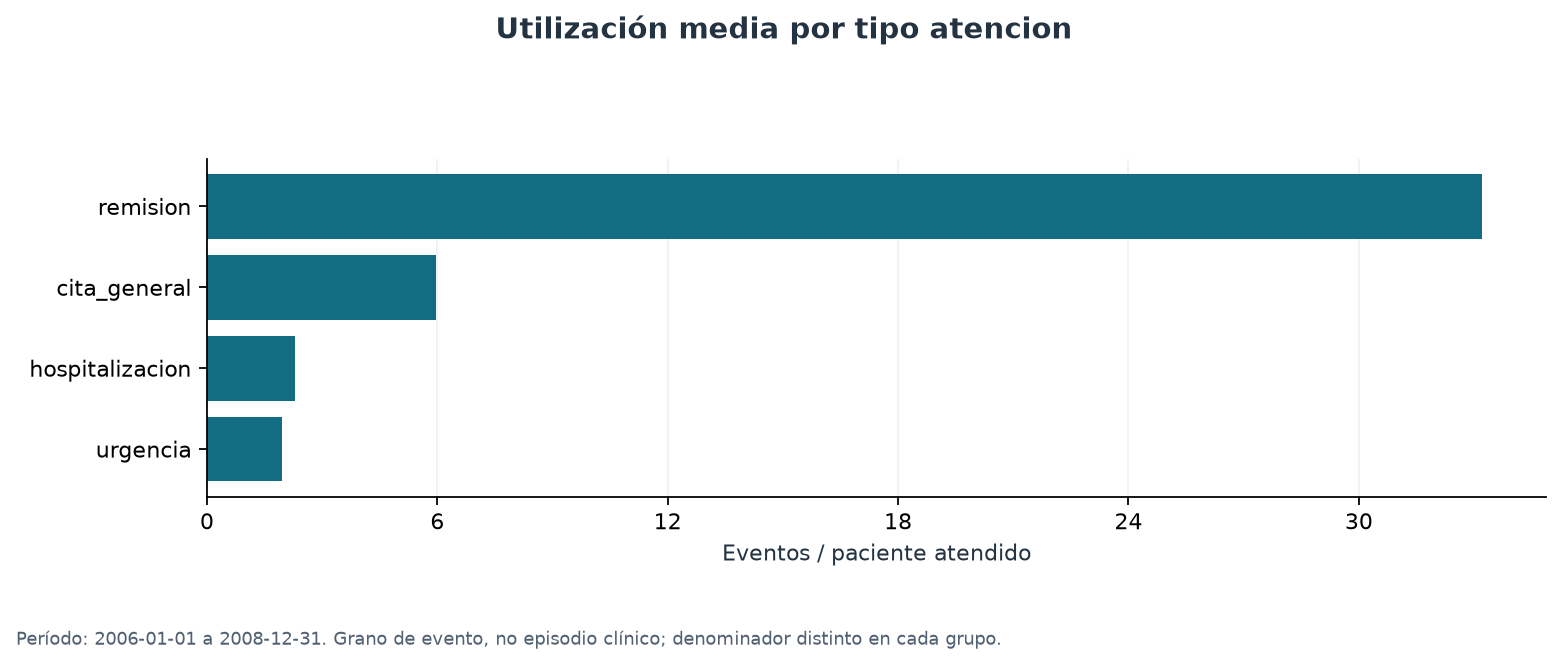

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p05_utilizacion_registrados.csv (1 registros, 4 columnas)


,afiliados_registrados,sin_eventos,eventos,eventos_por_registrado
0,4416,3912,21207.0,4.8023


**Respuesta e interpretación.** Se observan 42,08 eventos por paciente atendido, con 21.207 eventos y 504 personas distintas. Sobre 4.416 afiliados registrados, incluidos 3.912 sin eventos, la media es 4,80. Son eventos de cuatro tablas, no episodios deduplicados ni utilización por afiliado activo.

In [8]:
# P05: utilización por paciente atendido y por afiliado registrado.


# Usar pacientes distintos como denominador de eventos por persona atendida.
p05global = tabla(
    'p05_utilizacion_global',
    consultar(
        'p05_utilizacion_global',
        """SELECT COUNT(*) AS eventos,
 COUNT(DISTINCT paciente_id) AS pacientes_atendidos,
 ROUND(COUNT(*)::numeric/NULLIF(COUNT(DISTINCT paciente_id),0),4) AS eventos_por_atendido FROM A""",
    ),
)

# Repetir el mismo cálculo para cada segmentación declarada.
for campo in ['sexo', 'grupo_etario_atencion', 'tipo_atencion']:
    d = tabla(
        'p05_utilizacion_' + campo,
        consultar(
            'p05_utilizacion_' + campo,
            f"""SELECT COALESCE({campo},'desconocido') AS grupo,
 COUNT(*) AS eventos,COUNT(DISTINCT paciente_id) AS pacientes_atendidos,
 ROUND(COUNT(*)::numeric/NULLIF(COUNT(DISTINCT paciente_id),0),4) AS eventos_por_atendido FROM A
 GROUP BY 1 ORDER BY eventos DESC""",
        ),
    )
    barras(
        'p05_' + campo,
        d,
        'grupo',
        'eventos_por_atendido',
        'Utilización media por ' + campo.replace('_', ' '),
        'Eventos / paciente atendido',
        'Grano de evento, no episodio clínico; denominador distinto en cada grupo.',
    )
if not (IPS or DEPARTAMENTOS or GRUPOS_EDAD):

    # Incluir personas sin eventos solo cuando el denominador registrado es comparable.
    filtro_sexo = (
        ' AND p.sexo IN (' + ','.join(literal(v) for v in SEXOS) + ')' if SEXOS else ''
    )
    p05registrados = tabla(
        'p05_utilizacion_registrados',
        consultar(
            'p05_utilizacion_registrados',
            f""", usos AS (
       SELECT paciente_id,COUNT(*) AS n FROM A GROUP BY paciente_id)
       SELECT COUNT(*) AS afiliados_registrados,COUNT(*) FILTER(WHERE u.n IS NULL) AS sin_eventos,
       SUM(COALESCE(u.n,0)) AS eventos,ROUND(AVG(COALESCE(u.n,0)),4) AS eventos_por_registrado
       FROM public.dim_paciente p LEFT JOIN usos u ON u.paciente_id=p.paciente_id WHERE TRUE {filtro_sexo}""",
        ),
    )
    p05extra = (
        f"Sobre {fmt(p05registrados.iloc[0].afiliados_registrados)} afiliados"
        f" registrados, incluidos {fmt(p05registrados.iloc[0].sin_eventos)} sin"
        " eventos, la media es"
        f" {fmt(p05registrados.iloc[0].eventos_por_registrado,2)}. "
    )
else:
    p05extra = (
        'No se compara con afiliados registrados al aplicar filtros etarios o de'
        ' geografía: su población de referencia no equivale a la de eventos. '
    )

# Comprobar el denominador global antes de redactar la respuesta.
fila = p05global.iloc[0]
comprobar(
    'p05_denominador_no_supera_eventos',
    int(fila.pacientes_atendidos) <= int(fila.eventos),
)
concluir(
    'P05',
    f"Se observan {fmt(fila.eventos_por_atendido,2)} eventos por paciente atendido, con"
    f" {fmt(fila.eventos)} eventos y {fmt(fila.pacientes_atendidos)} personas"
    " distintas. "
    + p05extra
    + 'Son eventos de cuatro tablas, no episodios deduplicados ni utilización por'
    ' afiliado activo.',
    estado='disponible_con_denominador_declarado',
)


## P06. Actividad de hospitales y médicos por temporadas

No hay camas, turnos, agendas o capacidad contratada para medir ocupación real. La aproximación disponible
es **actividad registrada**. Se muestran eventos por día calendario de cada temporada para no comparar
directamente períodos de diferente duración. No se interpreta como productividad por hora trabajada. La cobertura temporal puede ser incompleta, en especial al final de 2008.
Las temporadas son las convenciones documentadas del ETL, no un calendario de vacaciones.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `ConvertOperations.fill_nulls`, `DB_Extractor.execute_query`, `DataExpresion.filter_by_value`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL agrega actividad y días calendario por temporada y genera rankings anónimos. pandas pivot transforma el agregado en matriz; el filtro del ranking y el relleno visual de ceros usan el Core. Matplotlib dibuja y Python interpreta las limitaciones.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `completar_matriz` | delega los ceros de matrices de visualización a ConvertOperations.fill_nulls; no imputa medidas desconocidas. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `figura` | compone, guarda y muestra imágenes con Matplotlib/IPython; el Core no renderiza gráficos Python. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `len`, `max`, `range`, `str` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| DataFrames y matrices | `X.filter_by_value(…).pivot`, `m.to_numpy` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `ax.imshow`, `ax.set_xticks`, `ax.set_yticks`, `fig.colorbar`, `plt.subplots` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p06_actividad_temporadas.csv (3 registros, 5 columnas)


,temporada,dias_calendario,eventos,pacientes,eventos_por_dia_calendario
0,semana_santa,21,462,283,22.000
1,navidad,24,519,315,21.625
2,ordinario,1051,20226,504,19.245


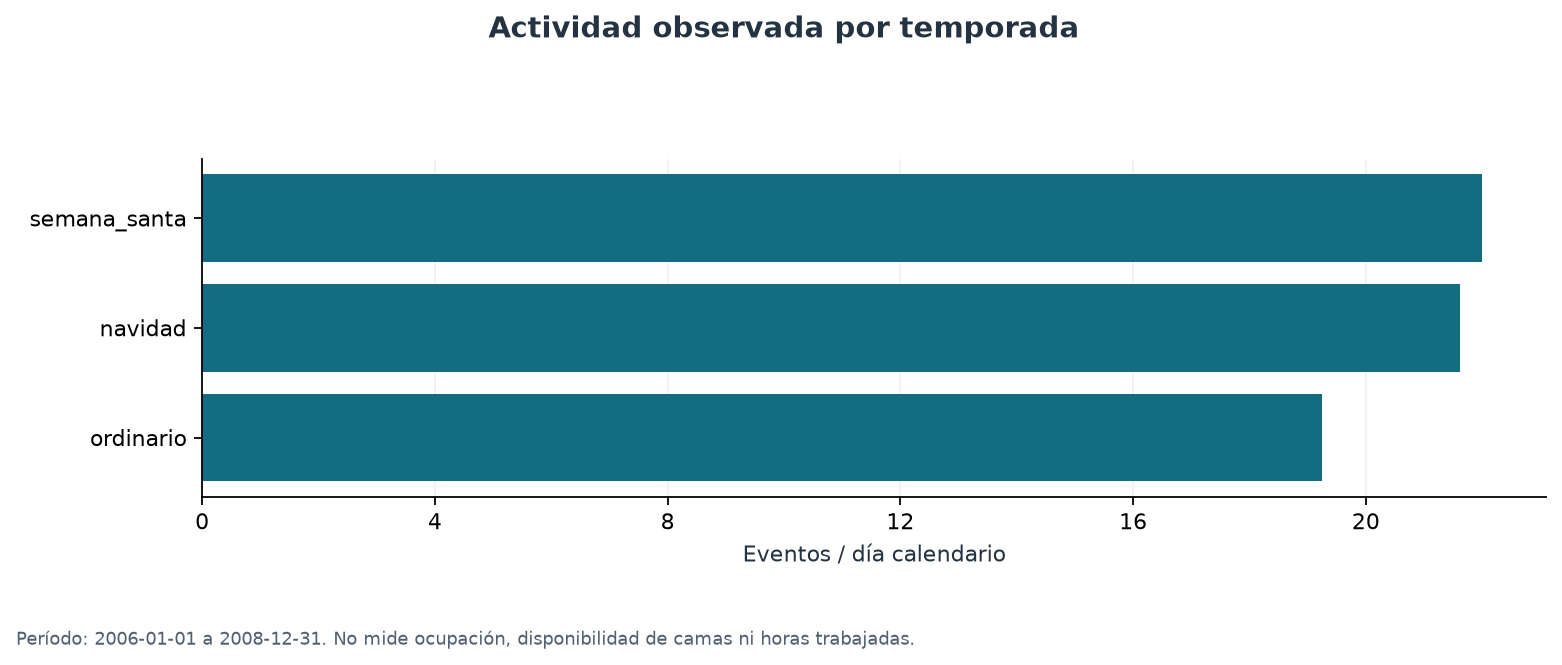

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p06_hospitales_temporadas.csv (75 registros, 4 columnas)


,hospital,temporada,eventos,pacientes
0,Hospital Isaías Duarte Cancio,ordinario,1823,371
1,Hospital San Juan de Dios,ordinario,1089,241
2,Hospital San Cristóbal,ordinario,1058,286
3,Hospital Universitario del Valle Evaristo García,ordinario,1015,273
4,Hospital Infantil Clínica Noel,ordinario,943,269
5,Hospital La Buena Esperanza de Yumbo,ordinario,716,201
6,Hospital San Francisco de Asis,ordinario,603,211
7,Hospital General de Medellin Luz Castro de Gut...,ordinario,586,229
8,Hospital Chapinero,ordinario,443,177
9,Hospital Suba,ordinario,434,170


Tabla completa: **75 filas agregadas** en `p06_hospitales_temporadas.csv`.

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p06_medicos_anonimos_temporadas.csv (1229 registros, 3 columnas)


,posicion,temporada,eventos
0,1,navidad,4
1,1,ordinario,299
2,1,semana_santa,2
3,2,navidad,12
4,2,ordinario,268
5,2,semana_santa,4
6,3,navidad,5
7,3,ordinario,231
8,3,semana_santa,3
9,4,navidad,1


Tabla completa: **1,229 filas agregadas** en `p06_medicos_anonimos_temporadas.csv`.

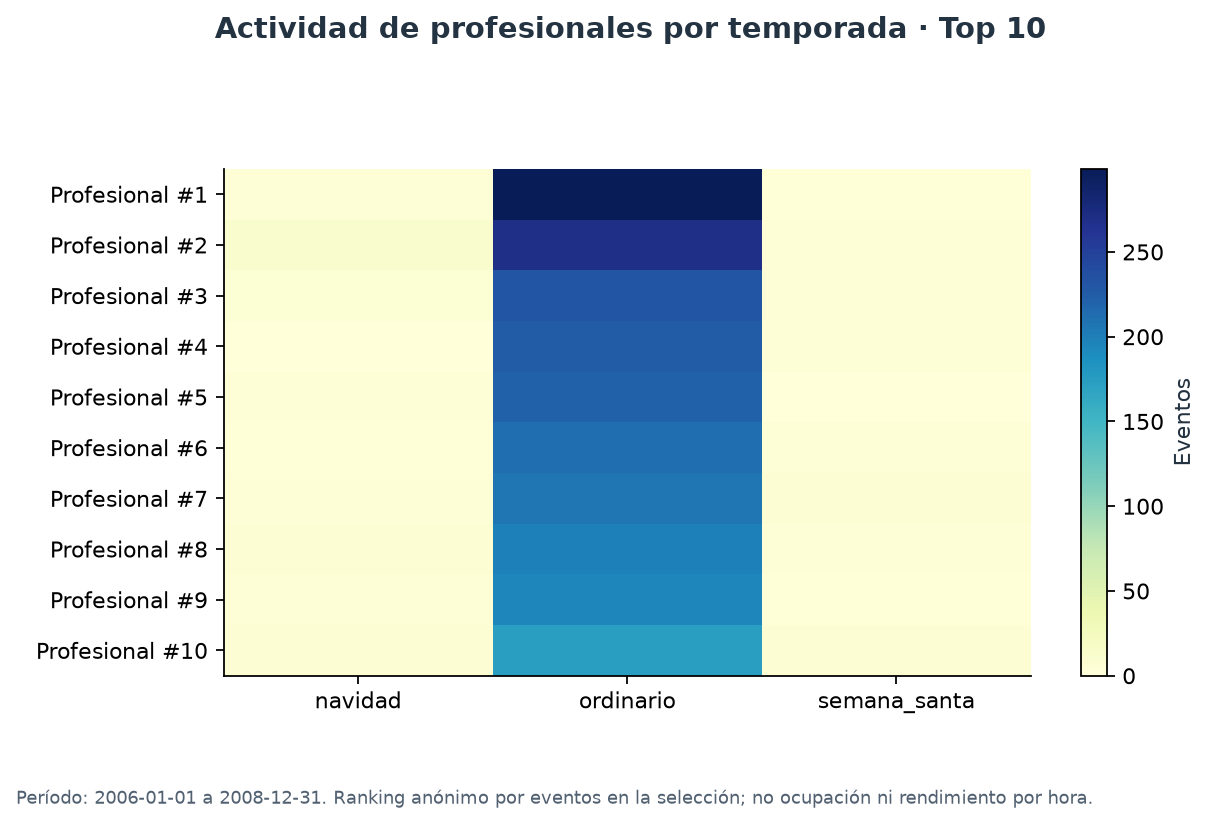

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p06_estancia_unidad_no_informada.csv (1 registros, 4 columnas)


,hospitalizaciones,minimo,maximo,duracion_media_original
0,893,1,10,5.39


**Respuesta e interpretación.** La mayor actividad diaria observada corresponde a semana_santa: 22,00 eventos por día calendario. Las tablas permiten comparar actividad de hospitales y profesionales, pero no ocupación real. La unidad de duración hospitalaria no está informada; no se calculan camas-día ni vacaciones.

In [9]:
# P06: actividad por temporada, hospitales y profesionales.


# Normalizar eventos por días calendario para comparar temporadas de distinta duración.
p06 = tabla(
    'p06_actividad_temporadas',
    consultar(
        'p06_temporadas',
        """, cal AS (
 SELECT temporada_convencional AS temporada,COUNT(*) AS dias_calendario FROM D GROUP BY 1),
 act AS (SELECT d.temporada_convencional AS temporada,COUNT(*) AS eventos,COUNT(DISTINCT a.paciente_id) AS pacientes
         FROM A a JOIN public.dim_fecha d ON d.fecha_id=a.fecha_atencion_id GROUP BY 1)
 SELECT c.temporada,c.dias_calendario,COALESCE(a.eventos,0) AS eventos,COALESCE(a.pacientes,0) AS pacientes,
 ROUND(COALESCE(a.eventos,0)::numeric/c.dias_calendario,3) AS eventos_por_dia_calendario
 FROM cal c LEFT JOIN act a USING(temporada) ORDER BY eventos_por_dia_calendario DESC""",
    ),
)
barras(
    'p06_temporadas',
    p06,
    'temporada',
    'eventos_por_dia_calendario',
    'Actividad observada por temporada',
    'Eventos / día calendario',
    'No mide ocupación, disponibilidad de camas ni horas trabajadas.',
)

# Describir actividad de hospitales sin interpretarla como ocupación de camas.
p06h = tabla(
    'p06_hospitales_temporadas',
    consultar(
        'p06_hospitales',
        """SELECT a.ips_nombre AS hospital,d.temporada_convencional AS temporada,
 COUNT(*) AS eventos,COUNT(DISTINCT a.paciente_id) AS pacientes
 FROM A a JOIN public.dim_ips i ON i.ips_id=a.ips_medico_asociado_id
 JOIN public.dim_fecha d ON d.fecha_id=a.fecha_atencion_id WHERE i.tipo_ips='hospital'
 GROUP BY 1,2 ORDER BY eventos DESC,hospital""",
    ),
)

# Ordenar profesionales mediante posiciones anónimas para comparar temporadas.
p06med = tabla(
    'p06_medicos_anonimos_temporadas',
    consultar(
        'p06_medicos',
        """, base AS (
 SELECT a.medico_id,d.temporada_convencional AS temporada,COUNT(*) AS eventos
 FROM A a JOIN public.dim_fecha d ON d.fecha_id=a.fecha_atencion_id GROUP BY 1,2),
 ranking AS (SELECT medico_id,ROW_NUMBER() OVER(ORDER BY SUM(eventos) DESC,medico_id) AS posicion FROM base GROUP BY medico_id)
 SELECT r.posicion,b.temporada,b.eventos FROM base b JOIN ranking r USING(medico_id) ORDER BY r.posicion,b.temporada""",
    ),
)
if not p06med.empty:

    # Convertir el ranking filtrado en una matriz de visualización.
    m = completar_matriz(
        X.filter_by_value(p06med, 'posicion', TOP_N, operator='le', show=0).pivot(
            index='posicion', columns='temporada', values='eventos'
        )
    )
    fig, ax = plt.subplots(figsize=(8, max(4, 0.33 * len(m) + 1.7)))
    im = ax.imshow(m.to_numpy(), cmap='YlGnBu', aspect='auto')
    ax.set_xticks(range(len(m.columns)), m.columns)
    ax.set_yticks(range(len(m)), ['Profesional #' + str(x) for x in m.index])
    fig.colorbar(im, ax=ax, label='Eventos')
    figura(
        'p06_medicos',
        fig,
        f'Actividad de profesionales por temporada · Top {TOP_N}',
        'Ranking anónimo por eventos en la selección; no ocupación ni rendimiento por'
        ' hora.',
    )
tabla(
    'p06_estancia_unidad_no_informada',
    consultar(
        'p06_estancia',
        """SELECT COUNT(*) AS hospitalizaciones,
 MIN(duracion_hospitalizacion) AS minimo,MAX(duracion_hospitalizacion) AS maximo,
 ROUND(AVG(duracion_hospitalizacion),2) AS duracion_media_original FROM A WHERE tabla_origen='hospitalizaciones'""",
    ),
)

# Interpretar la mayor actividad diaria y declarar los límites de capacidad.
mejor = (
    f"La mayor actividad diaria observada corresponde a {p06.iloc[0].temporada}:"
    f" {fmt(p06.iloc[0].eventos_por_dia_calendario,2)} eventos por día calendario. "
    if not p06.empty
    else 'No hay días del calendario en este intervalo. '
)
concluir(
    'P06',
    mejor
    + 'Las tablas permiten comparar actividad de hospitales y profesionales, pero no'
    ' ocupación real. La unidad de duración hospitalaria no está informada; no se'
    ' calculan camas-día ni vacaciones.',
)


## P07. Épocas de mayor atención, espera y demanda por día

Solicitudes y atenciones se agrupan por su propia fecha. Los meses sin eventos dentro del calendario aparecen
como cero para conteos; una espera sin observaciones válidas permanece desconocida. “Pacientes con diagnóstico”
se limita a etiquetas clasificadas como diagnóstico observado; no representa todos los enfermos.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL genera el calendario mensual/diario, agrega eventos y normaliza por días. pandas pivot/reindex/idxmax prepara matrices y selecciona máximos; NumPy/Matplotlib dibujan. No se rellena con cero una espera desconocida.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `figura` | compone, guarda y muestra imágenes con Matplotlib/IPython; el Core no renderiza gráficos Python. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `num` | usa missing del Core y aproxima números a float solo para visualización. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `int`, `len`, `max`, `range` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| DataFrames y matrices | `hm.to_numpy`, `np.arange`, `p07.atenciones.idxmax`, `p07.atenciones.sum`, `p07.espera_media_min.idxmax`, `p07.espera_media_min.notna`, `p07.espera_media_min.notna(…).any`, `p07.pacientes_dx_clasificado.idxmax`, `p07.pacientes_dx_clasificado.sum`, `p07.solicitudes.idxmax`, `p07dias.solicitudes.sum`, `p07heat.pivot`, `p07heat.pivot(…).reindex` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `ax.grid`, `ax.imshow`, `ax.set_xticks`, `ax.set_ylabel`, `ax.set_yticks`, `axs[…].legend`, `axs[…].plot`, `axs[…].set_xticks`, `axs[…].set_ylabel`, `fig.colorbar`, `plt.subplots` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p07_series_mensuales.csv (36 registros, 7 columnas)


,mes,solicitudes,atenciones,pacientes,esperas_validas,espera_media_min,pacientes_dx_clasificado
0,2006-01,37,26,11,25,4681.28,0
1,2006-02,30,29,17,28,12781.46,1
2,2006-03,166,131,58,124,7054.98,7
3,2006-04,180,191,75,189,9056.53,9
4,2006-05,181,160,74,151,10754.46,6
5,2006-06,221,216,97,209,11713.14,5
6,2006-07,408,366,144,350,9935.15,16
7,2006-08,390,404,162,398,10554.82,24
8,2006-09,350,325,150,310,12291.70,15
9,2006-10,488,474,203,458,11418.25,16


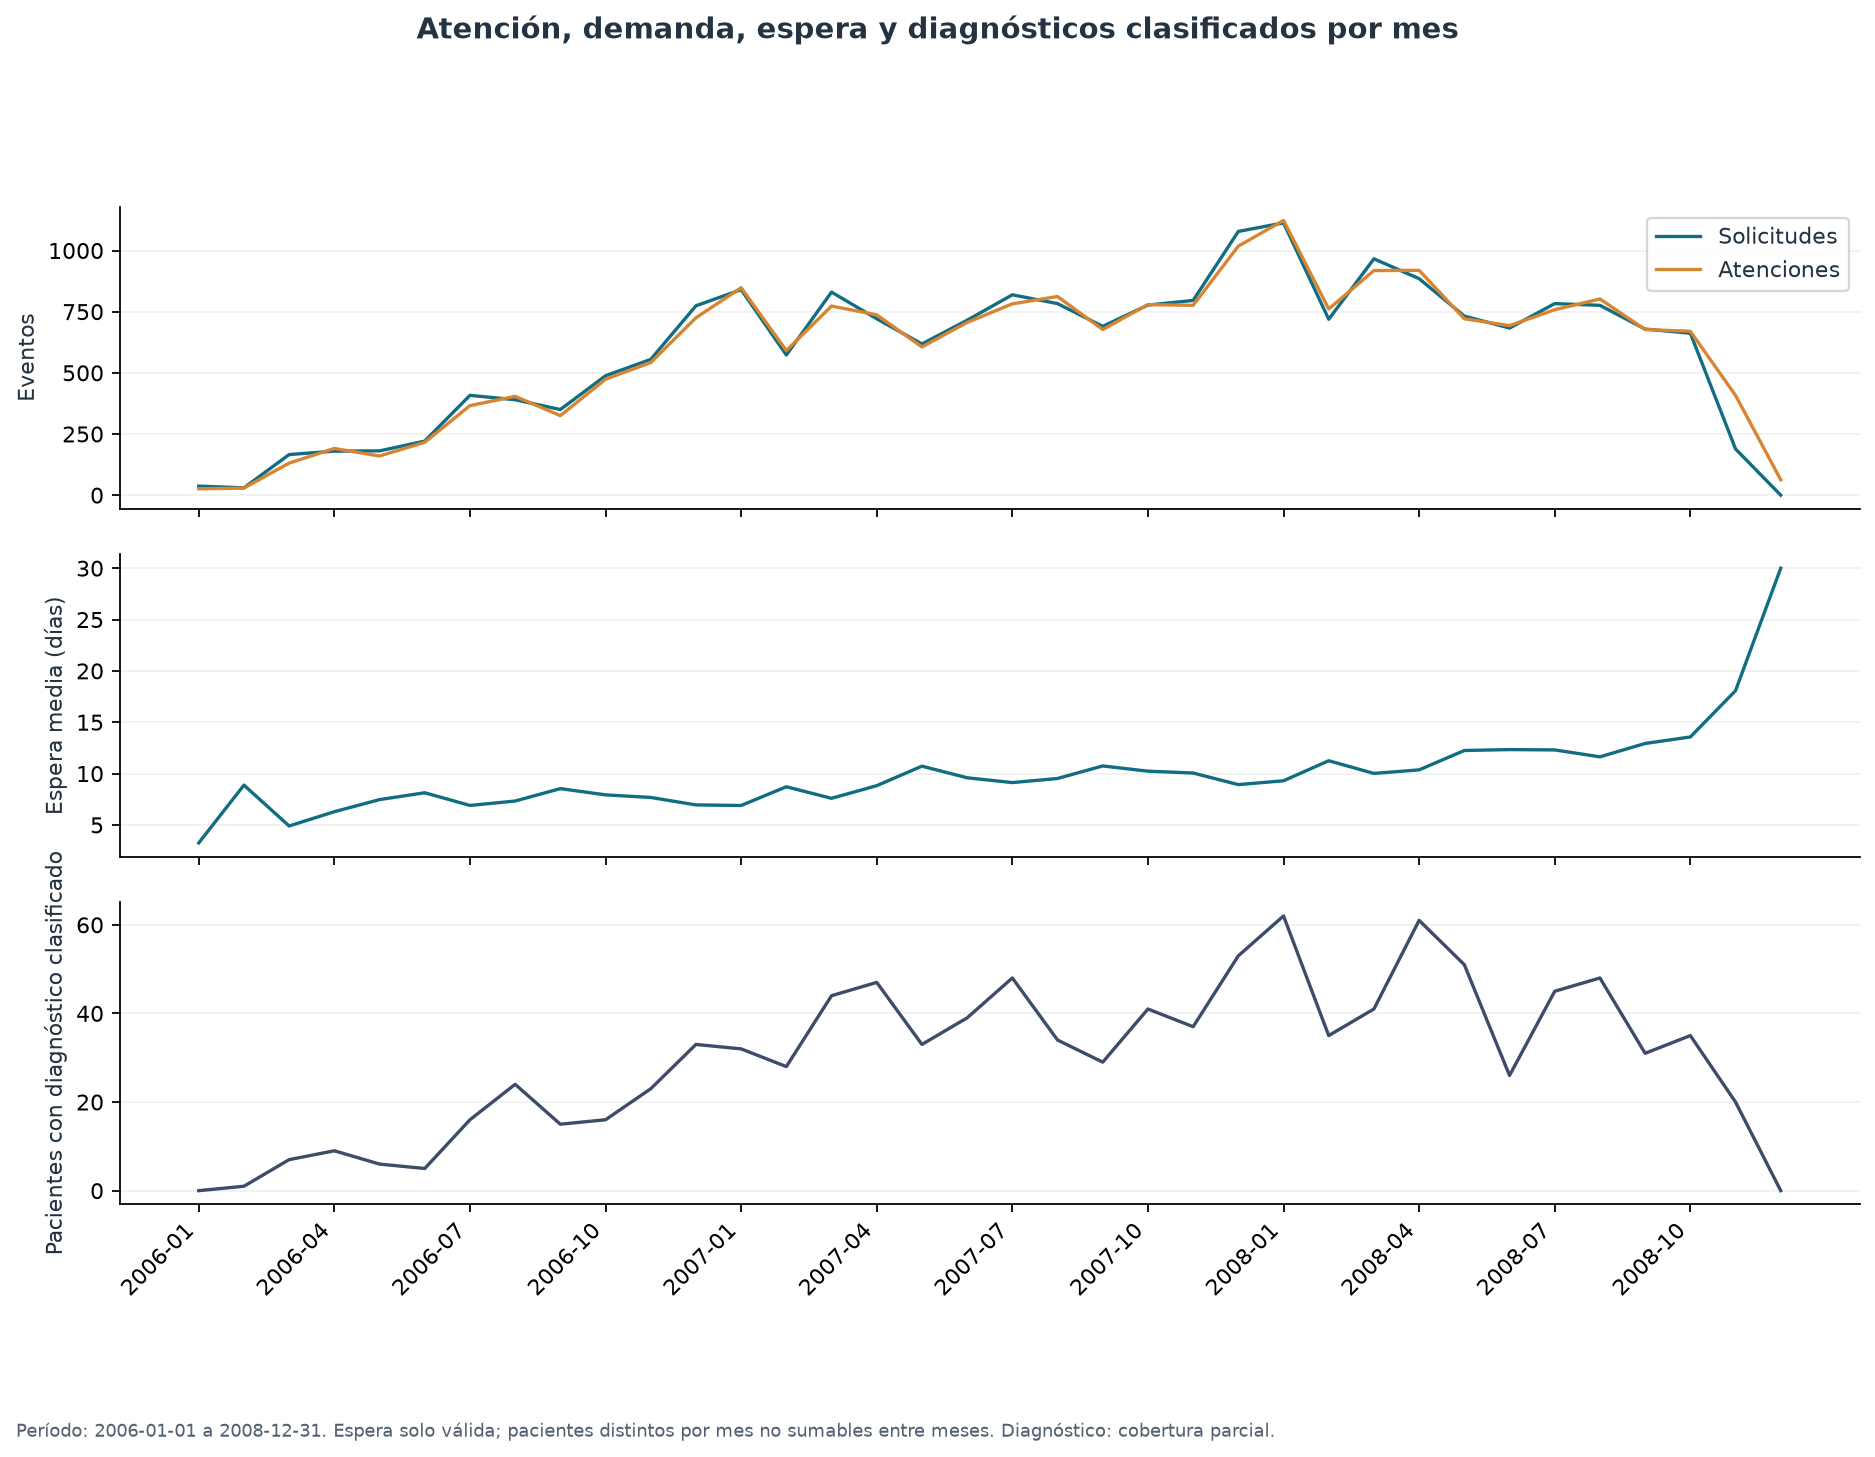

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p07_demanda_dia_semana.csv (7 registros, 5 columnas)


,dia_semana,nombre_dia,dias_calendario,solicitudes,solicitudes_por_dia
0,4,Jueves,156,3340.0,21.410
1,7,Domingo,157,3189.0,20.312
2,5,Viernes,156,3107.0,19.917
3,6,Sábado,156,3005.0,19.263
4,1,Lunes,157,3001.0,19.115
5,2,Martes,157,2807.0,17.879
6,3,Miércoles,157,2758.0,17.567


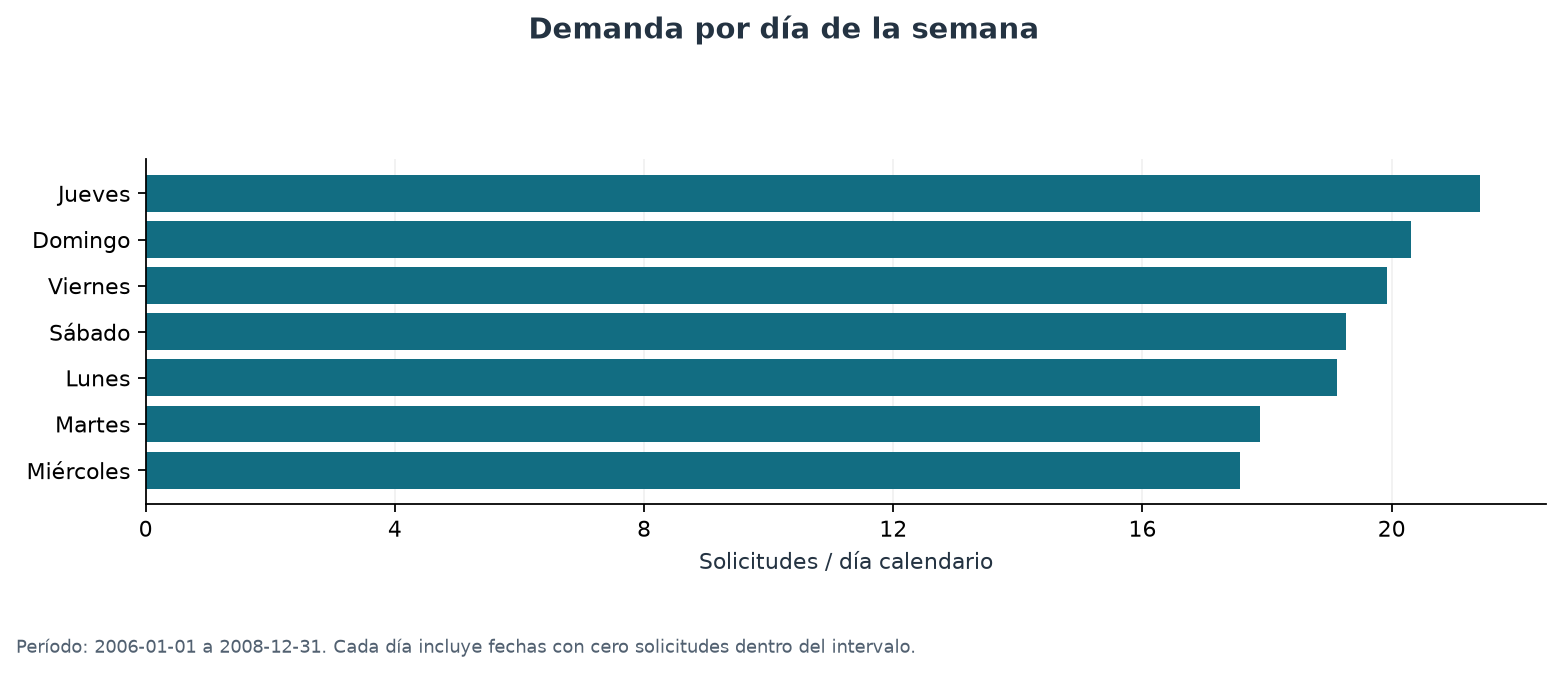

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p07_demanda_mes_dia.csv (84 registros, 5 columnas)


,mes,dia_semana,dias_calendario,solicitudes,solicitudes_por_dia
0,1,1,14,277.0,19.786
1,1,2,15,295.0,19.667
2,1,3,14,268.0,19.143
3,1,4,13,336.0,25.846
4,1,5,12,260.0,21.667
5,1,6,12,258.0,21.500
6,1,7,13,296.0,22.769
7,2,1,12,200.0,16.667
8,2,2,12,184.0,15.333
9,2,3,12,171.0,14.250


Tabla completa: **84 filas agregadas** en `p07_demanda_mes_dia.csv`.

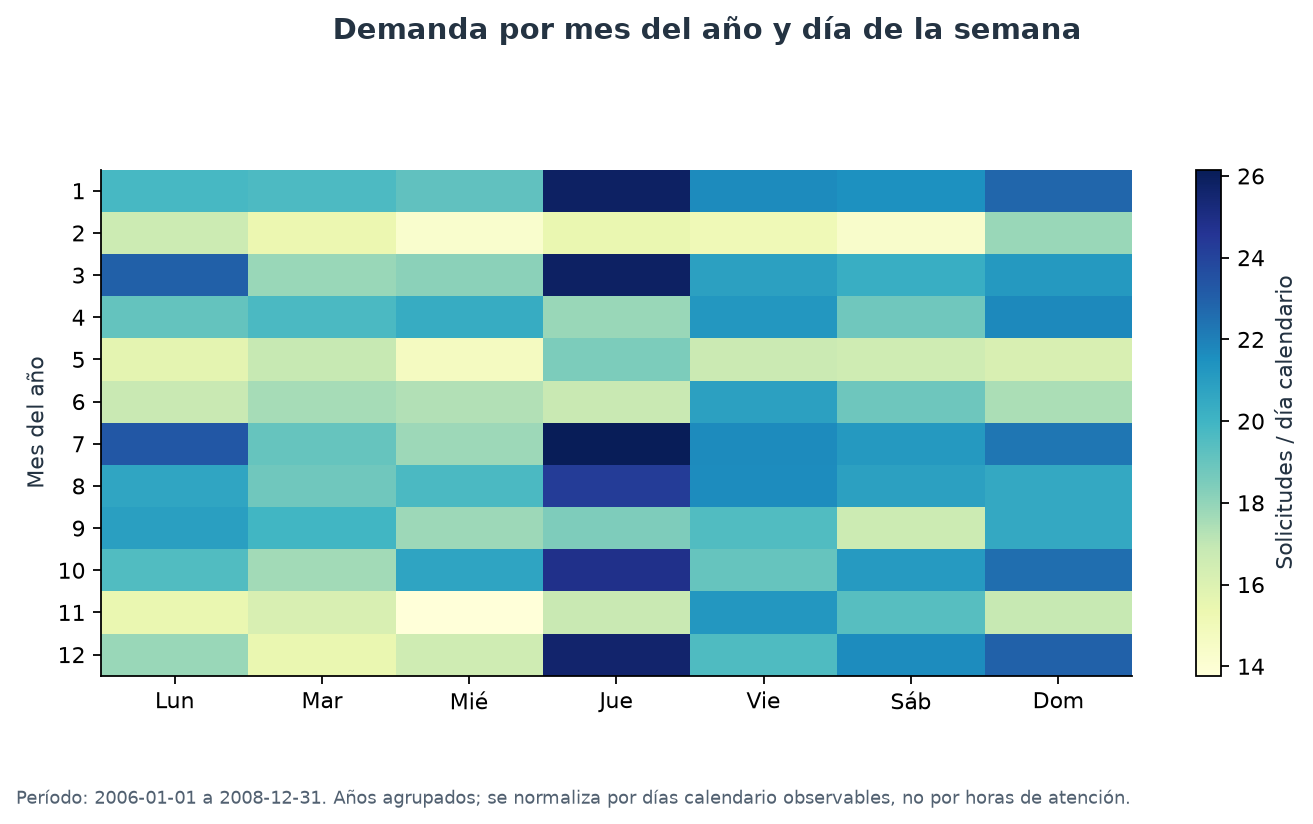

**Respuesta e interpretación.** Mayor atención mensual: 2008-01, con 1.123 eventos. Mayor demanda mensual: 2008-01, con 1.113 solicitudes. La mayor demanda media diaria corresponde a Jueves (21,41 solicitudes por día calendario). Mayor espera media mensual: 2008-12, 30,00 días, con 63 esperas válidas. Mayor número mensual de pacientes con diagnóstico textual clasificado: 2008-01, 62. El final de 2008 tiene cobertura incompleta: la ausencia de registros no demuestra ausencia de demanda o atención. Los conteos de diagnóstico observado son parciales y no permiten afirmar qué mes tuvo más enfermos en toda la población.

In [10]:
# P07: demanda, atención y espera a lo largo del calendario.


# Separar solicitudes y atenciones por su propia fecha en las series mensuales.
p07 = tabla(
    'p07_series_mensuales',
    consultar(
        'p07_meses',
        """, meses AS (SELECT DISTINCT TO_CHAR(fecha,'YYYY-MM') AS mes FROM D),
 at AS (SELECT TO_CHAR(fecha_atencion,'YYYY-MM') AS mes,COUNT(*) AS atenciones,
 COUNT(DISTINCT paciente_id) AS pacientes,COUNT(espera_valida_min) AS esperas_validas,
 ROUND(AVG(espera_valida_min),2) AS espera_media_min FROM A GROUP BY 1),
 sol AS (SELECT TO_CHAR(fecha_solicitud,'YYYY-MM') AS mes,COUNT(*) AS solicitudes FROM S GROUP BY 1),
 dx AS (SELECT TO_CHAR(a.fecha_atencion,'YYYY-MM') AS mes,COUNT(DISTINCT a.paciente_id) AS pacientes_dx_clasificado
 FROM A a JOIN public.dim_diagnostico d USING(diagnostico_id) WHERE d.clase_texto='diagnostico_observado' GROUP BY 1)
 SELECT m.mes,COALESCE(s.solicitudes,0) AS solicitudes,COALESCE(a.atenciones,0) AS atenciones,
 COALESCE(a.pacientes,0) AS pacientes,COALESCE(a.esperas_validas,0) AS esperas_validas,a.espera_media_min,
 COALESCE(x.pacientes_dx_clasificado,0) AS pacientes_dx_clasificado
 FROM meses m LEFT JOIN at a USING(mes) LEFT JOIN sol s USING(mes) LEFT JOIN dx x USING(mes) ORDER BY m.mes""",
    ),
    36,
)
if not p07.empty:
    fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    x = np.arange(len(p07))
    axs[0].plot(x, p07.solicitudes, label='Solicitudes', color=COLOR[0])
    axs[0].plot(x, p07.atenciones, label='Atenciones', color=COLOR[1])
    axs[0].legend()
    axs[0].set_ylabel('Eventos')
    axs[1].plot(x, [num(v) / 1440 for v in p07.espera_media_min], color=COLOR[0])
    axs[1].set_ylabel('Espera media (días)')
    axs[2].plot(x, p07.pacientes_dx_clasificado, color=COLOR[2])
    axs[2].set_ylabel('Pacientes con diagnóstico clasificado')
    for ax in axs:
        ax.grid(axis='y')
    saltos = max(1, len(p07) // 12)
    axs[2].set_xticks(x[::saltos], p07.mes.iloc[::saltos], rotation=45, ha='right')
    figura(
        'p07_series',
        fig,
        'Atención, demanda, espera y diagnósticos clasificados por mes',
        'Espera solo válida; pacientes distintos por mes no sumables entre meses.'
        ' Diagnóstico: cobertura parcial.',
    )

# Incluir días con cero solicitudes al calcular la demanda media por día de semana.
p07dias = tabla(
    'p07_demanda_dia_semana',
    consultar(
        'p07_dias',
        """, dias AS (
 SELECT fecha::date AS fecha,dia_semana,nombre_dia FROM D), sol AS (
 SELECT fecha_solicitud AS fecha,COUNT(*) AS eventos FROM S GROUP BY 1)
 SELECT d.dia_semana,d.nombre_dia,COUNT(*) AS dias_calendario,SUM(COALESCE(s.eventos,0)) AS solicitudes,
 ROUND(AVG(COALESCE(s.eventos,0)),3) AS solicitudes_por_dia FROM dias d LEFT JOIN sol s USING(fecha)
 GROUP BY 1,2 ORDER BY solicitudes_por_dia DESC""",
    ),
)
barras(
    'p07_dias_semana',
    p07dias,
    'nombre_dia',
    'solicitudes_por_dia',
    'Demanda por día de la semana',
    'Solicitudes / día calendario',
    'Cada día incluye fechas con cero solicitudes dentro del intervalo.',
    limite=7,
)

# Comparar mes y día de semana normalizando por días calendario.
p07heat = tabla(
    'p07_demanda_mes_dia',
    consultar(
        'p07_mes_dia',
        """, sol AS (
 SELECT fecha_solicitud AS fecha,COUNT(*) AS eventos FROM S GROUP BY 1)
 SELECT d.mes,d.dia_semana,COUNT(*) AS dias_calendario,SUM(COALESCE(s.eventos,0)) AS solicitudes,
 ROUND(AVG(COALESCE(s.eventos,0)),3) AS solicitudes_por_dia
 FROM D d LEFT JOIN sol s ON s.fecha=d.fecha::date GROUP BY 1,2 ORDER BY 1,2""",
    ),
)
if not p07heat.empty:
    hm = p07heat.pivot(
        index='mes', columns='dia_semana', values='solicitudes_por_dia'
    ).reindex(columns=range(1, 8))
    fig, ax = plt.subplots(figsize=(9, 5))
    im = ax.imshow(hm.to_numpy(dtype=float), cmap='YlGnBu', aspect='auto')
    ax.set_xticks(range(7), ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'])
    ax.set_yticks(range(len(hm)), hm.index)
    ax.set_ylabel('Mes del año')
    fig.colorbar(im, ax=ax, label='Solicitudes / día calendario')
    figura(
        'p07_mapa_calor',
        fig,
        'Demanda por mes del año y día de la semana',
        'Años agrupados; se normaliza por días calendario observables, no por horas de'
        ' atención.',
    )
comprobar(
    'p07_meses_concilian_atenciones',
    int(p07.atenciones.sum()) == int(calidad.iloc[0].eventos),
)
comprobar(
    'p07_dias_concilian_solicitudes',
    int(p07dias.solicitudes.sum()) == int(totales.solicitudes),
)
if not p07.empty and int(p07.atenciones.sum()) > 0:
    ma = p07.loc[p07.atenciones.idxmax()]
    ms = p07.loc[p07.solicitudes.idxmax()]
    dia = p07dias.iloc[0]
    texto = (
        f"Mayor atención mensual: {ma.mes}, con {fmt(ma.atenciones)} eventos. Mayor"
        f" demanda mensual: {ms.mes}, con {fmt(ms.solicitudes)} solicitudes. La mayor"
        f" demanda media diaria corresponde a {dia.nombre_dia}"
        f" ({fmt(dia.solicitudes_por_dia,2)} solicitudes por día calendario). "
    )
else:
    texto = 'No hay actividad en la selección. '
if not p07.empty and p07.espera_media_min.notna().any():
    me = p07.loc[p07.espera_media_min.idxmax()]
    texto += (
        f'Mayor espera media mensual: {me.mes}, {fmt(num(me.espera_media_min)/1440,2)}'
        f' días, con {fmt(me.esperas_validas)} esperas válidas. '
    )
if not p07.empty and int(p07.pacientes_dx_clasificado.sum()) > 0:
    mdx = p07.loc[p07.pacientes_dx_clasificado.idxmax()]
    texto += (
        'Mayor número mensual de pacientes con diagnóstico textual clasificado:'
        f' {mdx.mes}, {fmt(mdx.pacientes_dx_clasificado)}. '
    )
texto += (
    'El final de 2008 tiene cobertura incompleta: la ausencia de registros no demuestra'
    ' ausencia de demanda o atención. '
)
concluir(
    'P07',
    texto
    + 'Los conteos de diagnóstico observado son parciales y no permiten afirmar qué mes'
    ' tuvo más enfermos en toda la población.',
)


## P08. Costo promedio de atención de usuarios

El costo real no está disponible. Se informa tarifa estimada media por remisión y suma de tarifas por paciente
con al menos una remisión tarifada, con denominadores distintos. La cobertura se calcula sobre los eventos
seleccionados; no se asigna costo cero a los eventos sin tarifa.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL calcula sumas, medias, pacientes distintos y cobertura con denominadores explícitos. Matplotlib crea los dos gráficos y Python compone la interpretación; solo el dibujo aproxima los decimales.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `figura` | compone, guarda y muestra imágenes con Matplotlib/IPython; el Core no renderiza gráficos Python. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `num` | usa missing del Core y aproxima números a float solo para visualización. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `int` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| Dibujo e IPython | `ax.bar`, `ax.grid`, `ax.set_ylabel`, `plt.subplots` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p08_estimacion_tarifa.csv (1 registros, 8 columnas)


,eventos_totales,pacientes_atendidos,remisiones_tarifadas,pacientes_con_tarifa,tarifa_total,tarifa_media_remision,tarifa_por_paciente_con_tarifa,cobertura_eventos_pct
0,21207,504,16742,504,4380604114.00,261653.57,8691674.83,78.95


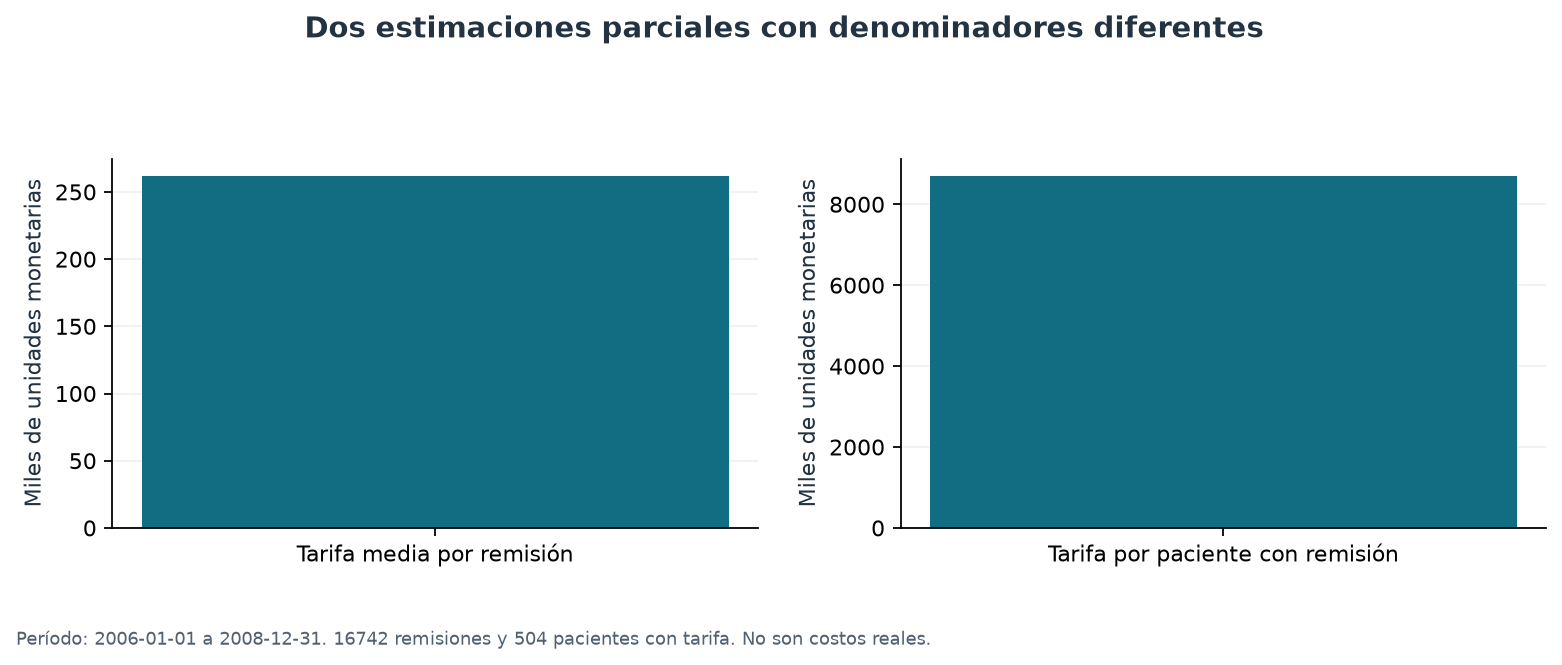

**Respuesta e interpretación.** La tarifa media por remisión es 261.653,57 y la suma de tarifas por paciente con remisión es 8.691.674,83 unidades monetarias. La cobertura de tarifa es 78,95 % de los eventos. No se conoce el costo real promedio de todas las atenciones.

In [11]:
# P08: dos promedios parciales de tarifa con denominadores diferentes.


# Separar tarifa por remisión de tarifa por paciente con alguna remisión tarifada.
p08 = tabla(
    'p08_estimacion_tarifa',
    consultar(
        'p08_estimacion_tarifa',
        """SELECT COUNT(*) AS eventos_totales,
 COUNT(DISTINCT paciente_id) AS pacientes_atendidos,COUNT(tarifa_servicio_catalogo) AS remisiones_tarifadas,
 COUNT(DISTINCT paciente_id) FILTER(WHERE tarifa_informada) AS pacientes_con_tarifa,
 SUM(tarifa_servicio_catalogo)::text AS tarifa_total,ROUND(AVG(tarifa_servicio_catalogo),2)::text AS tarifa_media_remision,
 ROUND(SUM(tarifa_servicio_catalogo)/NULLIF(COUNT(DISTINCT paciente_id) FILTER(WHERE tarifa_informada),0),2)::text AS tarifa_por_paciente_con_tarifa,
 ROUND(100.0*COUNT(tarifa_servicio_catalogo)/NULLIF(COUNT(*),0),2) AS cobertura_eventos_pct FROM A""",
    ),
)

# Dibujar solo si existen remisiones tarifadas; desconocido no equivale a cero.
p08r = p08.iloc[0]
if int(p08r.remisiones_tarifadas) > 0:
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    for ax, k, tit in [
        (axs[0], 'tarifa_media_remision', 'Tarifa media por remisión'),
        (axs[1], 'tarifa_por_paciente_con_tarifa', 'Tarifa por paciente con remisión'),
    ]:
        ax.bar([tit], [num(p08r[k]) / 1000], color=COLOR[0])
        ax.set_ylabel('Miles de unidades monetarias')
        ax.grid(axis='y')
    figura(
        'p08_tarifas_medias',
        fig,
        'Dos estimaciones parciales con denominadores diferentes',
        f'{int(p08r.remisiones_tarifadas)} remisiones y'
        f' {int(p08r.pacientes_con_tarifa)} pacientes con tarifa. No son costos'
        ' reales.',
    )
concluir(
    'P08',
    f"La tarifa media por remisión es {fmt(p08r.tarifa_media_remision,2)} y la suma de"
    " tarifas por paciente con remisión es"
    f" {fmt(p08r.tarifa_por_paciente_con_tarifa,2)} unidades monetarias. La cobertura"
    f" de tarifa es {fmt(p08r.cobertura_eventos_pct,2)} % de los eventos. No se conoce"
    " el costo real promedio de todas las atenciones.",
)


## P09. Estimación en cohortes con diagnósticos de alto costo

Una cohorte contiene pacientes con al menos un **diagnóstico textual observado** del grupo en el período;
no se forma desde antecedentes familiares ni medicamentos. Se separa tarifa de eventos con ese diagnóstico
y tarifa de todas las remisiones de esos pacientes durante la selección. Las cohortes pueden solaparse y
la clasificación textual es parcial, sin validación clínica. No es costo real de tratamiento.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL define cohortes no excluyentes y separa tarifas de eventos diagnósticos y de toda la cohorte. Python redacta los resultados sin sumar cohortes solapadas.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `str.join` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| DataFrames y matrices | `p09.itertuples` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p09_cohortes_diagnosticas.csv (4 registros, 10 columnas)


,grupo,pacientes_cohorte,eventos_cohorte,remisiones_tarifadas,pacientes_con_tarifa,tarifa_cohorte,tarifa_por_paciente_con_tarifa,eventos_diagnostico,eventos_dx_tarifados,tarifa_eventos_diagnostico
0,deficiencia_renal,157,6730,5337,157,1646031759.00,10484278.72,1267,1104,53211700.00
1,vih_sida,53,3986,3628,53,1426872551.00,26922123.60,212,159,5533200.00
2,cancer,48,2868,2350,48,844985972.00,17603874.42,326,326,16111814.00
3,diabetes,57,2387,2076,57,301473596.00,5289010.46,167,110,1342000.00


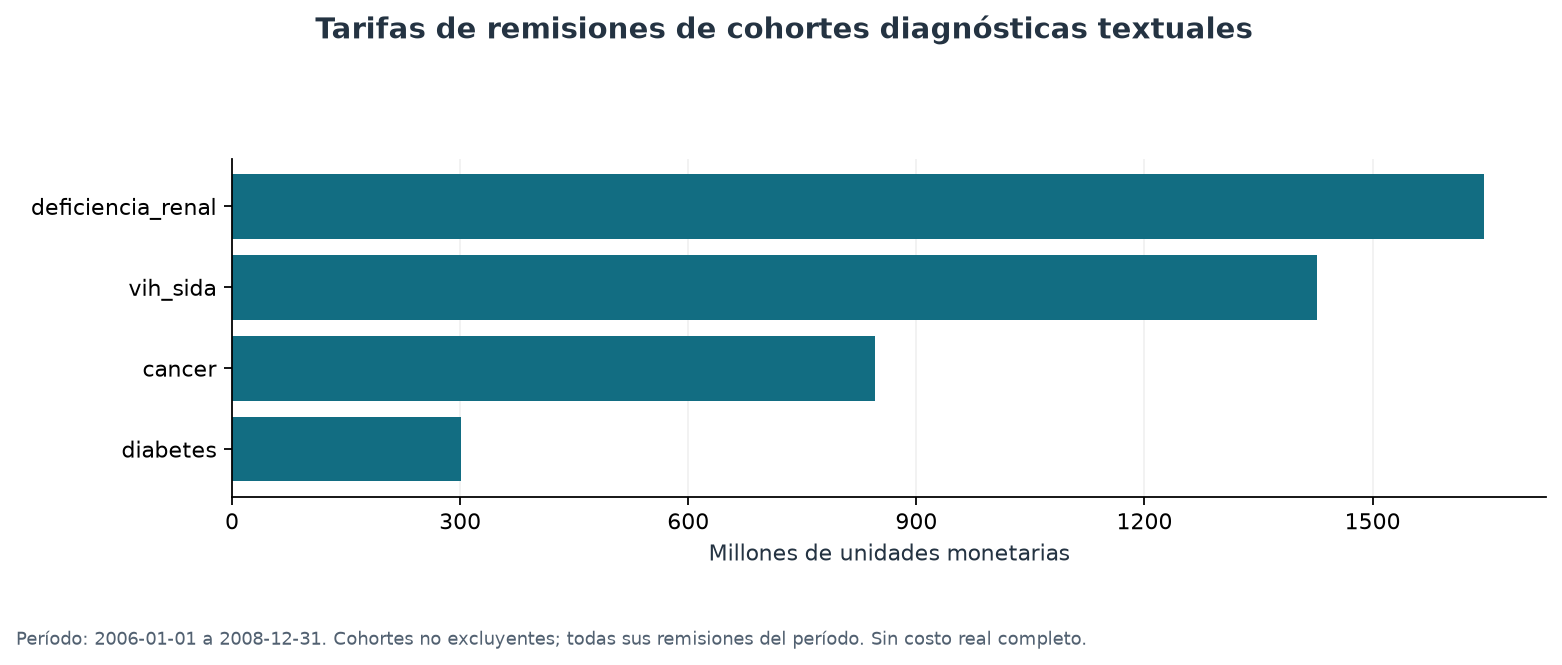

**Respuesta e interpretación.** Las cohortes observadas son: deficiencia_renal (157 pacientes, 1.646.031.759,00 unidades en tarifas de remisiones), vih_sida (53 pacientes, 1.426.872.551,00 unidades en tarifas de remisiones), cancer (48 pacientes, 844.985.972,00 unidades en tarifas de remisiones), diabetes (57 pacientes, 301.473.596,00 unidades en tarifas de remisiones). El detalle separa eventos con el diagnóstico y toda la cohorte. No se suman cohortes solapadas ni se interpreta la estimación como costo real de SIDA, cáncer o insuficiencia renal.

In [12]:
# P09: estimaciones de tarifas para cohortes diagnósticas textuales.


# Separar eventos con el diagnóstico de todos los eventos de su cohorte.
p09 = tabla(
    'p09_cohortes_diagnosticas',
    consultar(
        'p09_cohortes',
        """, cohortes AS (
 SELECT DISTINCT d.grupo_textual AS grupo,a.paciente_id FROM A a JOIN public.dim_diagnostico d USING(diagnostico_id)
 WHERE d.clase_texto='diagnostico_observado' AND d.grupo_textual IN ('vih_sida','deficiencia_renal','cancer','diabetes')),
 directos AS (SELECT d.grupo_textual AS grupo,COUNT(*) AS eventos_diagnostico,
 COUNT(a.tarifa_servicio_catalogo) AS eventos_dx_tarifados,SUM(a.tarifa_servicio_catalogo) AS tarifa_eventos_diagnostico
 FROM A a JOIN public.dim_diagnostico d USING(diagnostico_id) WHERE d.clase_texto='diagnostico_observado' GROUP BY 1)
 SELECT c.grupo,COUNT(DISTINCT c.paciente_id) AS pacientes_cohorte,COUNT(*) AS eventos_cohorte,
 COUNT(a.tarifa_servicio_catalogo) AS remisiones_tarifadas,
 COUNT(DISTINCT c.paciente_id) FILTER(WHERE a.tarifa_informada) AS pacientes_con_tarifa,
 SUM(a.tarifa_servicio_catalogo)::text AS tarifa_cohorte,
 ROUND(SUM(a.tarifa_servicio_catalogo)/NULLIF(COUNT(DISTINCT c.paciente_id) FILTER(WHERE a.tarifa_informada),0),2)::text AS tarifa_por_paciente_con_tarifa,
 MAX(d.eventos_diagnostico) AS eventos_diagnostico,MAX(d.eventos_dx_tarifados) AS eventos_dx_tarifados,
 MAX(d.tarifa_eventos_diagnostico)::text AS tarifa_eventos_diagnostico
 FROM cohortes c JOIN A a USING(paciente_id) JOIN directos d USING(grupo)
 GROUP BY c.grupo ORDER BY SUM(a.tarifa_servicio_catalogo) DESC NULLS LAST""",
    ),
)
barras(
    'p09_tarifas_cohortes',
    p09,
    'grupo',
    'tarifa_cohorte',
    'Tarifas de remisiones de cohortes diagnósticas textuales',
    'Millones de unidades monetarias',
    'Cohortes no excluyentes; todas sus remisiones del período. Sin costo real'
    ' completo.',
    escala=1e6,
)
concluir(
    'P09',
    (
        'Las cohortes observadas son: '
        + ', '.join(
            f"{r.grupo} ({fmt(r.pacientes_cohorte)} pacientes,"
            f" {fmt(r.tarifa_cohorte,2)} unidades en tarifas de remisiones)"
            for r in p09.itertuples()
        )
        + '. '
        if not p09.empty
        else 'No hay diagnósticos clasificados de estas cohortes. '
    )
    + 'El detalle separa eventos con el diagnóstico y toda la cohorte. No se suman'
    ' cohortes solapadas ni se interpreta la estimación como costo real de SIDA,'
    ' cáncer o insuficiencia renal.',
)


## P10. Demanda geográfica y desvinculación por mora

La geografía disponible es departamento/municipio de la IPS asociada al médico, no regional de EPS ni residencia.
La mora no se puede determinar: faltan obligaciones, vencimientos y causa del retiro. Un retiro sin EPS destino
no prueba falta de pago.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL agrega demanda/retiros. pandas DataFrame construye la tabla documental de datos faltantes; Python expresa qué no se puede calcular. No existe una función Core que complete obligaciones o causas ausentes.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| DataFrames y matrices | `pd.DataFrame` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p10_demanda_departamento.csv (7 registros, 3 columnas)


,departamento,solicitudes,pacientes_solicitantes
0,valle del cauca,8036,449
1,cundinamarca,3750,380
2,caqueta,2381,314
3,antioquia,2054,341
4,choco,1853,295
5,meta,1567,314
6,cordoba,1566,293


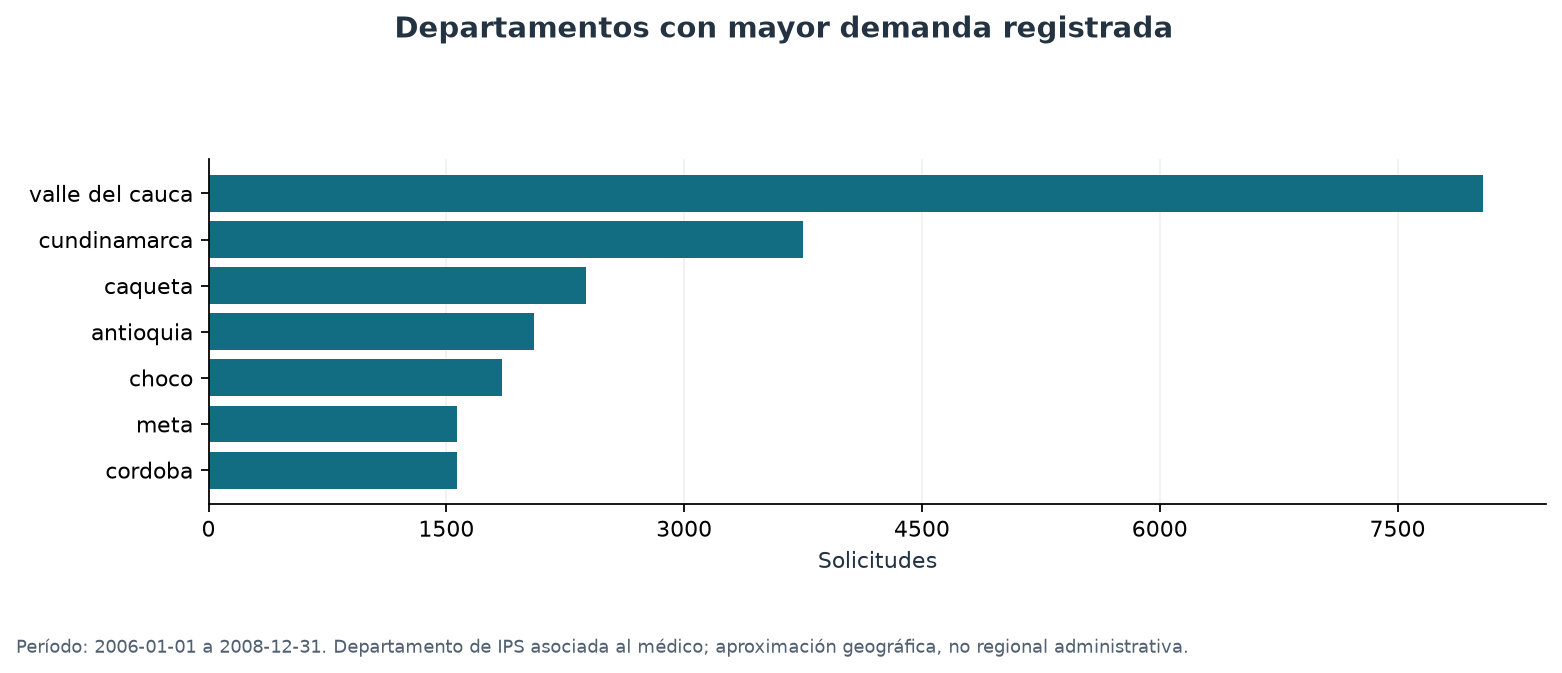

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p10_retiros_cobertura.csv (1 registros, 3 columnas)


,retiros,con_eps_destino,destino_desconocido
0,89,48,41


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p10_mora_datos_faltantes.csv (2 registros, 3 columnas)


,indicador,estado,datos_requeridos
0,Desvinculación por pago no oportuno,No calculable,"Causa de retiro, período, obligación y vencimi..."
1,Demanda por regional EPS,No calculable como regional,Catálogo de regionales y asignación vigente


**Respuesta e interpretación.** El departamento con más solicitudes es valle del cauca, con 8.036 solicitudes. De 89 retiros, 41 no informan destino. Ninguno puede atribuirse a mora con los campos disponibles.

In [13]:
# P10: demanda por departamento y cobertura de retiros.


# Usar la geografía de la IPS asociada al médico como aproximación declarada.
p10 = tabla(
    'p10_demanda_departamento',
    consultar(
        'p10_demanda',
        """SELECT departamento,COUNT(*) AS solicitudes,
 COUNT(DISTINCT paciente_id) AS pacientes_solicitantes FROM S GROUP BY 1 ORDER BY solicitudes DESC,departamento""",
    ),
)
barras(
    'p10_demanda',
    p10,
    'departamento',
    'solicitudes',
    'Departamentos con mayor demanda registrada',
    'Solicitudes',
    'Departamento de IPS asociada al médico; aproximación geográfica, no regional'
    ' administrativa.',
)

# Separar retiros con y sin EPS de destino; ninguno demuestra mora por sí solo.
p10r = tabla(
    'p10_retiros_cobertura',
    consultar(
        'p10_retiros',
        """SELECT COUNT(*) AS retiros,
 COUNT(*) FILTER(WHERE destino_informado) AS con_eps_destino,
 COUNT(*) FILTER(WHERE NOT destino_informado) AS destino_desconocido FROM R""",
    ),
)
tabla(
    'p10_mora_datos_faltantes',
    pd.DataFrame(
        [
            {
                'indicador': 'Desvinculación por pago no oportuno',
                'estado': 'No calculable',
                'datos_requeridos': (
                    'Causa de retiro, período, obligación y vencimiento'
                ),
            },
            {
                'indicador': 'Demanda por regional EPS',
                'estado': 'No calculable como regional',
                'datos_requeridos': 'Catálogo de regionales y asignación vigente',
            },
        ]
    ),
)
concluir(
    'P10',
    (
        f"El departamento con más solicitudes es {p10.iloc[0].departamento}, con"
        f" {fmt(p10.iloc[0].solicitudes)} solicitudes. "
        if not p10.empty
        else 'No hay solicitudes seleccionadas. '
    )
    + f"De {fmt(p10r.iloc[0].retiros)} retiros, {fmt(p10r.iloc[0].destino_desconocido)}"
    " no informan destino. Ninguno puede atribuirse a mora con los campos"
    " disponibles.",
)


## P11. Costo promedio de recetas

**No calculable con la bodega actual.** No existe catálogo de nombres/precios de medicamentos, cantidades
prescritas ni costo facturado por receta. El número de códigos o las tarifas de remisiones no sustituyen
estos datos. No se dibuja un gráfico de costo cero.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `CSV_Loader.save_csv`, `DB_Extractor.execute_query`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL mide cobertura de recetas/catálogos; pandas DataFrame documenta requisitos ausentes. Python informa que costo desconocido no es cero; ninguna función Core puede inventar precios/cantidades faltantes.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| DataFrames y matrices | `pd.DataFrame` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |

In [14]:
# P11: comprobar si existen datos suficientes para valorar recetas.


# Contar fórmulas, códigos y cobertura de nombres/precios antes de evaluar el costo.
p11 = tabla(
    'p11_cobertura_recetas',
    consultar(
        'p11_cobertura',
        """SELECT (SELECT COUNT(*) FROM F) AS formulas,
 COUNT(*) AS presencias_formula_codigo,COUNT(DISTINCT b.medicamento_id) AS codigos,
 COUNT(DISTINCT b.medicamento_id) FILTER(WHERE m.nombre IS NOT NULL) AS codigos_con_nombre,
 COUNT(DISTINCT b.medicamento_id) FILTER(WHERE m.precio IS NOT NULL) AS codigos_con_precio
 FROM F f JOIN public.puente_formula_medicamento b USING(codigo_formula)
 JOIN public.dim_medicamento m USING(medicamento_id)""",
    ),
)
tabla(
    'p11_requisitos_costo',
    pd.DataFrame(
        [
            {
                'dato': 'Precio vigente o valor facturado',
                'uso': 'Valorar cada medicamento de la receta',
                'disponible': False,
            },
            {
                'dato': 'Cantidad y unidad',
                'uso': 'Calcular importe de cada línea',
                'disponible': False,
            },
            {
                'dato': 'Correspondencia de catálogo',
                'uso': 'Identificar fármaco y presentación',
                'disponible': False,
            },
        ]
    ),
)
concluir(
    'P11',
    f"Se observan {fmt(p11.iloc[0].formulas)} fórmulas y {fmt(p11.iloc[0].codigos)}"
    f" códigos; {fmt(p11.iloc[0].codigos_con_precio)} códigos tienen precio informado."
    " El costo promedio de recetas es desconocido, no cero. Requiere precios/valores"
    " facturados y cantidades.",
    estado='no_calculable',
)


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p11_cobertura_recetas.csv (1 registros, 5 columnas)


,formulas,presencias_formula_codigo,codigos,codigos_con_nombre,codigos_con_precio
0,7484,15770,166,0,0


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p11_requisitos_costo.csv (3 registros, 3 columnas)


,dato,uso,disponible
0,Precio vigente o valor facturado,Valorar cada medicamento de la receta,False
1,Cantidad y unidad,Calcular importe de cada línea,False
2,Correspondencia de catálogo,Identificar fármaco y presentación,False


**Respuesta e interpretación.** Se observan 7.484 fórmulas y 166 códigos; 0 códigos tienen precio informado. El costo promedio de recetas es desconocido, no cero. Requiere precios/valores facturados y cantidades.

## P12. Perfil de provenientes de otras EPS y de pagadores tardíos

El primer perfil se limita a cotizantes con dato propio. Las proporciones se calculan dentro de cada grupo
de procedencia y atributo, incluyendo desconocidos. La edad corresponde al corte histórico mostrado en la
cabecera; los perfiles son una fotografía sin historia. No se puede identificar pago tardío con fecha e importe
de pago aislados.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `CSV_Loader.save_csv`, `ConvertOperations.fill_nulls`, `DB_Extractor.execute_query`, `DataSelect.filter_equal`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL calcula perfiles y porcentajes con ventanas. pandas pivot/unique/reindex/groupby/idxmax y NumPy/Matplotlib preparan perfiles y categorías modales; filtros y relleno visual se delegan al Core. Las ventanas usan el denominador declarado, no un promedio genérico.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `completar_matriz` | delega los ceros de matrices de visualización a ConvertOperations.fill_nulls; no imputa medidas desconocidas. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `figura` | compone, guarda y muestra imágenes con Matplotlib/IPython; el Core no renderiza gráficos Python. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `num` | usa missing del Core y aproxima números a float solo para visualización. |
| `perfil_grafico` | usa filtros/relleno Core; conserva pivot, disposición de ejes y dibujo externo. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `atr.replace`, `enumerate`, `len`, `list`, `max`, `modal.append`, `str`, `str.join`, `textwrap.fill`, `zip` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| DataFrames y matrices | `S.filter_equal(…).groupby`, `df.atributo.unique`, `df[…].unique`, `g.cotizantes.idxmax`, `np.arange`, `np.zeros`, `p12n.itertuples`, `pivot.reindex`, `sub.pivot` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `ax.axis`, `ax.bar`, `ax.grid`, `ax.set_title`, `ax.set_xticks`, `ax.set_ylabel`, `ax.set_ylim`, `axs.ravel`, `axs[…].get_legend_handles_labels`, `fig.legend`, `plt.subplots` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p12_tamano_grupos.csv (2 registros, 2 columnas)

,procedencia,cotizantes
0,No proviene de otra EPS,541
1,Proviene de otra EPS,559


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p12_perfil_procedencia.csv (36 registros, 5 columnas)


,procedencia,atributo,categoria,cotizantes,grupo_pct
0,No proviene de otra EPS,escolaridad,universitaria,143,26.43
1,No proviene de otra EPS,escolaridad,técnico,142,26.25
2,No proviene de otra EPS,escolaridad,desconocido,133,24.58
3,No proviene de otra EPS,escolaridad,postgrado,123,22.74
4,Proviene de otra EPS,escolaridad,postgrado,147,26.30
5,Proviene de otra EPS,escolaridad,desconocido,143,25.58
6,Proviene de otra EPS,escolaridad,técnico,137,24.51
7,Proviene de otra EPS,escolaridad,universitaria,132,23.61
8,No proviene de otra EPS,estrato,3,117,21.63
9,No proviene de otra EPS,estrato,5,113,20.89


Tabla completa: **36 filas agregadas** en `p12_perfil_procedencia.csv`.

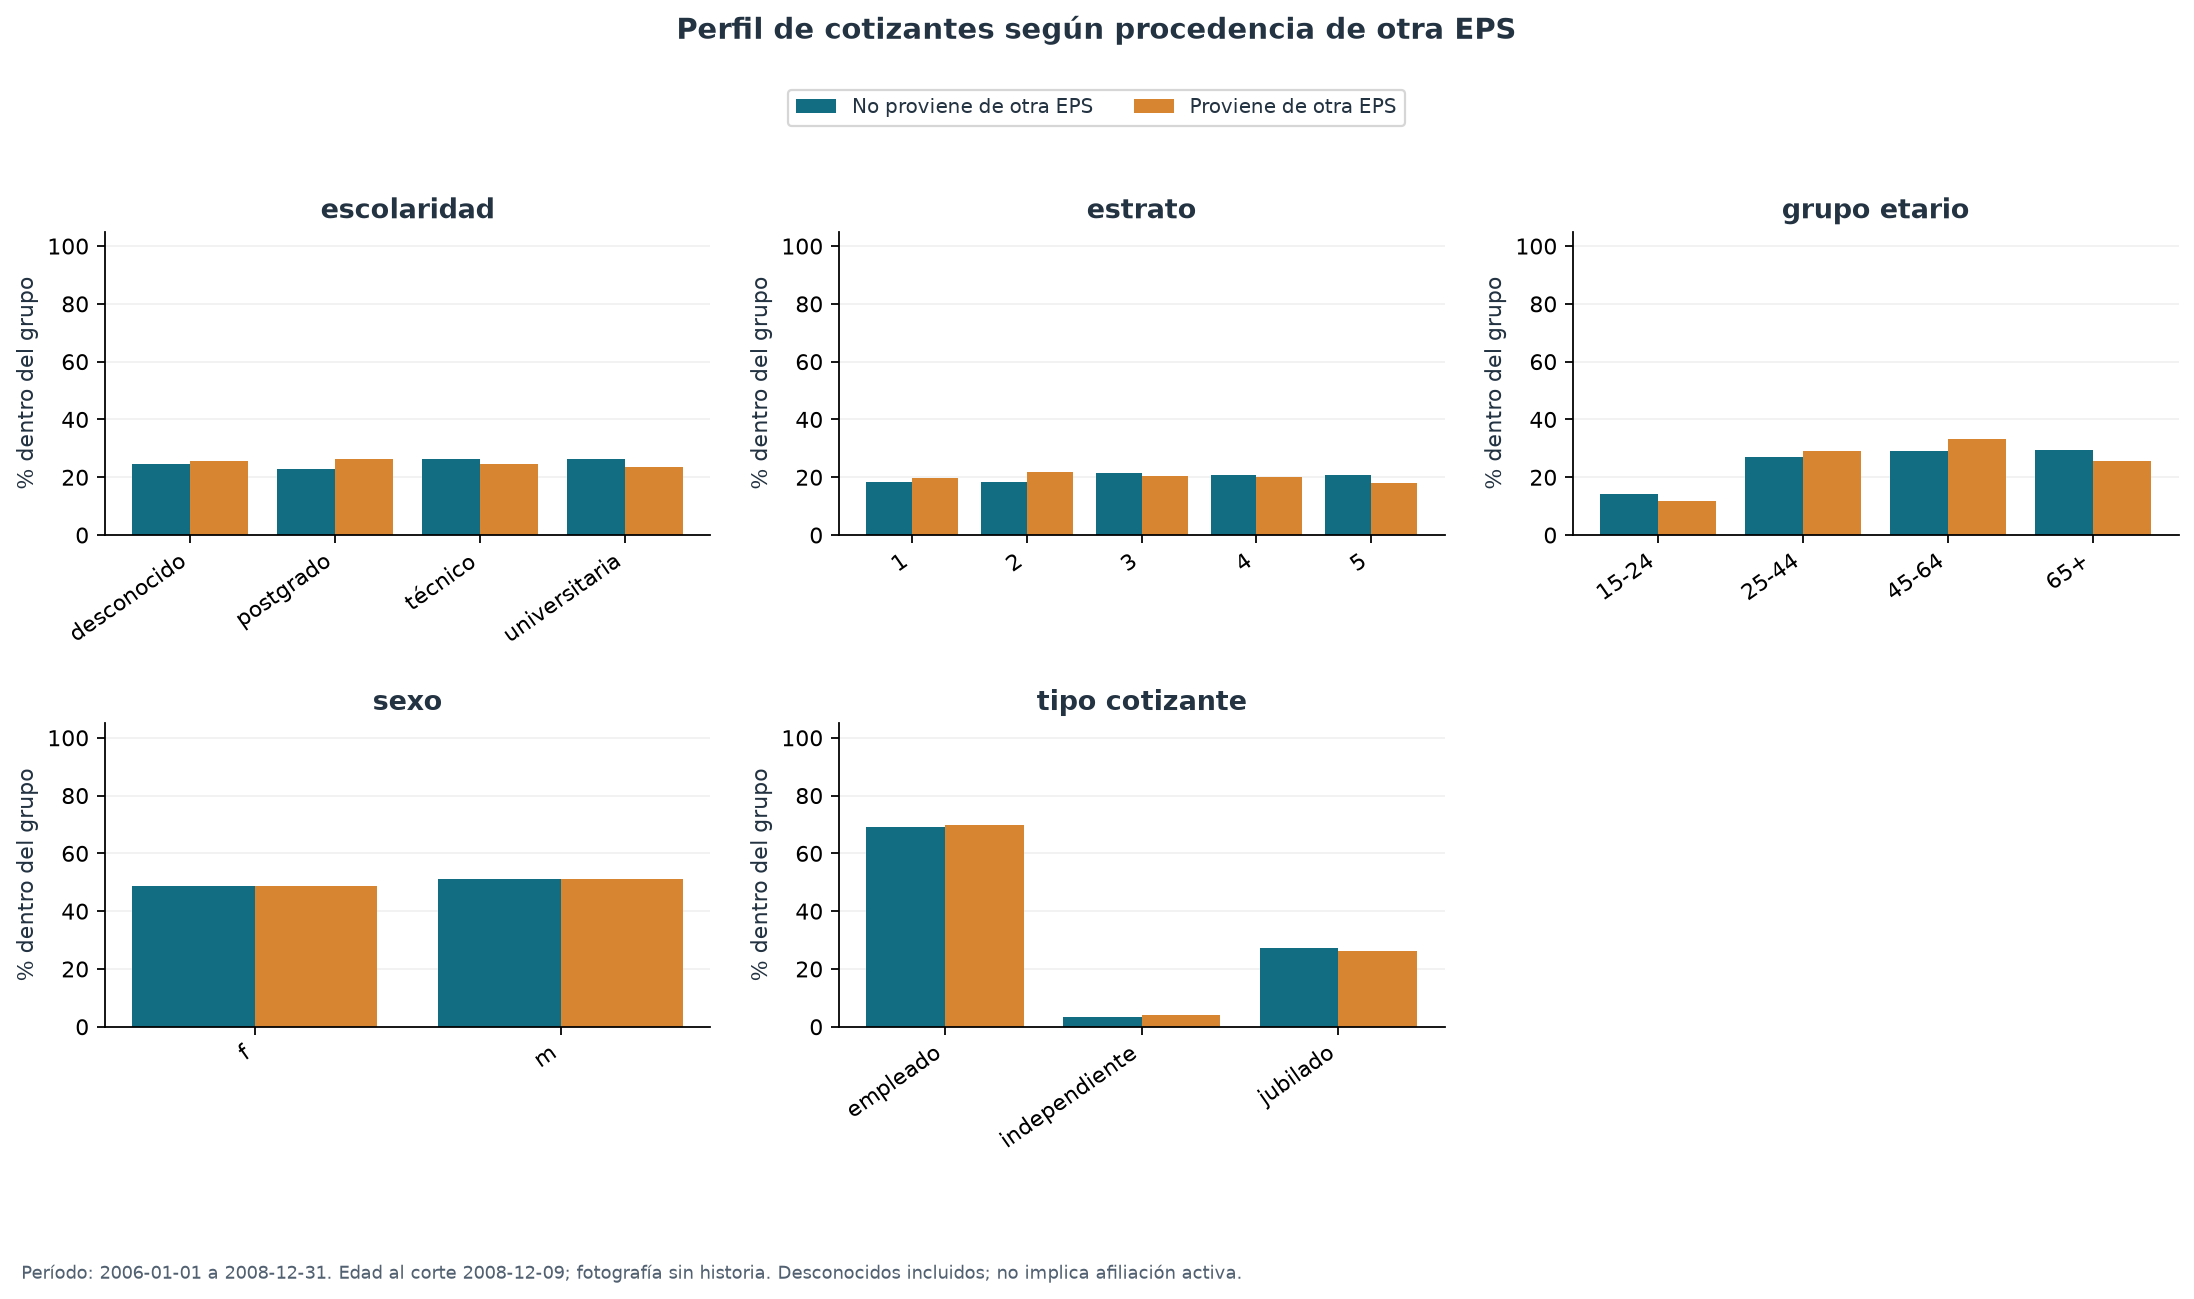

**Respuesta e interpretación.** No proviene de otra EPS: 541 cotizantes; Proviene de otra EPS: 559 cotizantes.  Categorías modales en quienes provienen de otra EPS: escolaridad: postgrado (26,30 %), estrato: 2 (21,65 %), grupo_etario: 45-64 (33,27 %), sexo: m (51,16 %), tipo_cotizante: empleado (69,95 %). Las distribuciones comparan sexo, estrato, tipo, escolaridad y edad al corte. No se conoce quién paga tarde: faltan período, obligación y vencimiento.

In [15]:
# P12: perfiles de cotizantes según procedencia de otra EPS.


# Calcular el tamaño de cada grupo que servirá como denominador del perfil.
p12n = tabla(
    'p12_tamano_grupos',
    consultar(
        'p12_grupos',
        """SELECT procedencia,COUNT(*) AS cotizantes FROM PC GROUP BY 1 ORDER BY 1""",
    ),
)

# Incluir desconocidos y calcular porcentajes dentro de cada procedencia y atributo.
p12 = tabla(
    'p12_perfil_procedencia',
    consultar(
        'p12_perfil',
        """, perfiles AS (
 SELECT p.procedencia,v.atributo,COALESCE(v.categoria,'desconocido') AS categoria,COUNT(*) AS cotizantes
 FROM PC p CROSS JOIN LATERAL (VALUES ('sexo',p.sexo),('estrato',p.estrato_propio),('tipo_cotizante',p.tipo_cotizante_propio),
 ('escolaridad',p.escolaridad_propia),('grupo_etario',p.grupo_corte)) v(atributo,categoria) GROUP BY 1,2,3)
 SELECT *,ROUND(100.0*cotizantes/SUM(cotizantes) OVER(PARTITION BY procedencia,atributo),2) AS grupo_pct
 FROM perfiles ORDER BY atributo,procedencia,cotizantes DESC,categoria""",
    ),
    25,
)


def perfil_grafico(nombre, df, col_grupo, titulo, nota):
    # Comparar porcentajes por atributo manteniendo la leyenda común entre paneles.
    if df.empty:
        return
    atributos = list(df.atributo.unique())
    fig, axs = plt.subplots(2, 3, figsize=(14, 8))
    axs = axs.ravel()
    grupos = list(df[col_grupo].unique())
    for ax, atr in zip(axs, atributos):
        sub = S.filter_equal(df, 'atributo', atr, show=0)
        pivot = completar_matriz(
            sub.pivot(index='categoria', columns=col_grupo, values='grupo_pct')
        )
        if atr == 'grupo_etario':
            pivot = pivot.reindex([x for x in ORDEN_EDAD if x in pivot.index])
        x = np.arange(len(pivot))
        w = 0.8 / max(1, len(grupos))
        for j, g in enumerate(grupos):
            ax.bar(
                x + j * w,
                [num(v) for v in pivot[g]] if g in pivot else np.zeros(len(pivot)),
                width=w,
                label=g,
                color=COLOR[j % len(COLOR)],
            )
        ax.set_xticks(
            x + w * (len(grupos) - 1) / 2,
            [textwrap.fill(str(v), 14) for v in pivot.index],
            rotation=35,
            ha='right',
        )
        ax.set_title(atr.replace('_', ' '))
        ax.set_ylabel('% dentro del grupo')
        ax.grid(axis='y')
        ax.set_ylim(0, 105)
    for ax in axs[len(atributos) :]:
        ax.axis('off')
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.95),
        ncol=max(1, len(grupos)),
        fontsize=9,
    )
    figura(nombre, fig, titulo, nota)


perfil_grafico(
    'p12_perfil',
    p12,
    'procedencia',
    'Perfil de cotizantes según procedencia de otra EPS',
    f'Edad al corte {CORTE}; fotografía sin historia. Desconocidos incluidos; no'
    ' implica afiliación activa.',
)

# Obtener categorías modales solo para cotizantes que provienen de otra EPS.
modal = []
for atr, g in S.filter_equal(
    p12, 'procedencia', 'Proviene de otra EPS', show=0
).groupby('atributo'):
    r = g.loc[g.cotizantes.idxmax()]
    modal.append(f"{atr}: {r.categoria} ({fmt(r.grupo_pct,2)} %)")
texto_modal = (
    (' Categorías modales en quienes provienen de otra EPS: ' + ', '.join(modal) + '. ')
    if modal
    else ''
)
concluir(
    'P12',
    (
        '; '.join(
            f"{r.procedencia}: {fmt(r.cotizantes)} cotizantes"
            for r in p12n.itertuples()
        )
        + '. '
        if not p12n.empty
        else 'No hay cotizantes registrados antes del corte con estos filtros. '
    )
    + texto_modal
    + 'Las distribuciones comparan sexo, estrato, tipo, escolaridad y edad al corte. No'
    ' se conoce quién paga tarde: faltan período, obligación y vencimiento.',
)


## P13. Enfermedades frecuentes por sexo, edad y estrato

Se usa sexo registrado en el origen; no se infiere identidad de género. Solo las etiquetas con clase
`diagnostico_observado` se presentan como diagnósticos textuales; controles, seguimiento y no clasificados
se contabilizan aparte. Estrato familiar puede provenir del titular y edad es a fecha de atención.
No se estima prevalencia clínica ni se consideran antecedentes del familiar como enfermedad del paciente.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `ConvertOperations.fill_nulls`, `DB_Extractor.execute_query`, `DataSelect.filter_equal`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL cuenta diagnósticos por segmento. pandas pivot/reindex prepara matrices; Matplotlib dibuja y Python verifica cobertura. Los filtros y ceros visuales usan el Core.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `completar_matriz` | delega los ceros de matrices de visualización a ConvertOperations.fill_nulls; no imputa medidas desconocidas. |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `figura` | compone, guarda y muestra imágenes con Matplotlib/IPython; el Core no renderiza gráficos Python. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `campo.replace`, `int`, `len`, `max`, `range` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| DataFrames y matrices | `S.filter_equal(…)[…].sum`, `mat.reindex`, `mat.to_numpy`, `mat.to_numpy(…).max`, `p13c.eventos.sum`, `sub.pivot` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `ax.imshow`, `ax.set_xticks`, `ax.set_yticks`, `ax.text`, `fig.colorbar`, `plt.subplots` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p13_cobertura_clasificacion.csv (5 registros, 3 columnas)


,clase_texto,eventos,pacientes
0,no_clasificado,15009,497
1,control_o_evolucion,2250,413
2,diagnostico_observado,1972,293
3,seguimiento_procedimiento,1408,152
4,seguimiento,568,150


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p13_diagnosticos_frecuentes.csv (4 registros, 3 columnas)


,grupo,eventos,pacientes
0,deficiencia_renal,1267,157
1,diabetes,167,57
2,vih_sida,212,53
3,cancer,326,48


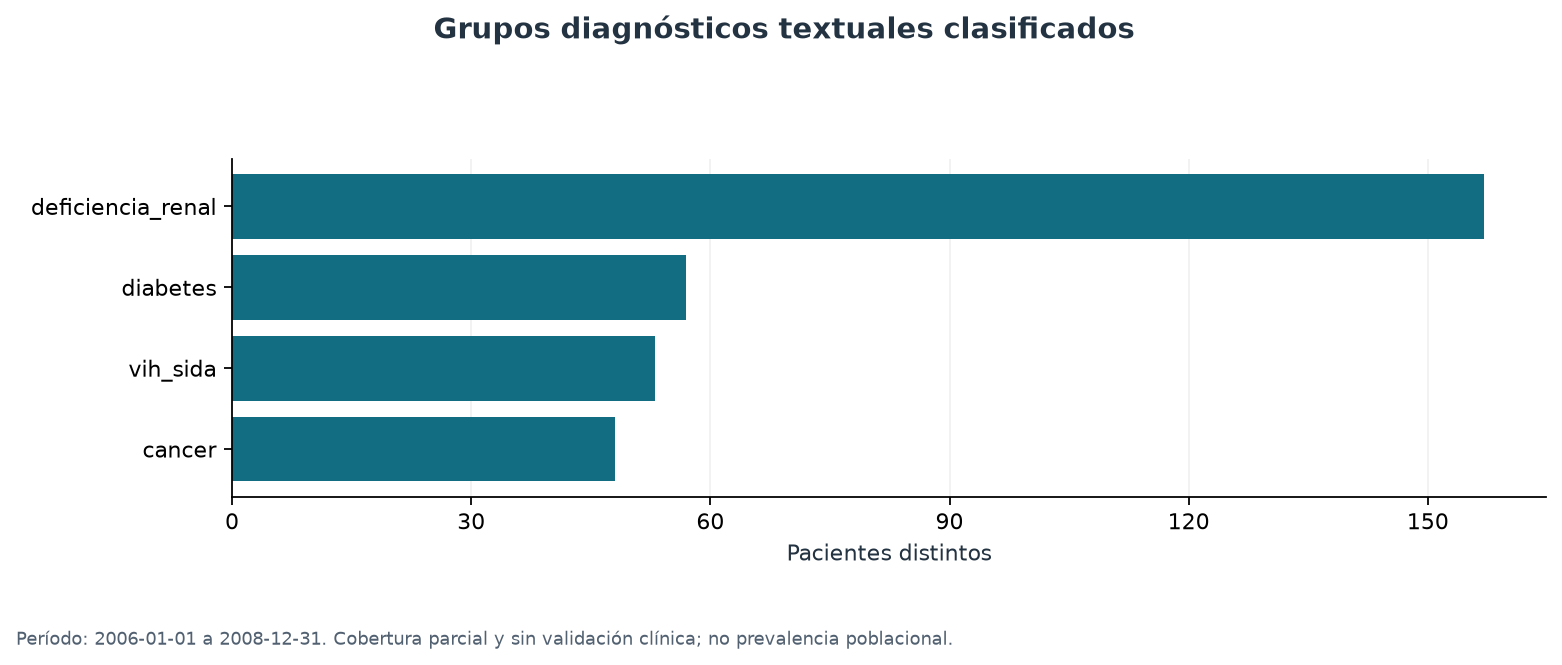

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p13_por_sexo.csv (8 registros, 4 columnas)


,grupo,segmento,eventos,pacientes
0,cancer,f,166,25
1,cancer,m,160,23
2,deficiencia_renal,m,717,87
3,deficiencia_renal,f,550,70
4,diabetes,f,92,32
5,diabetes,m,75,25
6,vih_sida,f,124,31
7,vih_sida,m,88,22


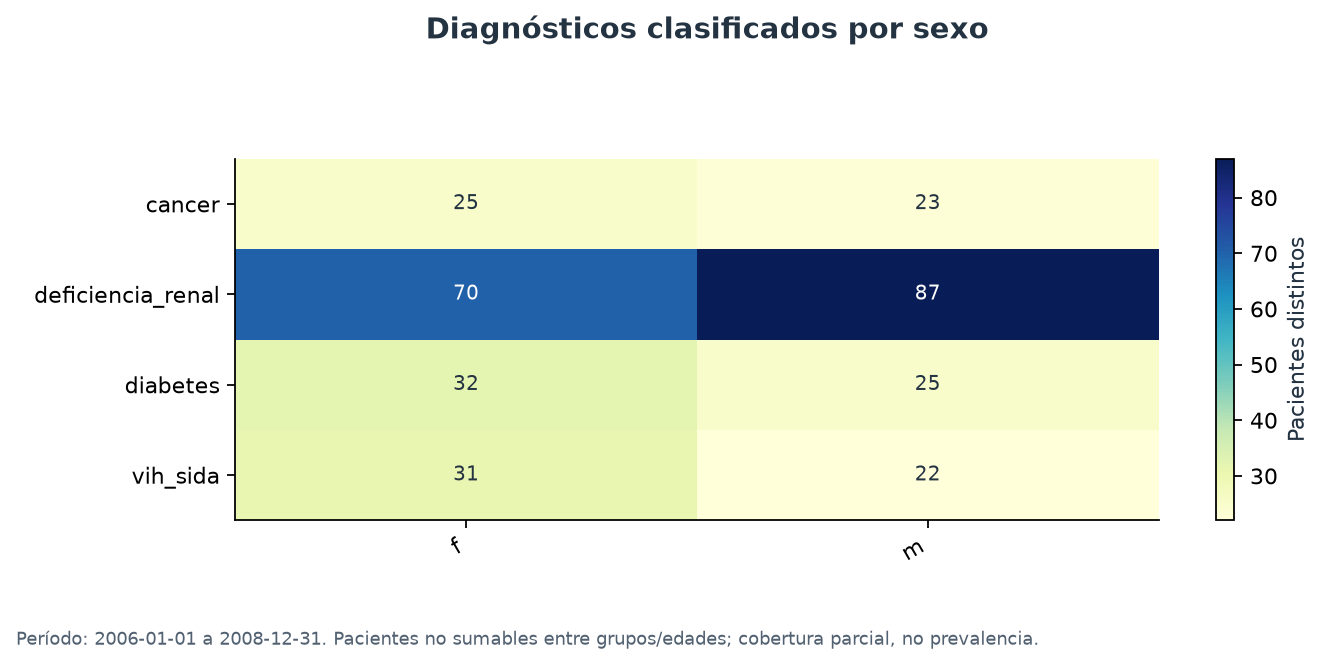

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p13_por_grupo_etario_atencion.csv (20 registros, 4 columnas)


,grupo,segmento,eventos,pacientes
0,cancer,65+,98,14
1,cancer,15-24,64,10
2,cancer,45-64,59,9
3,cancer,25-44,53,8
4,cancer,5-14,52,8
5,deficiencia_renal,45-64,333,44
6,deficiencia_renal,65+,321,40
7,deficiencia_renal,25-44,290,38
8,deficiencia_renal,15-24,202,26
9,deficiencia_renal,5-14,121,16


Tabla completa: **20 filas agregadas** en `p13_por_grupo_etario_atencion.csv`.

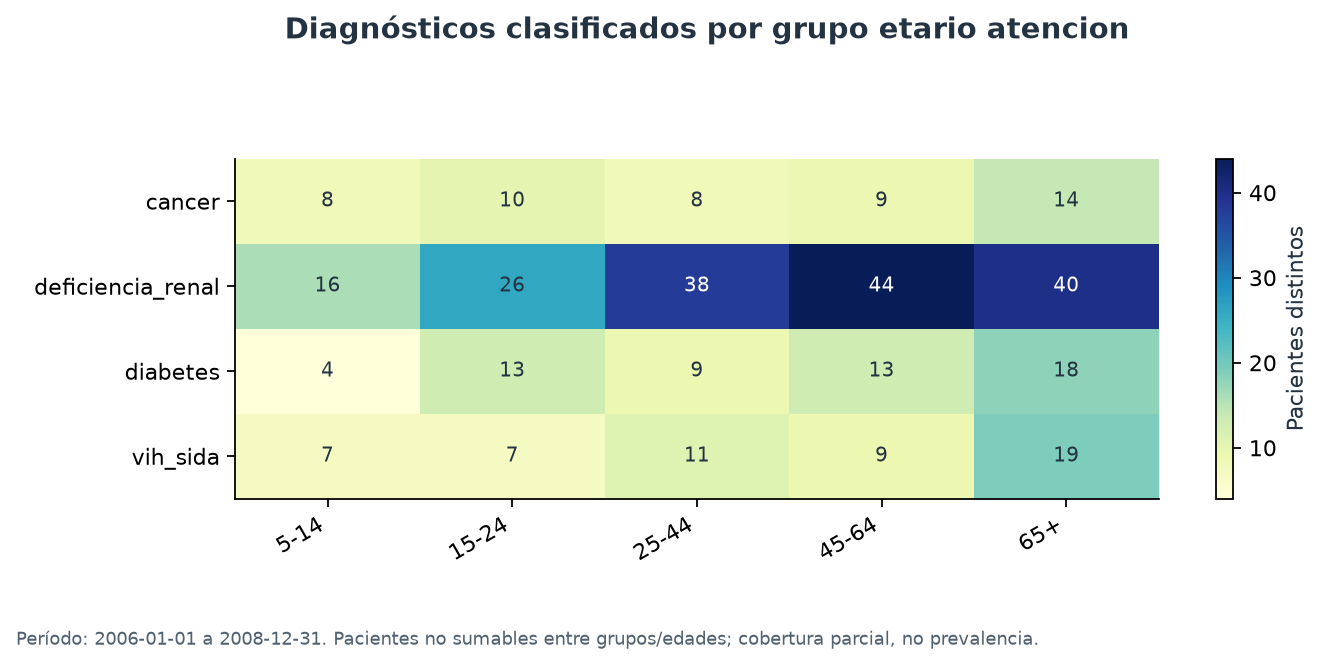

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p13_por_estrato_familiar.csv (20 registros, 4 columnas)


,grupo,segmento,eventos,pacientes
0,cancer,5,75,11
1,cancer,1,72,11
2,cancer,3,75,11
3,cancer,4,63,9
4,cancer,2,41,6
5,deficiencia_renal,3,338,41
6,deficiencia_renal,4,322,41
7,deficiencia_renal,1,253,31
8,deficiencia_renal,2,167,22
9,deficiencia_renal,5,187,22


Tabla completa: **20 filas agregadas** en `p13_por_estrato_familiar.csv`.

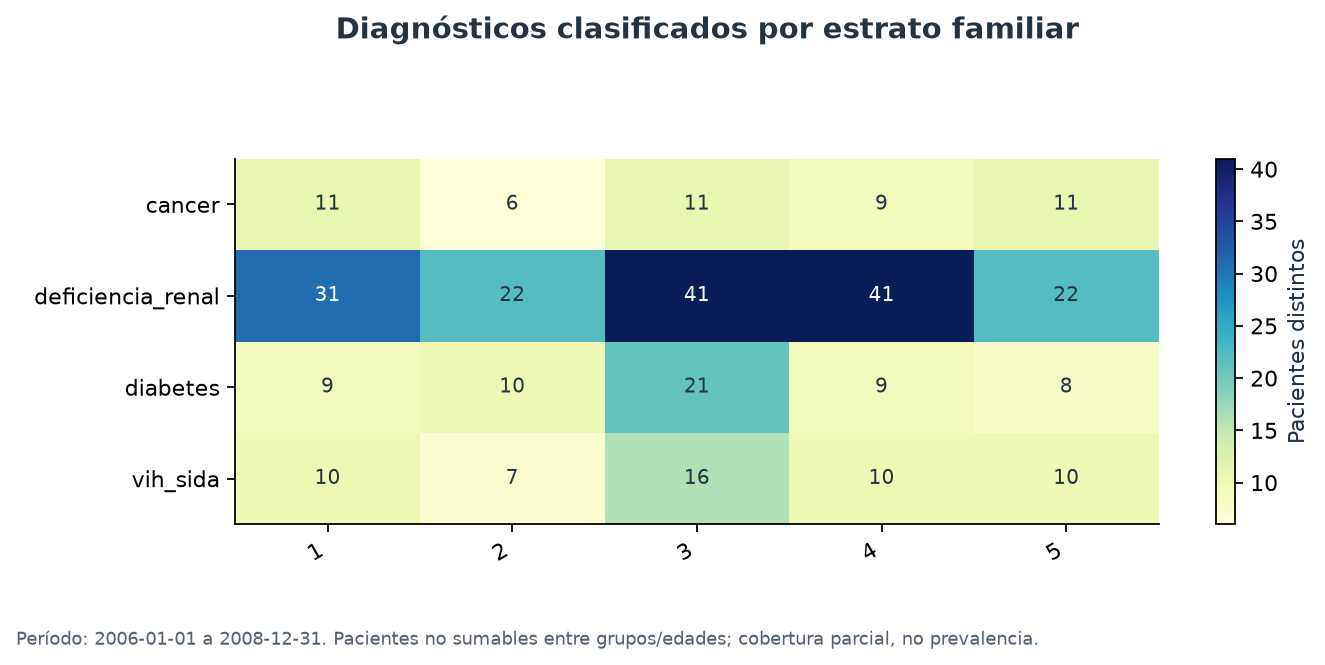

**Respuesta e interpretación.** Entre los grupos clasificados, deficiencia_renal tiene más pacientes distintos (157). Solo 1.972 de 21.207 eventos se clasifican como diagnóstico observado. Las tablas estratificadas describen ese subconjunto, no todas las enfermedades de la población.

In [16]:
# P13: diagnósticos textuales por sexo, edad y estrato.


# Mostrar cuánto del total está clasificado antes de comparar diagnósticos.
p13c = tabla(
    'p13_cobertura_clasificacion',
    consultar(
        'p13_cobertura',
        """SELECT d.clase_texto,COUNT(*) AS eventos,
 COUNT(DISTINCT a.paciente_id) AS pacientes FROM A a JOIN public.dim_diagnostico d USING(diagnostico_id)
 GROUP BY 1 ORDER BY eventos DESC""",
    ),
)

# Contar pacientes distintos únicamente en etiquetas de diagnóstico observado.
p13 = tabla(
    'p13_diagnosticos_frecuentes',
    consultar(
        'p13_frecuencia',
        """SELECT d.grupo_textual AS grupo,
 COUNT(*) AS eventos,COUNT(DISTINCT a.paciente_id) AS pacientes FROM A a JOIN public.dim_diagnostico d USING(diagnostico_id)
 WHERE d.clase_texto='diagnostico_observado' GROUP BY 1 ORDER BY pacientes DESC,eventos DESC""",
    ),
)
barras(
    'p13_frecuencia',
    p13,
    'grupo',
    'pacientes',
    'Grupos diagnósticos textuales clasificados',
    'Pacientes distintos',
    'Cobertura parcial y sin validación clínica; no prevalencia poblacional.',
)

# Repetir el mismo cálculo para cada segmentación declarada.
for campo in ['sexo', 'grupo_etario_atencion', 'estrato_familiar']:

    # Preparar cada segmentación por separado; los pacientes no son sumables entre
    # grupos.
    sub = tabla(
        'p13_por_' + campo,
        consultar(
            'p13_por_' + campo,
            f"""SELECT d.grupo_textual AS grupo,
 COALESCE(a.{campo},'desconocido') AS segmento,COUNT(*) AS eventos,COUNT(DISTINCT a.paciente_id) AS pacientes
 FROM A a JOIN public.dim_diagnostico d USING(diagnostico_id) WHERE d.clase_texto='diagnostico_observado'
 GROUP BY 1,2 ORDER BY grupo,pacientes DESC""",
        ),
    )
    if not sub.empty:
        mat = completar_matriz(
            sub.pivot(index='grupo', columns='segmento', values='pacientes')
        )
        if campo == 'grupo_etario_atencion':
            mat = mat.reindex(columns=[x for x in ORDEN_EDAD if x in mat.columns])
        fig, ax = plt.subplots(figsize=(9, max(4, 0.5 * len(mat) + 1.8)))
        im = ax.imshow(mat.to_numpy(), cmap='YlGnBu', aspect='auto')
        ax.set_xticks(range(len(mat.columns)), mat.columns, rotation=30, ha='right')
        ax.set_yticks(range(len(mat)), mat.index)
        for i in range(len(mat)):
            for j in range(len(mat.columns)):
                ax.text(
                    j,
                    i,
                    fmt(mat.iloc[i, j]),
                    ha='center',
                    va='center',
                    fontsize=9,
                    color=(
                        'white'
                        if mat.iloc[i, j] > mat.to_numpy().max() * 0.6
                        else '#243342'
                    ),
                )
        fig.colorbar(im, ax=ax, label='Pacientes distintos')
        figura(
            'p13_' + campo,
            fig,
            'Diagnósticos clasificados por ' + campo.replace('_', ' '),
            'Pacientes no sumables entre grupos/edades; cobertura parcial, no'
            ' prevalencia.',
        )
comprobar(
    'p13_cobertura_concilia_eventos',
    int(p13c.eventos.sum()) == int(calidad.iloc[0].eventos),
)

# Expresar la cobertura parcial sin presentarla como prevalencia clínica.
cl = int(
    S.filter_equal(p13c, 'clase_texto', 'diagnostico_observado', show=0)[
        'eventos'
    ].sum()
)
concluir(
    'P13',
    (
        f"Entre los grupos clasificados, {p13.iloc[0].grupo} tiene más pacientes"
        f" distintos ({fmt(p13.iloc[0].pacientes)}). "
        if not p13.empty
        else 'No hay diagnósticos clasificados observados. '
    )
    + f"Solo {fmt(cl)} de {fmt(calidad.iloc[0].eventos)} eventos se clasifican como"
    " diagnóstico observado. Las tablas estratificadas describen ese subconjunto, no"
    " todas las enfermedades de la población.",
)


## P14. Perfil de quien se cambia a otra EPS

Un cambio informado requiere EPS de destino no vacía. Se informa número de retiros y pacientes distintos,
edad al retiro y días de afiliación. Los retiros sin destino se mantienen como desconocidos; no prueban mora.
Las distribuciones del perfil usan **eventos de retiro** como denominador; no se mezclan con cotizantes activos.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `BasicsTransformOperations.add_new_column`, `CSV_Loader.save_csv`, `ConvertOperations.fill_nulls`, `DB_Extractor.execute_query`, `DataSelect.filter_equal`, `DataSelect.select_columns`, `TransformOperations.sort_by`, `etl.schema.missing (alias nulo)`.
- **Fuera del Core y motivo:** SQL calcula retiros, pacientes y medias por destino y perfiles con ventanas. Python compone la interpretación; perfil_grafico conserva pivot/Matplotlib porque el Core no renderiza estos gráficos.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `barras` | usa el Core para derivar/ordenar categorías y Matplotlib para dibujar. |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `concluir` | guarda y presenta la interpretación específica de la pregunta. |
| `consultar` | registra la consulta y delega a raw/DB_Extractor.execute_query. |
| `fmt` | formatea números con separadores de presentación; no cambia los importes exportados. |
| `grupo_sql` | genera el CASE de los grupos etarios con las reglas explícitas del taller. |
| `perfil_grafico` | usa filtros/relleno Core; conserva pivot, disposición de ejes y dibujo externo. |
| `tabla` | delega CSV a CSV_Loader.save_csv, comprueba columnas y presenta el DataFrame con IPython. |

**SQL:** las consultas de esta celda se ejecutan mediante `DB_Extractor.execute_query`, pero sus expresiones SQL pertenecen al cuaderno. `etl.warehouse` sí ofrece agregados, percentiles, cohortes y pares; se conserva el SQL de estas respuestas porque parte de la selección común cruza dimensiones sin PK/UNIQUE físicas verificables y utiliza CTE/ventanas del contrato actual. No se atribuye a todo el Core una falta de capacidad analítica ni se modifica la bodega para migrarlo.

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `int`, `str.join` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| DataFrames y matrices | `p14res.itertuples`, `p14res.retiros.sum` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p14_eps_destino.csv (4 registros, 5 columnas)


,eps_destino,retiros,pacientes,edad_media_retiro,dias_afiliacion_media
0,cafesalud,16,16,43.63,521.00
1,coomeva,13,13,47.46,568.00
2,susalud,10,10,46.30,517.50
3,comfenalco,9,9,46.00,523.56


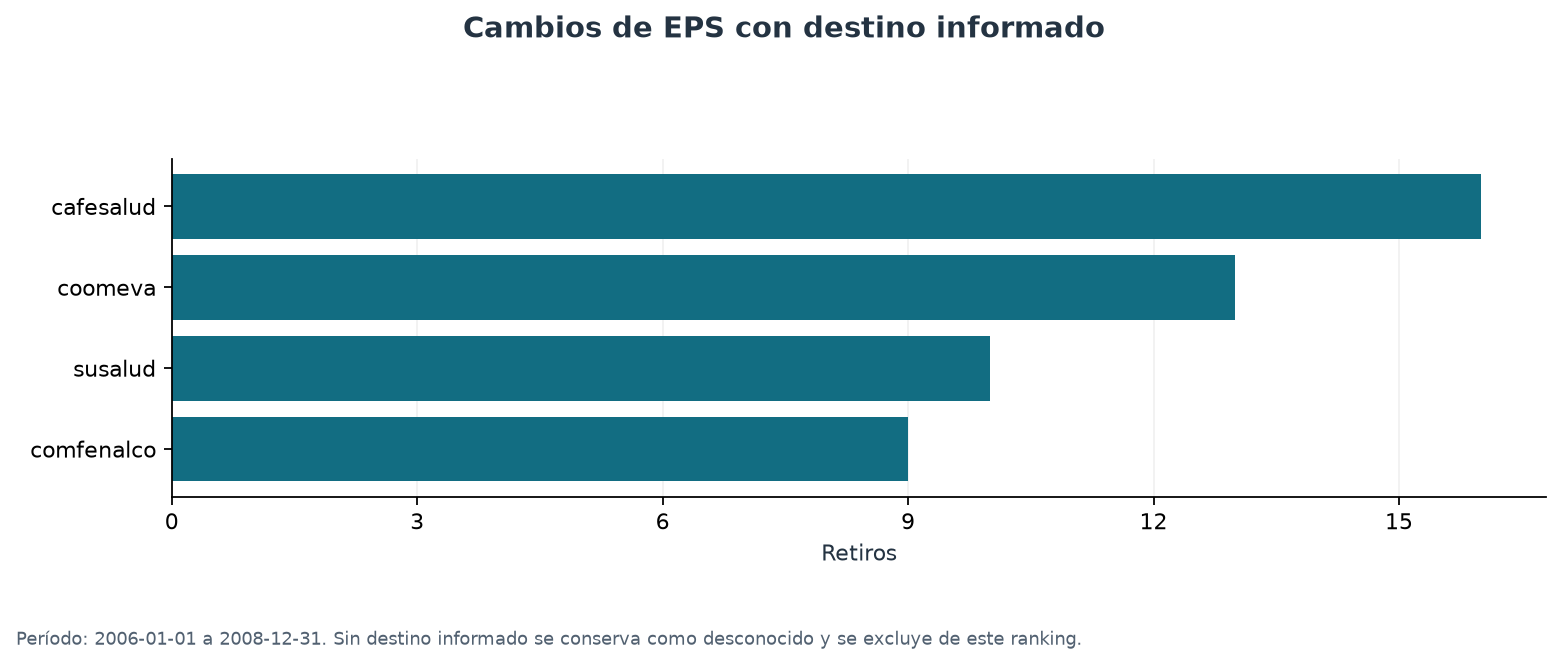

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p14_perfil_retiros.csv (21 registros, 5 columnas)


,grupo_retiro,atributo,categoria,retiros,grupo_pct
0,Cambio informado,estrato,3,29,60.42
1,Cambio informado,estrato,4,19,39.58
2,Destino desconocido,estrato,2,23,56.10
3,Destino desconocido,estrato,1,18,43.90
4,Cambio informado,grupo_etario,25-44,17,35.42
5,Cambio informado,grupo_etario,65+,14,29.17
6,Cambio informado,grupo_etario,15-24,9,18.75
7,Cambio informado,grupo_etario,45-64,8,16.67
8,Destino desconocido,grupo_etario,65+,21,51.22
9,Destino desconocido,grupo_etario,45-64,8,19.51


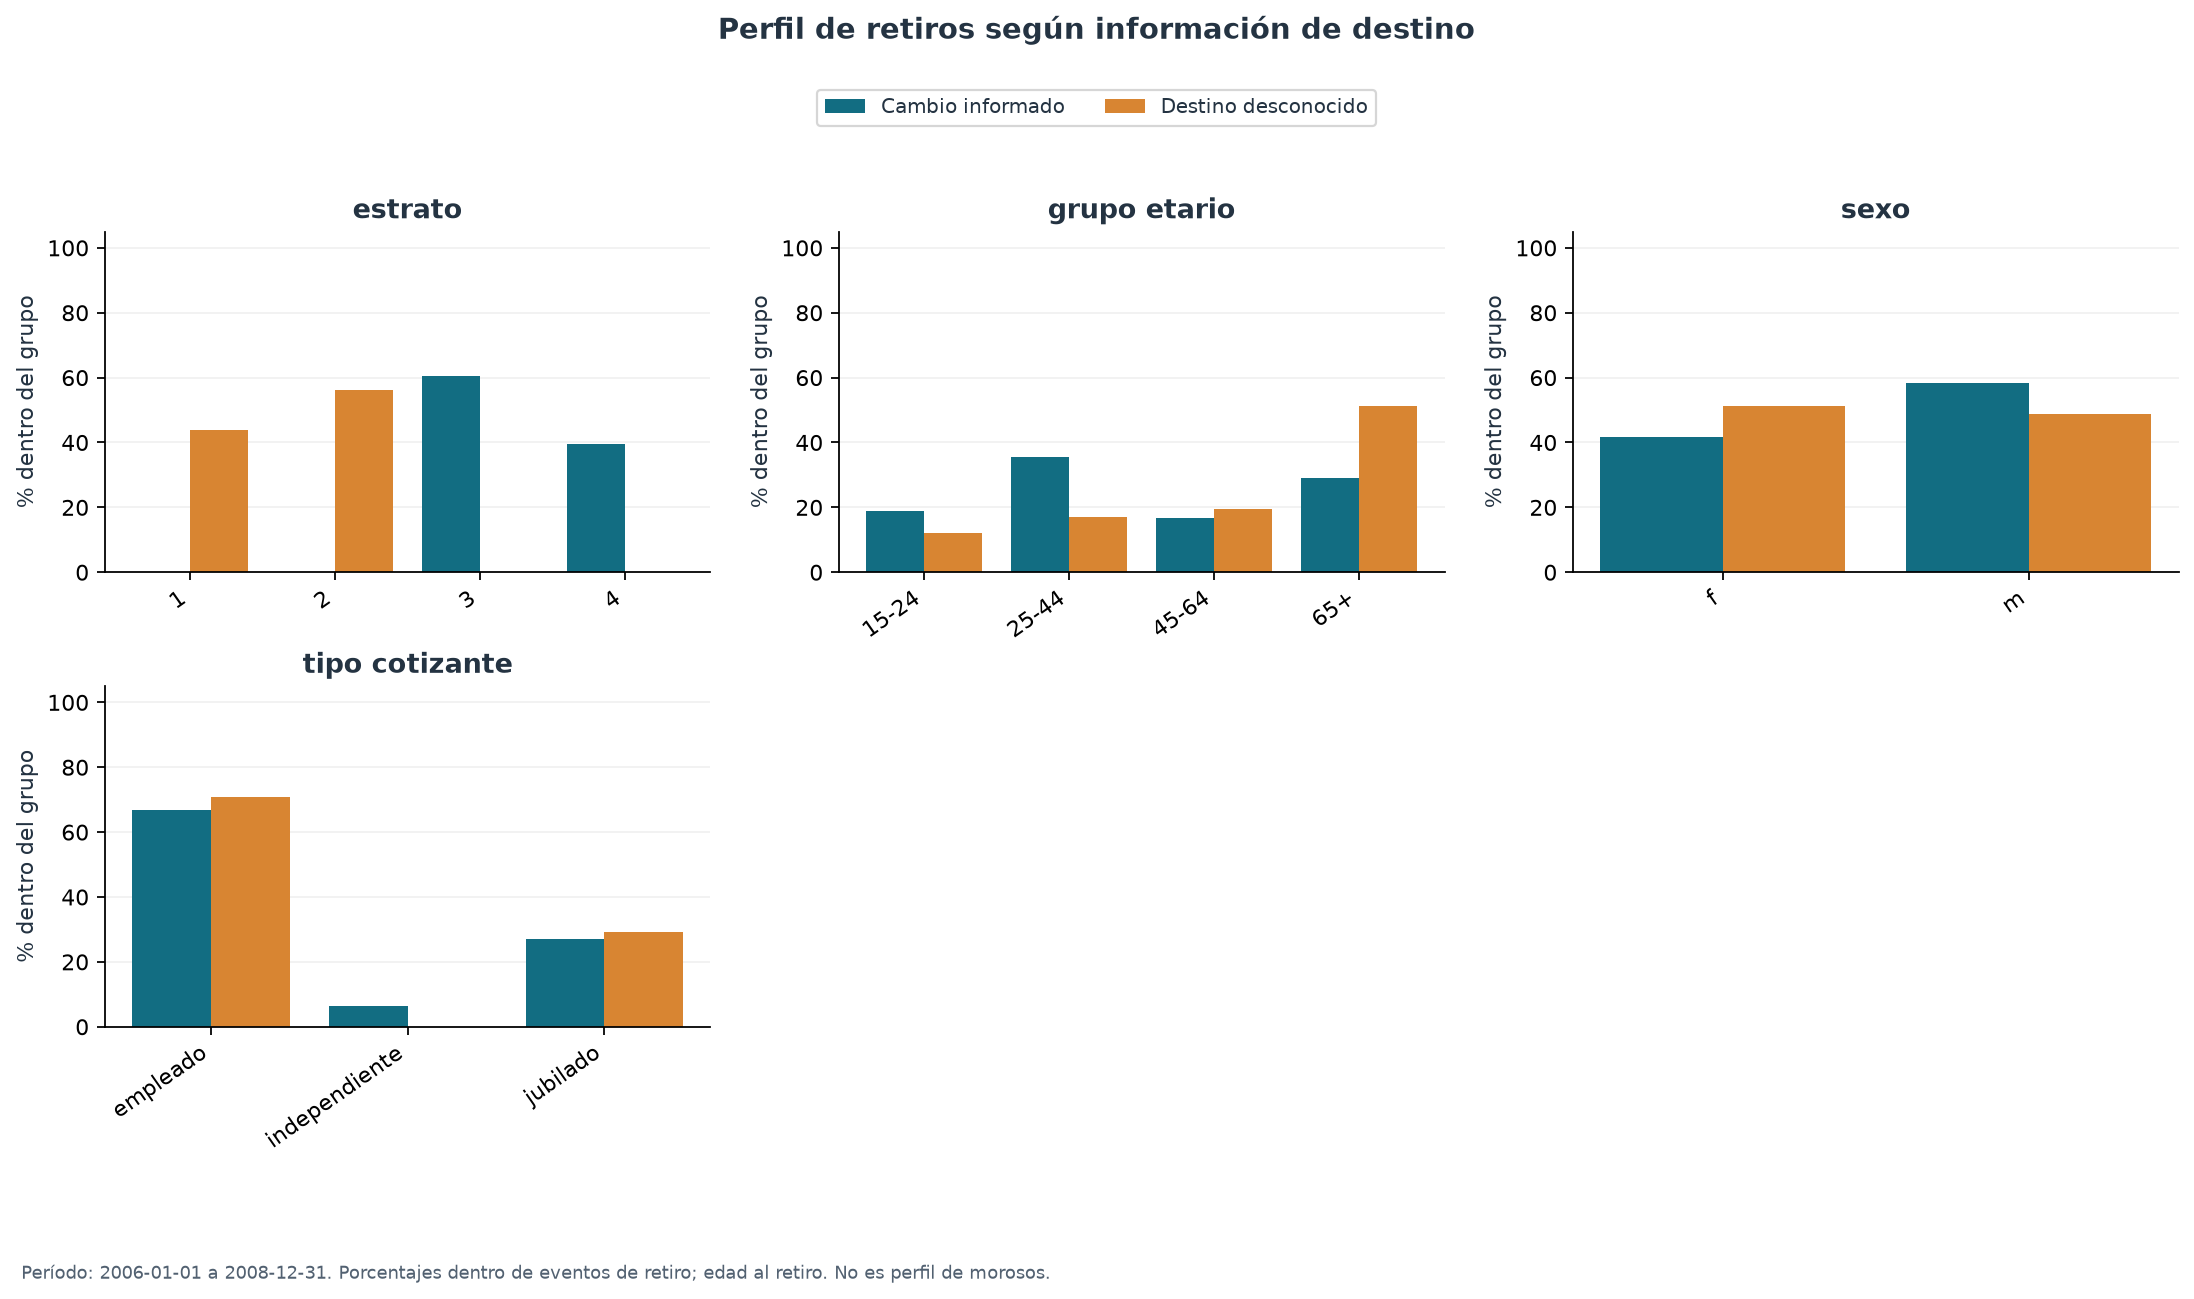

💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\p14_resumen_retiros.csv (2 registros, 5 columnas)


,grupo_retiro,retiros,pacientes,edad_media_retiro,dias_afiliacion_media
0,Cambio informado,48,48,45.67,533.48
1,Destino desconocido,41,41,59.20,441.68


**Respuesta e interpretación.** Cambio informado: 48 retiros de 48 pacientes, edad media 45,67 años y afiliación media 533,48 días; Destino desconocido: 41 retiros de 41 pacientes, edad media 59,20 años y afiliación media 441,68 días. La EPS de destino más frecuente es cafesalud, con 16 retiros. Las comparaciones son descriptivas. Destino desconocido no significa mora ni ausencia de cambio.

In [17]:
# P14: retiros con cambio de EPS informado y destino desconocido.


# Ordenar destinos informados conservando conteos, edad y duración de afiliación.
p14 = tabla(
    'p14_eps_destino',
    consultar(
        'p14_destino',
        """SELECT eps_destino,COUNT(*) AS retiros,
 COUNT(DISTINCT paciente_id) AS pacientes,ROUND(AVG(edad_al_retiro),2) AS edad_media_retiro,
 ROUND(AVG(dias_afiliacion_al_retiro),2) AS dias_afiliacion_media FROM R WHERE destino_informado
 GROUP BY 1 ORDER BY retiros DESC,eps_destino""",
    ),
)
barras(
    'p14_eps_destino',
    p14,
    'eps_destino',
    'retiros',
    'Cambios de EPS con destino informado',
    'Retiros',
    'Sin destino informado se conserva como desconocido y se excluye de este ranking.',
)

# Comparar perfiles usando eventos de retiro como denominador.
p14perfil = tabla(
    'p14_perfil_retiros',
    consultar(
        'p14_perfil',
        f""", perfiles AS (
 SELECT CASE WHEN r.destino_informado THEN 'Cambio informado' ELSE 'Destino desconocido' END AS grupo_retiro,
 v.atributo,COALESCE(v.categoria,'desconocido') AS categoria,COUNT(*) AS retiros
 FROM R r CROSS JOIN LATERAL (VALUES ('sexo',r.sexo),('estrato',r.estrato_propio),
 ('tipo_cotizante',r.tipo_cotizante_propio),('grupo_etario',{grupo_sql('r.edad_al_retiro')})) v(atributo,categoria)
 GROUP BY 1,2,3) SELECT *,ROUND(100.0*retiros/SUM(retiros) OVER(PARTITION BY grupo_retiro,atributo),2) AS grupo_pct
 FROM perfiles ORDER BY atributo,grupo_retiro,retiros DESC""",
    ),
    25,
)
perfil_grafico(
    'p14_perfil',
    p14perfil,
    'grupo_retiro',
    'Perfil de retiros según información de destino',
    'Porcentajes dentro de eventos de retiro; edad al retiro. No es perfil de morosos.',
)

# Conciliar todos los retiros, incluidos los que no informan destino.
p14res = tabla(
    'p14_resumen_retiros',
    consultar(
        'p14_resumen',
        """SELECT
 CASE WHEN destino_informado THEN 'Cambio informado' ELSE 'Destino desconocido' END AS grupo_retiro,
 COUNT(*) AS retiros,COUNT(DISTINCT paciente_id) AS pacientes,
 ROUND(AVG(edad_al_retiro),2) AS edad_media_retiro,ROUND(AVG(dias_afiliacion_al_retiro),2) AS dias_afiliacion_media
 FROM R GROUP BY 1 ORDER BY 1""",
    ),
)
comprobar('p14_retiros_concilian', int(p14res.retiros.sum()) == int(totales.retiros))
concluir(
    'P14',
    (
        '; '.join(
            f"{r.grupo_retiro}: {fmt(r.retiros)} retiros de {fmt(r.pacientes)}"
            f" pacientes, edad media {fmt(r.edad_media_retiro,2)} años y afiliación"
            f" media {fmt(r.dias_afiliacion_media,2)} días"
            for r in p14res.itertuples()
        )
        + '. '
        if not p14res.empty
        else 'No hay retiros en la selección. '
    )
    + (
        f'La EPS de destino más frecuente es {p14.iloc[0].eps_destino}, con'
        f' {fmt(p14.iloc[0].retiros)} retiros. '
        if not p14.empty
        else ''
    )
    + 'Las comparaciones son descriptivas. Destino desconocido no significa mora ni'
    ' ausencia de cambio.',
    estado='disponible_para_destino_informado',
)


## Validaciones, conclusión y exportaciones

Se comprueban denominadores, conciliación de agregados y ausencia de cambios en la bodega. El resumen final
recoge las 14 respuestas con sus límites. Cada CSV tiene grano agregado o ranking anónimo, sin identificadores
de personas; cada figura se exporta también como PNG. Los importes exactos de SQL se conservan como texto
decimal en CSV y solo se aproximan para dibujar los gráficos.

**Funciones utilizadas en la siguiente celda**

- **Core, directamente o a través de auxiliares:** `CSV_Loader.save_csv`, `DB_Extractor.close_connection`, `DB_Extractor.execute_query`, `DataSelect.filter_equal`, `DataSelect.select_columns`.
- **Fuera del Core y motivo:** Python/Decimal y pandas groupby/sum comprueban conciliaciones exactas de agregados, sin usar get_column_metrics que puede coercionar precisión. JSON/Path/datetime/version escriben manifiestos, SQL y Markdown específicos; todos los CSV y la selección final de columnas usan el Core.

**Funciones propias definidas o llamadas en esta celda**

| Función | Relación con el Core y motivo de conservarla |
| --- | --- |
| `comprobar` | registra condiciones de conciliación propias del taller. |
| `huellas_bodega` | lee mediante el Core y calcula SHA-256 de los resultados para verificar que no cambió la bodega. |

**Llamadas externas directas de esta celda** (incluye los cuerpos de funciones definidos aquí; las dependencias de auxiliares llamados se explican donde se definen; `…` omite argumentos):

| Grupo | Funciones y métodos | Por qué se conservan fuera del Core |
| --- | --- | --- |
| Python estándar y contenedores | `CONSULTAS.items`, `FIGURAS.values`, `RESULTADOS.items`, `all`, `contenido.extend`, `int`, `len`, `list`, `p03.values`, `range`, `set`, `str`, `str.join`, `sum`, `temporal.replace` | Orquestación, condiciones, iteración, construcción de SQL, parámetros y mensajes. No sustituyen una transformación tabular del Core. |
| Archivos, configuración y reproducibilidad | `SALIDA.relative_to`, `SALIDA.relative_to(…).as_posix`, `ZoneInfo`, `contextlib.redirect_stdout`, `datetime.now`, `datetime.now(…).isoformat`, `io.StringIO`, `json.dumps`, `publico.with_suffix`, `ruta.write_text`, `temporal.write_text`, `version` | Rutas, entorno, manifiestos, fechas de ejecución, versiones o hashes específicos de este proceso; el Core no publica estos manifiestos del taller. |
| DataFrames y matrices | `S.filter_equal(…)[…].sum`, `df.groupby`, `p01.itertuples`, `p06.eventos.sum`, `pd.DataFrame`, `sub[…].sum` | Construcción de evidencia, acceso/iteración de resultados, selección de máximos y presentación de matrices. Los filtros, CSV, conversiones y deduplicación con equivalencia directa se delegan al Core. head del Core devuelve texto; no hay pivot/reindex tabular equivalente en estos transformadores. |
| Dibujo e IPython | `Markdown`, `display` | Renderizado, ejes, leyendas, imágenes y visualización del notebook; el Core no ofrece renderizadores Python de gráficos ni display HTML. |
| Expresiones escalares del dominio | `Decimal`, `date` | Normalización Unicode, fechas, duraciones, claves y redondeo Decimal de las reglas explícitas. Se aplican con callables Core cuando corresponden a columnas; no son funciones propias del Core. |

In [18]:
# Validación final y exportación reproducible de las catorce respuestas.

try:
    comprobar(
        'p01_validos_y_excluidos',
        all(r.eventos == r.validos + r.excluidos for r in p01.itertuples()),
    )
    comprobar(
        'p03_segmentos_concilian_tarifas',
        all(
            sum((Decimal(x) for x in d.tarifa_total), Decimal(0))
            == (
                Decimal(p08r.tarifa_total)
                if p08r.tarifa_total is not None
                else Decimal(0)
            )
            for d in p03.values()
        ),
    )
    comprobar(
        'p03_frecuencia_no_supera_recetas',
        all(v <= int(totales.formulas) for v in frecuencias.recetas),
    )
    comprobar(
        'p06_temporadas_concilian',
        int(p06.eventos.sum()) == int(calidad.iloc[0].eventos),
    )
    for df, col, grupo in [
        (p12, 'cotizantes', 'procedencia'),
        (p14perfil, 'retiros', 'grupo_retiro'),
    ]:
        for (g, atr), sub in df.groupby([grupo, 'atributo']):
            den = (
                int(S.filter_equal(p12n, 'procedencia', g, show=0)['cotizantes'].sum())
                if grupo == 'procedencia'
                else int(
                    S.filter_equal(p14res, 'grupo_retiro', g, show=0)['retiros'].sum()
                )
            )
            comprobar('perfil_' + str(g) + '_' + atr, int(sub[col].sum()) == den)
    comprobar(
        '14_preguntas_cubiertas', set(RESULTADOS) == {f'P{i:02d}' for i in range(1, 15)}
    )
    comprobar('bodega_sin_cambios', huellas_bodega() == HUELLAS_INICIO)

    # Comparar totales con el manifiesto de carga solo para la selección completa.
    SIN_FILTROS = (
        not (TIPOS_ATENCION or IPS or DEPARTAMENTOS or SEXOS or GRUPOS_EDAD)
        and FI <= date(2006, 1, 1)
        and FF >= date(2008, 12, 31)
    )
    if SIN_FILTROS:
        comprobar(
            'global_eventos',
            int(calidad.iloc[0].eventos) == MANIFEST_CARGA['conteos']['fact_atencion'],
        )
        comprobar(
            'global_recetas',
            int(totales.formulas) == MANIFEST_CARGA['conteos']['fact_formula'],
        )
        comprobar('global_aportes', aporte == Decimal(MANIFEST_CARGA['total_aportes']))
        comprobar(
            'global_tarifas',
            Decimal(p08r.tarifa_total)
            == Decimal(MANIFEST_CARGA['total_tarifas_remisiones']),
        )
        comprobar(
            'global_esperas_negativas',
            int(calidad.iloc[0].esperas_negativas)
            == MANIFEST_CARGA['esperas_negativas'],
        )
    CSV_CORE.save_csv(
        pd.DataFrame(CONTROLES),
        str(SALIDA / 'validaciones.csv'),
        index=False,
        encoding='utf-8-sig',
        lineterminator='\n',
    )
    (SALIDA / 'consultas.sql').write_text(
        '\n\n'.join('-- ' + k + '\n' + v + ';' for k, v in CONSULTAS.items()),
        encoding='utf8',
    )
    (SALIDA / 'respuestas.json').write_text(
        json.dumps(RESULTADOS, ensure_ascii=False, indent=2), encoding='utf8'
    )

    # Exportar el estado de las preguntas sin identificadores personales.
    indice = pd.DataFrame([{'pregunta': k, **v} for k, v in RESULTADOS.items()])
    CSV_CORE.save_csv(
        indice,
        str(SALIDA / 'cobertura_preguntas.csv'),
        index=False,
        encoding='utf-8-sig',
        lineterminator='\n',
    )

    # Preparar el resumen con enlaces a las tablas y figuras de esta ejecución.
    contenido = [
        '# Resultados del taller Colombia Saludable',
        f'Período: {PERIODO}. Corte de perfiles: {CORTE}.',
        'Carga: `' + MANIFEST_CARGA['run_id'] + '`. Ejecución: `' + RUN + '`.',
        '## Respuestas',
    ]
    for pid, r in RESULTADOS.items():
        contenido.extend(['### ' + pid, r['interpretacion']])
    contenido += ['## Tablas exportadas'] + [
        '- [' + n + '.csv](' + n + '.csv)' for n in TABLAS
    ]
    contenido += ['## Figuras'] + [
        '- [' + v['titulo'] + '](' + v['archivo'] + ')' for v in FIGURAS.values()
    ]
    contenido += [
        '## Límites',
        (
            'No se conoce costo real completo, mora, ocupación real o precio de'
            ' recetas. Las clasificaciones clínicas y atribuciones de IPS son'
            ' parciales. No hay snapshot global; las huellas de bodega inicial y final'
            ' coinciden.'
        ),
    ]
    (SALIDA / 'resumen_respuestas.md').write_text(
        '\n\n'.join(contenido), encoding='utf8'
    )

    # Publicar éxito únicamente después de superar conciliaciones y la comparación de
    # huellas.
    mf = {
        'estado': 'exitoso',
        'inicio_bogota': INICIO,
        'fin_bogota': datetime.now(ZoneInfo('America/Bogota')).isoformat(),
        'run_respuestas': RUN,
        'run_carga': MANIFEST_CARGA['run_id'],
        'directorio': SALIDA.relative_to(EVIDENCIA / 'respuestas').as_posix(),
        'parametros': PARAMETROS,
        'corte_perfiles': str(CORTE),
        'preguntas': RESULTADOS,
        'consultas': len(CONSULTAS),
        'tablas': list(TABLAS),
        'figuras': FIGURAS,
        'controles_aprobados': len(CONTROLES),
        'bodega_sin_cambios': True,
        'solo_warehouse': True,
        'modo_bd': 'READ ONLY',
        'paquetes': {
            p: version(p) for p in ['pandas', 'matplotlib', 'SQLAlchemy', 'nbclient']
        },
    }
    (SALIDA / 'manifest_respuestas.json').write_text(
        json.dumps(mf, ensure_ascii=False, indent=2), encoding='utf8'
    )

    # Reemplazar el índice público al final y conservar las ejecuciones anteriores.
    publico = EVIDENCIA / 'respuestas/manifest_respuestas.json'
    temporal = publico.with_suffix('.tmp')
    temporal.write_text(json.dumps(mf, ensure_ascii=False, indent=2), encoding='utf8')
    temporal.replace(publico)
    (EVIDENCIA / 'respuestas/README.md').write_text(
        '# Respuestas del taller\n\nÚltima ejecución exitosa: `'
        + RUN
        + '`.\n\n[Resumen con tablas y figuras]('
        + mf['directorio']
        + '/resumen_respuestas.md).\n\n[Manifiesto](manifest_respuestas.json). Las'
        ' ejecuciones anteriores se conservan.\n',
        encoding='utf8',
    )
    display(S.select_columns(indice, 'pregunta', 'estado', show=0))
    display(
        Markdown(
            f'**Ejecución completa:** 14 preguntas, {len(TABLAS)} tablas,'
            f' {len(FIGURAS)} figuras y {len(CONTROLES)} controles aprobados. Bodega'
            f' sin cambios. Exportaciones: `{SALIDA.relative_to(BASE)}`.'
        )
    )
finally:

    # Cerrar conexiones incluso si una comprobación o exportación falla.
    with contextlib.redirect_stdout(io.StringIO()):
        ex.close_connection()


💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\validaciones.csv (38 registros, 2 columnas)
💾 CSV guardado exitosamente: C:\Users\cabre\Desktop\University\Tesis\python-library-etl-master\python-library-etl-master\colombia_saludable\planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1\cobertura_preguntas.csv (14 registros, 3 columnas)


,pregunta,estado
0,P01,parcial
1,P02,parcial
2,P03,parcial
3,P04,disponible_por_codigo
4,P05,disponible_con_denominador_declarado
5,P06,parcial
6,P07,parcial
7,P08,parcial
8,P09,parcial
9,P10,parcial


**Ejecución completa:** 14 preguntas, 45 tablas, 27 figuras y 38 controles aprobados. Bodega sin cambios. Exportaciones: `planes_y_evidencia\respuestas\ejecuciones\20261030T151016_4353e5d1`.